# **Loan Default Prediction**

## **Problem Definition**

### **The Context:**

 - Why is this problem important to solve?

A large share of a retail bank's profit comes from the interest it earns on home loans and home equity lines of credit. The single biggest threat to that profit is the applicant who does not repay. Every loan that becomes a non-performing asset cancels the interest earned on many good loans. Today an underwriter studies each application by hand and decides whether to approve it. This process is slow, expensive, inconsistent between underwriters and open to human error and bias. Earlier attempts to automate it used hand-written heuristics.

In the bank's own recent book of 5,960 home equity loans, **1,189 (19.9%) ended in default or serious delinquency**. The current process approved all of them. Those loans averaged about \$16,900, so the bank put roughly \$20 million of principal at risk. The data does not record recoveries. We assume that the bank recovers about half through the collateral. On that assumption, the bank lost roughly \$10 million on this book alone.

A reliable, explainable scoring model cuts those losses. It protects revenue by not declining good applicants unnecessarily. It makes decisions faster and standardises them. It also gives the bank documented reasons for every decision, which the Equal Credit Opportunity Act (ECOA) requires.

### **The objective:**

 - What is the intended goal?

Build a classification model. The model predicts, at application time, whether an applicant is likely to default on a home equity loan. Recommend to the bank which applicant attributes matter most when it approves a loan. In priority order the goals are:

1. Catch as many future defaulters as possible (recall on the default class).
2. Keep the share of wrongly declined good applicants acceptable (precision).
3. Stay interpretable enough to justify every rejection.
4. Identify the attributes that should drive approval policy.

### **The key questions:**

- What are the key questions that need to be answered?

1. What share of past applicants defaulted, and how imbalanced is the problem?
2. Which applicant attributes (debt burden, credit history, loan size, job, loan purpose, property value) separate defaulters from repayers?
3. How should we treat missing information? Is the absence of information itself a risk signal?
4. Which technique (linear vs tree-based vs ensemble) gives the best trade-off between catching defaulters and wrongly rejecting good applicants?
5. What is the right measure of success for this business problem?
6. Which model should the bank adopt, with what settings, and what rules can it communicate to applicants and regulators?

### **The problem formulation**:

- What is it that we are trying to solve using data science?

This is a **supervised binary classification** problem. Each row is a past loan with 12 attributes known at application time and a target `BAD` (1 = defaulted or seriously delinquent, 0 = repaid). We follow these steps:

1. Explore and clean the data.
2. Train a linear model (Logistic Regression) and non-linear models (Decision Tree, Bagging, Random Forest).
3. Tune the Logistic Regression, the Decision Tree and the Random Forest with cross-validated grid search.
4. Compare them on a business-driven metric (recall on defaulters, with precision as the guard-rail).
5. Choose the final configuration and its decision threshold on the expected cost of the two errors, with repeated out-of-fold predictions on the training rows.
6. Propose a final solution with the business rules that follow from it.

## **Data Description:**
The Home Equity dataset (HMEQ) contains baseline and loan performance information for 5,960 recent home equity loans. The target (BAD) is a binary variable that indicates whether an applicant has ultimately defaulted or has been severely delinquent. This adverse outcome occurred in 1,189 cases (20 percent). 12 input variables were registered for each applicant.


* **BAD:** 1 = Client defaulted on loan, 0 = loan repaid

* **LOAN:** Amount of loan approved.

* **MORTDUE:** Amount due on the existing mortgage.

* **VALUE:** Current value of the property. 

* **REASON:** Reason for the loan request. (HomeImp = home improvement, DebtCon= debt consolidation which means taking out a new loan to pay off other liabilities and consumer debts) 

* **JOB:** The type of job that loan applicant has such as manager, self, etc.

* **YOJ:** Years at present job.

* **DEROG:** Number of major derogatory reports (which indicates a serious delinquency or late payments). 

* **DELINQ:** Number of delinquent credit lines (a line of credit becomes delinquent when a borrower does not make the minimum required payments 30 to 60 days past the day on which the payments were due). 

* **CLAGE:** Age of the oldest credit line in months. 

* **NINQ:** Number of recent credit inquiries. 

* **CLNO:** Number of existing credit lines.

* **DEBTINC:** Debt-to-income ratio (all your monthly debt payments divided by your gross monthly income. This number is one way lenders measure your ability to manage the monthly payments to repay the money you plan to borrow.

## <b>Important Notes</b>

- This notebook can be considered a guide to refer to while solving the problem. The evaluation will be as per the Rubric shared for the Milestone. Unlike previous courses, it does not follow the pattern of the graded questions in different sections. This notebook would give you a direction on what steps need to be taken in order to get a viable solution to the problem. Please note that this is just one way of doing this. There can be other 'creative' ways to solve the problem and we urge you to feel free and explore them as an 'optional' exercise. 

- In the notebook, there are markdowns cells called - Observations and Insights. It is a good practice to provide observations and extract insights from the outputs.

- The naming convention for different variables can vary. Please consider the code provided in this notebook as a sample code.

- All the outputs in the notebook are just for reference and can be different if you follow a different approach.

- There are sections called **Think About It** in the notebook that will help you get a better understanding of the reasoning behind a particular technique/step. Interested learners can take alternative approaches if they want to explore different techniques. 

### **Import the necessary libraries**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme()

from sklearn.model_selection import train_test_split

from sklearn.linear_model import LogisticRegression

from sklearn import metrics
from sklearn.metrics import confusion_matrix, classification_report,accuracy_score,precision_score,recall_score,f1_score

from sklearn import tree
from sklearn.tree import DecisionTreeClassifier

from sklearn.ensemble import BaggingClassifier
from sklearn.ensemble import RandomForestClassifier

import scipy.stats as stats

from sklearn.model_selection import GridSearchCV


import warnings
warnings.filterwarnings('ignore')

### **Read the dataset**

In [2]:
hm=pd.read_csv("../data/hmeq.csv")

In [3]:
# Copying data to another variable to avoid any changes to original data
data=hm.copy()

**Reserve the test set before you fit any statistic.** We compute every statistic that prepares the data (outlier fences, imputation medians and modes, scaling) on the training rows only. We then apply it to all rows, so no information about the test applicants leaks into the models. The split is 70/30, stratified on `BAD`, with a fixed seed.

In [4]:
train_idx, test_idx = train_test_split(data.index, test_size=0.3, random_state=1, stratify=data['BAD'])
print(f"Training rows: {len(train_idx):,} | Test rows: {len(test_idx):,}")

Training rows: 4,172 | Test rows: 1,788


### **Print the first and last 5 rows of the dataset**

In [5]:
# Display first five rows
data.head()

,BAD,LOAN,MORTDUE,VALUE,REASON,JOB,YOJ,DEROG,DELINQ,CLAGE,NINQ,CLNO,DEBTINC
0,1,1100,25860.0,39025.0,HomeImp,Other,10.5,0.0,0.0,94.366667,1.0,9.0,NaN
1,1,1300,70053.0,68400.0,HomeImp,Other,7.0,0.0,2.0,121.833333,0.0,14.0,NaN
2,1,1500,13500.0,16700.0,HomeImp,Other,4.0,0.0,0.0,149.466667,1.0,10.0,NaN
3,1,1500,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,0,1700,97800.0,112000.0,HomeImp,Office,3.0,0.0,0.0,93.333333,0.0,14.0,NaN


In [6]:
# Display last 5 rows
data.tail()

,BAD,LOAN,MORTDUE,VALUE,REASON,JOB,YOJ,DEROG,DELINQ,CLAGE,NINQ,CLNO,DEBTINC
5955,0,88900,57264.0,90185.0,DebtCon,Other,16.0,0.0,0.0,221.808718,0.0,16.0,36.112347
5956,0,89000,54576.0,92937.0,DebtCon,Other,16.0,0.0,0.0,208.692070,0.0,15.0,35.859971
5957,0,89200,54045.0,92924.0,DebtCon,Other,15.0,0.0,0.0,212.279697,0.0,15.0,35.556590
5958,0,89800,50370.0,91861.0,DebtCon,Other,14.0,0.0,0.0,213.892709,0.0,16.0,34.340882
5959,0,89900,48811.0,88934.0,DebtCon,Other,15.0,0.0,0.0,219.601002,0.0,16.0,34.571519


### **Understand the shape of the dataset**

In [7]:
# Check the shape of the data
print(f"The dataset has {data.shape[0]:,} rows and {data.shape[1]} columns")

The dataset has 5,960 rows and 13 columns


**Insights:** The dataset has 5,960 loans (rows) and 13 columns: the target `BAD` and 12 input attributes. Every row is one home equity loan that the bank approved under its current process.

### **Check the data types of the columns**

In [8]:
# Check info of the data
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 5960 entries, 0 to 5959
Data columns (total 13 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   BAD      5960 non-null   int64  
 1   LOAN     5960 non-null   int64  
 2   MORTDUE  5442 non-null   float64
 3   VALUE    5848 non-null   float64
 4   REASON   5708 non-null   str    
 5   JOB      5681 non-null   str    
 6   YOJ      5445 non-null   float64
 7   DEROG    5252 non-null   float64
 8   DELINQ   5380 non-null   float64
 9   CLAGE    5652 non-null   float64
 10  NINQ     5450 non-null   float64
 11  CLNO     5738 non-null   float64
 12  DEBTINC  4693 non-null   float64
dtypes: float64(9), int64(2), str(2)
memory usage: 605.4 KB


**Insights:**
- `BAD` and `LOAN` are integers with no gaps. `REASON` and `JOB` are text (categorical). The other nine inputs are floats.
- `DEROG`, `DELINQ`, `NINQ` and `CLNO` are stored as floats but are really whole-number counts.
- Every input except `LOAN` has fewer than 5,960 non-null values, so missing values are widespread and we must treat them before modelling.

### **Check for missing values**

In [9]:
# Analyse missing values - Hint: use isnull() function
data.isnull().sum()

BAD           0
LOAN          0
MORTDUE     518
VALUE       112
REASON      252
JOB         279
YOJ         515
DEROG       708
DELINQ      580
CLAGE       308
NINQ        510
CLNO        222
DEBTINC    1267
dtype: int64

In [10]:
# Check the percentage of missing values in the each column.
(data.isnull().sum() / len(data) * 100).round(2).sort_values(ascending=False)

DEBTINC    21.26
DEROG      11.88
DELINQ      9.73
MORTDUE     8.69
YOJ         8.64
NINQ        8.56
CLAGE       5.17
JOB         4.68
REASON      4.23
CLNO        3.72
VALUE       1.88
LOAN        0.00
BAD         0.00
dtype: float64

**Insights:**
- `DEBTINC` (debt-to-income ratio) is missing in 21.3% of applications, by far the most. It is the single most important affordability measure a lender has, so its absence is suspicious in itself.
- `DEROG` (11.9%), `DELINQ` (9.7%), `MORTDUE` (8.7%), `YOJ` (8.6%) and `NINQ` (8.6%) have moderate gaps. `JOB`, `REASON`, `CLAGE`, `CLNO` and `VALUE` are missing in under 5.2% of rows.
- No column is missing enough to remove it. 44% of rows have at least one blank, so removing rows is not an option either. We will impute values and keep a flag for every imputed cell.

### **Think about it:**
- We found the total number of missing values and the percentage of missing values, which is better to consider?
- What can be the limit for % missing values in a column in order to avoid it and what are the challenges associated with filling them and avoiding them?

*The percentage is the better guide because it is independent of the dataset size. 1,267 missing values sounds large, but 21% tells us the column is still mostly populated. A common rule of thumb is to remove a column only when well over half of it is missing (say 60-70%). The gap must also carry no information. Below that share, imputation is preferable.*

*Filling values risks inventing patterns (every imputed row gets the same median). Removing rows or columns discards real applicants. Here, it would also discard the most predictive signal of all: whether the applicant supplied the information at all.*

**We can convert the object type columns to categories**

`converting "objects" to "category" reduces the data space required to store the dataframe`

### **Convert the data types**

In [11]:
cols = data.select_dtypes(['object']).columns.tolist()

#adding target variable to this list as this is an classification problem and the target variable is categorical

cols.append('BAD')

In [12]:
cols

['REASON', 'JOB', 'BAD']

In [13]:
# Changing the data type of object type column to category
for i in cols:
    data[i] = data[i].astype('category')

In [14]:
# Checking the info again and the datatype of different variable
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 5960 entries, 0 to 5959
Data columns (total 13 columns):
 #   Column   Non-Null Count  Dtype   
---  ------   --------------  -----   
 0   BAD      5960 non-null   category
 1   LOAN     5960 non-null   int64   
 2   MORTDUE  5442 non-null   float64 
 3   VALUE    5848 non-null   float64 
 4   REASON   5708 non-null   category
 5   JOB      5681 non-null   category
 6   YOJ      5445 non-null   float64 
 7   DEROG    5252 non-null   float64 
 8   DELINQ   5380 non-null   float64 
 9   CLAGE    5652 non-null   float64 
 10  NINQ     5450 non-null   float64 
 11  CLNO     5738 non-null   float64 
 12  DEBTINC  4693 non-null   float64 
dtypes: category(3), float64(9), int64(1)
memory usage: 483.3 KB


### **Analyze Summary Statistics of the dataset**

In [15]:
# Analyze the summary statistics for numerical variables
data.describe().T

,count,mean,std,min,25%,50%,75%,max
LOAN,5960.0,18607.969799,11207.480417,1100.000000,11100.000000,16300.000000,23300.000000,89900.000000
MORTDUE,5442.0,73760.817200,44457.609458,2063.000000,46276.000000,65019.000000,91488.000000,399550.000000
VALUE,5848.0,101776.048741,57385.775334,8000.000000,66075.500000,89235.500000,119824.250000,855909.000000
YOJ,5445.0,8.922268,7.573982,0.000000,3.000000,7.000000,13.000000,41.000000
DEROG,5252.0,0.254570,0.846047,0.000000,0.000000,0.000000,0.000000,10.000000
DELINQ,5380.0,0.449442,1.127266,0.000000,0.000000,0.000000,0.000000,15.000000
CLAGE,5652.0,179.766275,85.810092,0.000000,115.116702,173.466667,231.562278,1168.233561
NINQ,5450.0,1.186055,1.728675,0.000000,0.000000,1.000000,2.000000,17.000000
CLNO,5738.0,21.296096,10.138933,0.000000,15.000000,20.000000,26.000000,71.000000
DEBTINC,4693.0,33.779915,8.601746,0.524499,29.140031,34.818262,39.003141,203.312149


**Insights:**
- `LOAN` ranges from \$1,100 to \$89,900 (median \$16,300, mean \$18,608). It is right-skewed with a tail of large loans. `MORTDUE` (median \$65,019) and `VALUE` (median \$89,236) are also right-skewed. `VALUE` has an extreme maximum of \$855,909.
- `YOJ` has a median of 7 years at the current job. A quarter of applicants have 3 years or less.
- `DEROG` and `DELINQ` are zero for at least 75% of applicants. Their means (0.25 and 0.45) come from a small group with many derogatory reports or delinquent lines.
- `CLAGE` has a median of 173 months (about 14.5 years). The maximum of 1,168 months (97 years) is not plausible.
- `NINQ` has a median of 1 recent inquiry and a maximum of 17. `CLNO` has a median of 20 credit lines and a maximum of 71.
- `DEBTINC` is tightly concentrated (25th-75th percentile 29% to 39%). The maximum of 203% is impossible and a data error.

In [16]:
# Check summary for categorical data
data.describe(include=['category']).T

,count,unique,top,freq
BAD,5960,2,0,4771
REASON,5708,2,DebtCon,3928
JOB,5681,6,Other,2388


**Insights:** `BAD` has 2 levels and the majority level (0, repaid) covers 4,771 of 5,960 loans. `REASON` has 2 levels with debt consolidation the most common (3,928 of 5,708 recorded). `JOB` has 6 levels and "Other" is the most common (2,388 of 5,681 recorded).

**Let's look at the unique values in all the categorical variables**

In [17]:
# Checking the count of unique values in each categorical column
cols_cat= data.select_dtypes(['category'])

for i in cols_cat.columns:
    print('Unique values in',i, 'are :')
    print(data[i].value_counts())
    print('*'*40)

Unique values in BAD are :
BAD
0    4771
1    1189
Name: count, dtype: int64
****************************************
Unique values in REASON are :
REASON
DebtCon    3928
HomeImp    1780
Name: count, dtype: int64
****************************************
Unique values in JOB are :
JOB
Other      2388
ProfExe    1276
Office      948
Mgr         767
Self        193
Sales       109
Name: count, dtype: int64
****************************************


**Insights:** 1,189 loans defaulted against 4,771 repaid, an imbalance of roughly 1:4. Debt consolidation (3,928) is more than twice as common as home improvement (1,780). Among occupations "Other" (2,388), ProfExe (1,276) and Office (948) dominate. Sales (109) and Self-employed (193) are small groups, so we should read their default rates with care.

### **Think about it**
- The results above gave the absolute count of unique values in each categorical column. Are absolute values a good measure?
- If not, what else can be used? Try implementing that.

*Absolute counts depend on the sample size and make groups hard to compare. Shares (percentages) are easier to interpret. The cell below shows the same information as percentages.*

In [18]:
# Share of each category (percentage of non-missing values)
for i in cols_cat.columns:
    print('Percentage share of values in', i, ':')
    print((data[i].value_counts(normalize=True) * 100).round(2))
    print('*'*40)

Percentage share of values in BAD :
BAD
0    80.05
1    19.95
Name: proportion, dtype: float64
****************************************
Percentage share of values in REASON :
REASON
DebtCon    68.82
HomeImp    31.18
Name: proportion, dtype: float64
****************************************
Percentage share of values in JOB :
JOB
Other      42.03
ProfExe    22.46
Office     16.69
Mgr        13.50
Self        3.40
Sales       1.92
Name: proportion, dtype: float64
****************************************


## **Exploratory Data Analysis (EDA) and Visualization**

## **Univariate Analysis**

Univariate analysis is used to explore each variable in a data set, separately. It looks at the range of values, as well as the central tendency of the values. It can be done for both numerical and categorical variables

### **1. Univariate Analysis - Numerical Data**
Histograms and box plots help to visualize and describe numerical data. We use box plot and histogram to analyze the numerical columns.

In [19]:
# While doing uni-variate analysis of numerical variables we want to study their central tendency and dispersion.
# Let us write a function that will help us create boxplot and histogram for any input numerical variable.
# This function takes the numerical column as the input and return the boxplots and histograms for the variable.
# Let us see if this help us write faster and cleaner code.
def histogram_boxplot(feature, figsize=(12,6), bins = None):
    ''' Boxplot and histogram combined
    feature: 1-d feature array
    figsize: size of fig (default (12,6))
    bins: number of bins (default None / auto)
    '''
    f2, (ax_box2, ax_hist2) = plt.subplots(nrows = 2, # Number of rows of the subplot grid= 2
                                           sharex = True, # x-axis will be shared among all subplots
                                           gridspec_kw = {"height_ratios": (.25, .75)},
                                           figsize = figsize
                                           ) # creating the 2 subplots
    sns.boxplot(x=feature, ax=ax_box2, showmeans=True, color='violet') # boxplot will be created and a star will indicate the mean value of the column
    sns.histplot(x=feature, kde=False, ax=ax_hist2, bins=bins if bins else 'auto') # For histogram
    ax_hist2.axvline(np.nanmean(feature), color='green', linestyle='--') # Add mean to the histogram
    ax_hist2.axvline(np.nanmedian(feature), color='black', linestyle='-') # Add median to the histogram
    ax_box2.set(xlabel='')
    f2.suptitle(feature.name)
    plt.show()

#### Using the above function, let's first analyze the Histogram and Boxplot for LOAN

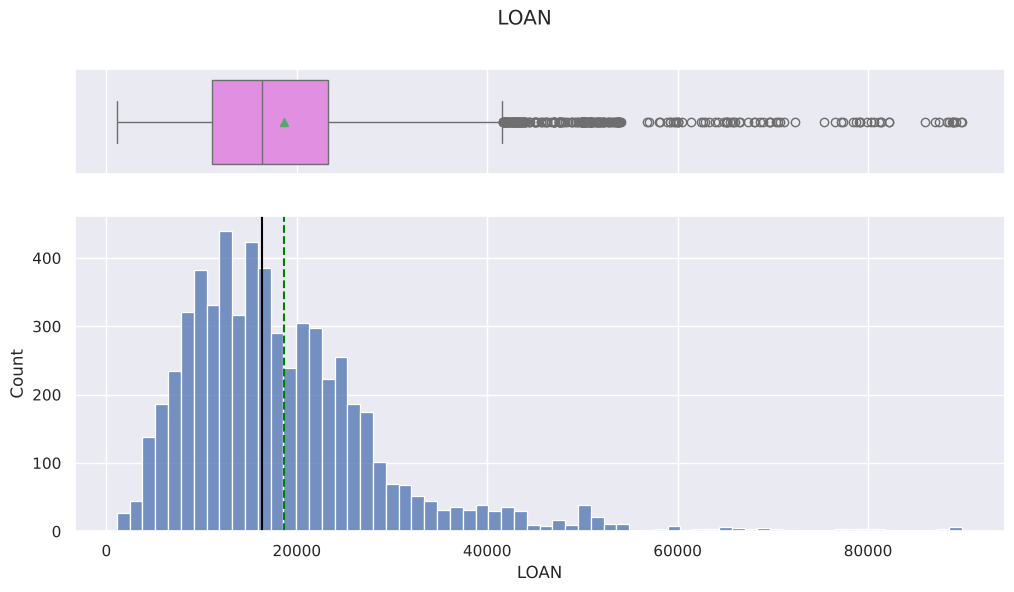

In [20]:
# Build the histogram boxplot for Loan
histogram_boxplot(data['LOAN'])

**Insights:** Loan amounts range from \$1,100 to \$89,900. Half of all loans are below \$16,300 and 75% are below \$23,300. The distribution is right-skewed with a long tail. Loans above about \$41,000 show as outliers on the boxplot. They are genuine large loans rather than data errors, so we keep them for the tree models and cap them only for the linear model.

#### **Note:** As done above, analyze Histogram and Boxplot for other variables

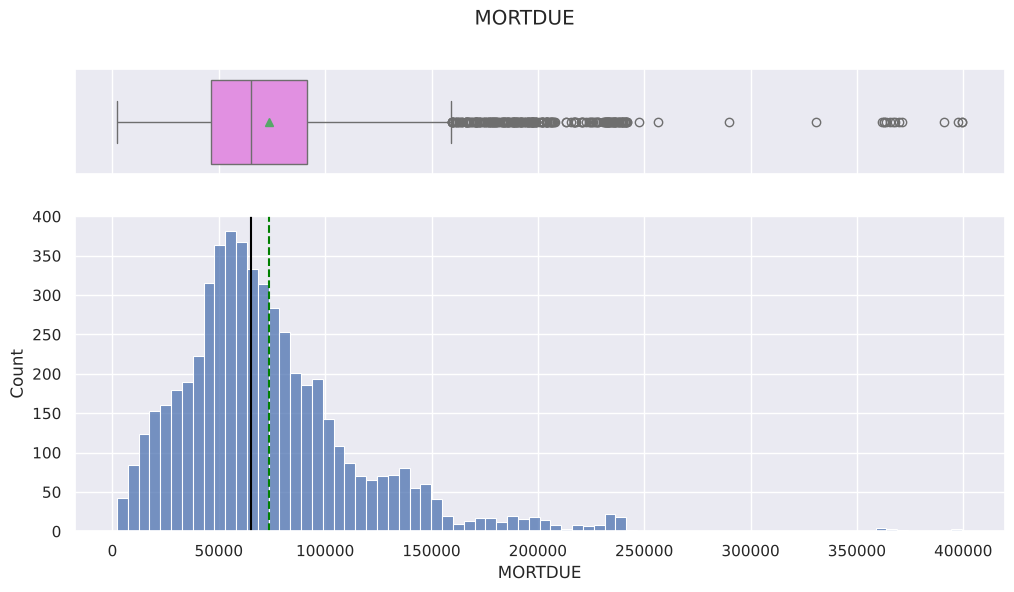

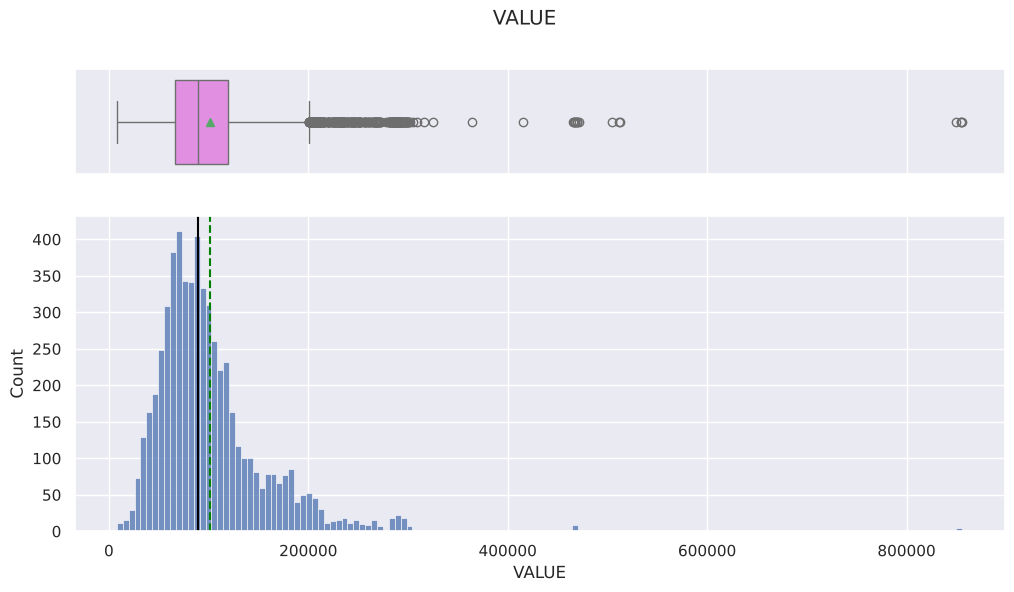

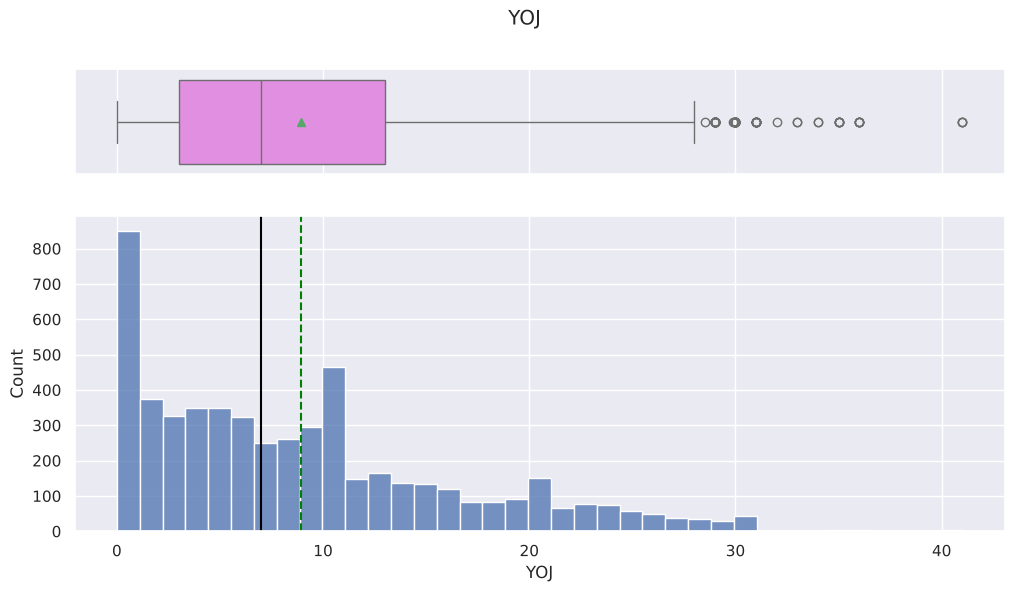

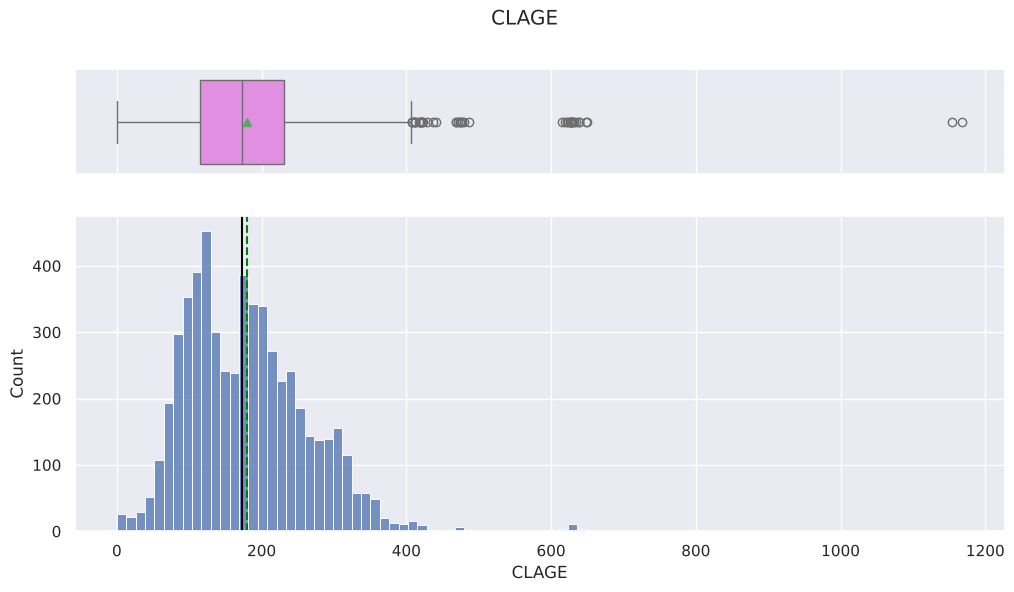

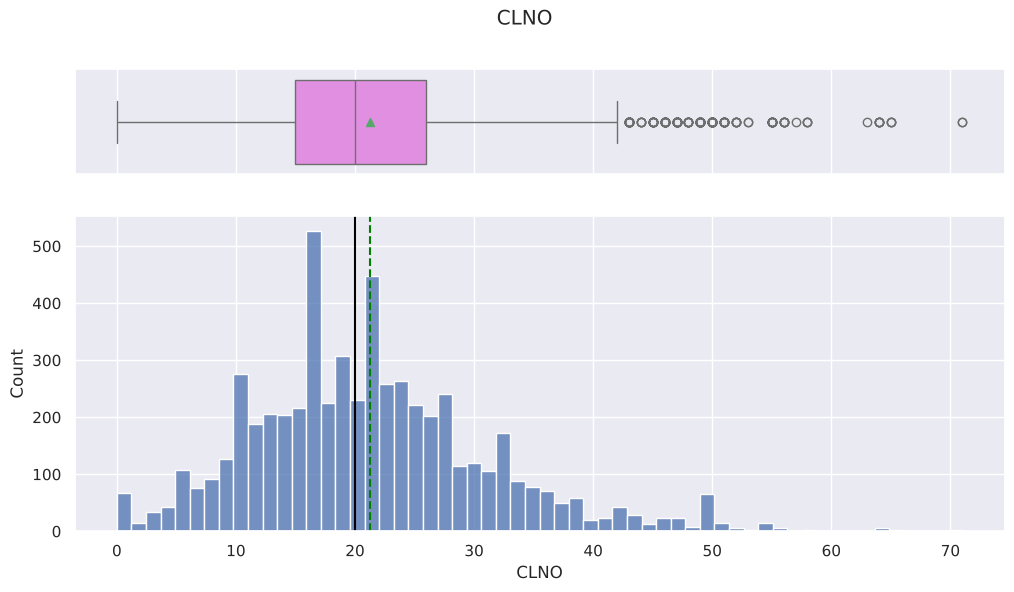

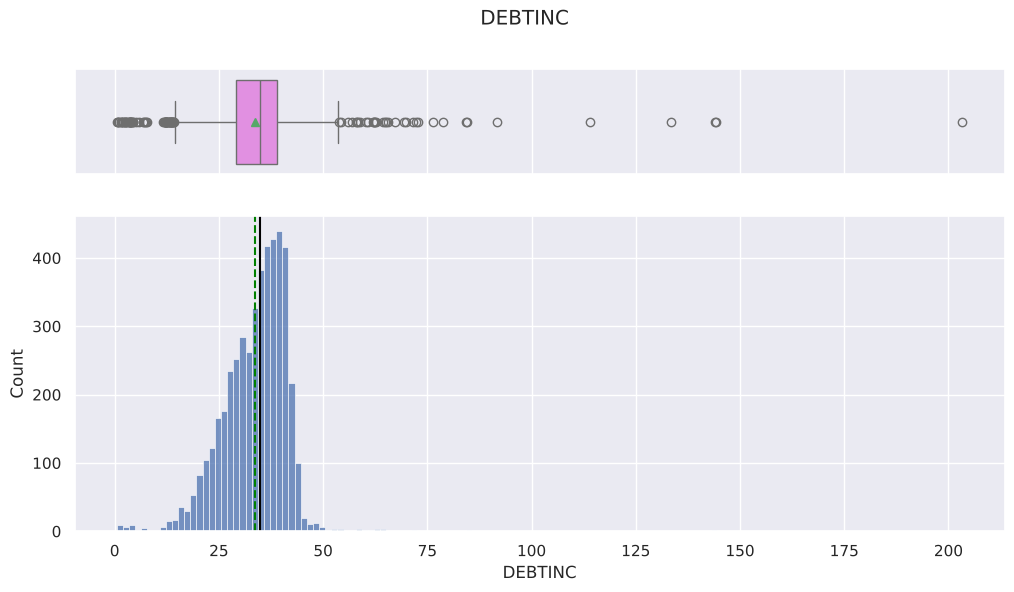

In [21]:
# Histogram and boxplot for the remaining numerical variables
for col in ['MORTDUE', 'VALUE', 'YOJ', 'CLAGE', 'CLNO', 'DEBTINC']:
    histogram_boxplot(data[col])

**Insights:**
- `MORTDUE` and `VALUE` are right-skewed with most properties between \$50,000 and \$150,000 and a few very expensive ones (VALUE up to \$855,909). Because both describe the same asset they move together (correlation 0.88, see the heatmap below), which matters for the logistic regression.
- `YOJ` is right-skewed: the most common values are 0 to 5 years, the median is 7, and a long tail reaches 41 years.
- `CLAGE` is roughly bell-shaped around 170-180 months with a right tail. A few values above 600 months and a maximum of 1,168 months are not credible.
- `CLNO` is approximately normal around 20 lines.
- `DEBTINC` is concentrated between 25% and 42%. Very few applicants have a recorded ratio above 45%, and the maximum of 203% is impossible. Note that only the 79% of applicants with a recorded ratio appear here.

### **2. Univariate Analysis - Categorical Data**

In [22]:
# Function to create barplots that indicate percentage for each category.

def perc_on_bar(plot, feature):
    '''
    plot: the axes returned by sns.countplot
    feature: categorical feature
    the function won't work if a column is passed in hue parameter
    '''

    total = len(feature.dropna()) # length of the column (non-missing values)
    for p in plot.patches:
        percentage = '{:.1f}%'.format(100 * p.get_height()/total) # percentage of each class of the category
        x = p.get_x() + p.get_width() / 2 - 0.05 # width of the plot
        y = p.get_y() + p.get_height()           # height of the plot
        plot.annotate(percentage, (x, y), size = 12) # annotate the percentage

    plt.show() # show the plot

#### Analyze Barplot for DELINQ

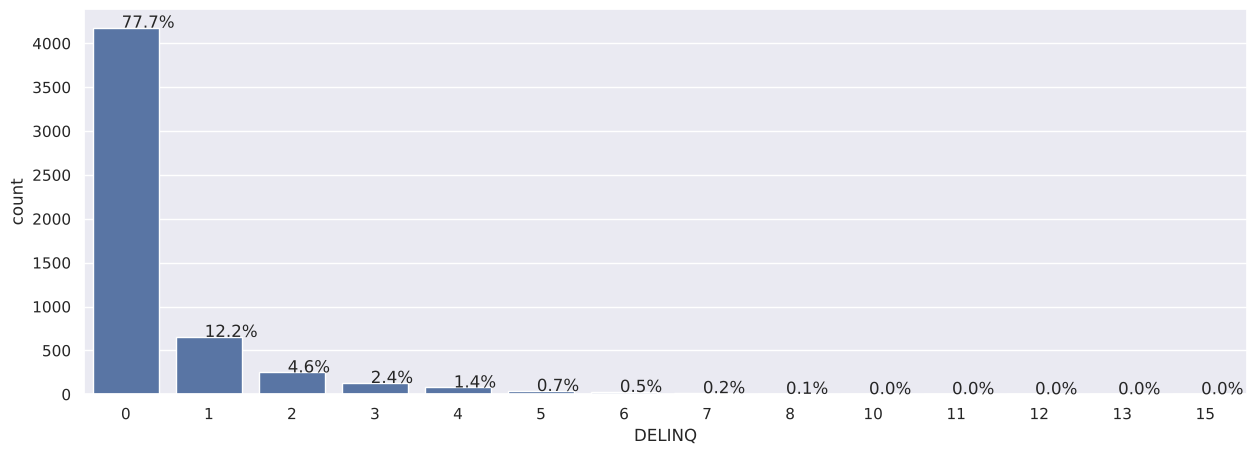

In [23]:
#Build barplot for DELINQ

plt.figure(figsize=(15,5))
ax = sns.countplot(x=data["DELINQ"].dropna().astype(int), color='#4C72B0')
perc_on_bar(ax,data["DELINQ"])

**Insights:** 78% of applicants with a recorded value have no delinquent credit line. 12% have one, 5% have two, and a small tail have three or more (up to 15). The minority with delinquencies is exactly the group a lender worries about. The bivariate analysis will show how sharply their default rate rises.

#### **Note:** As done above, analyze Histogram and Boxplot for other variables.

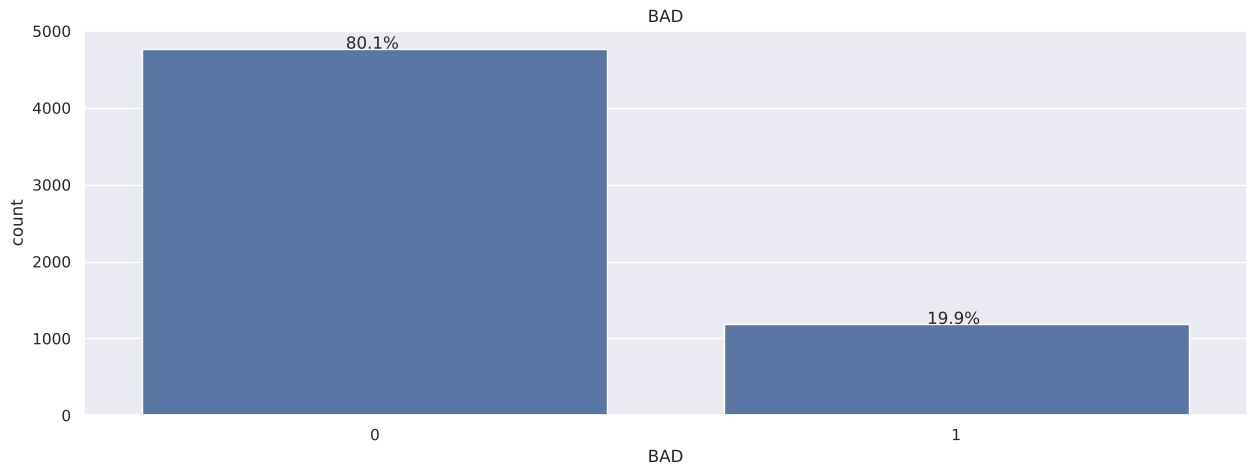

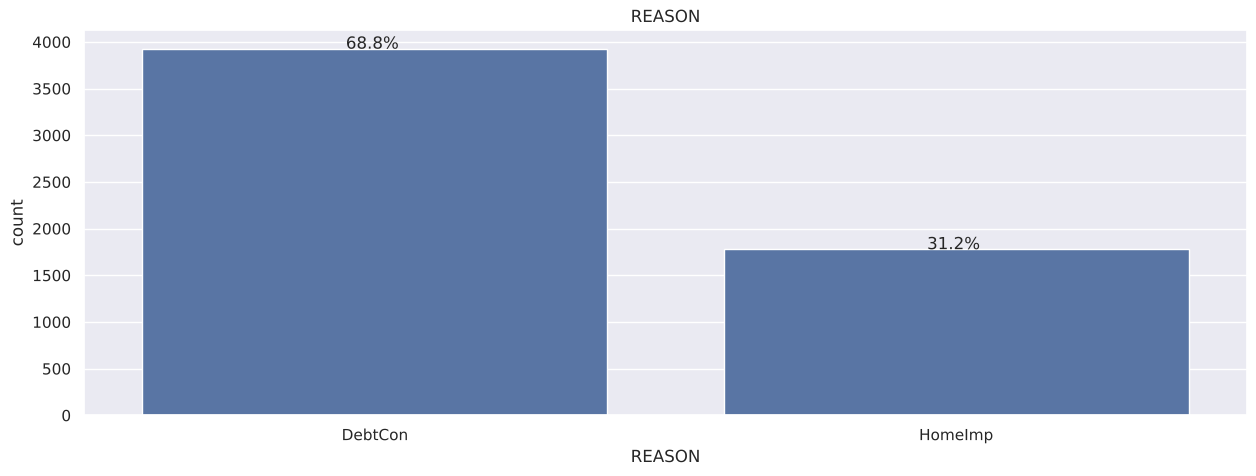

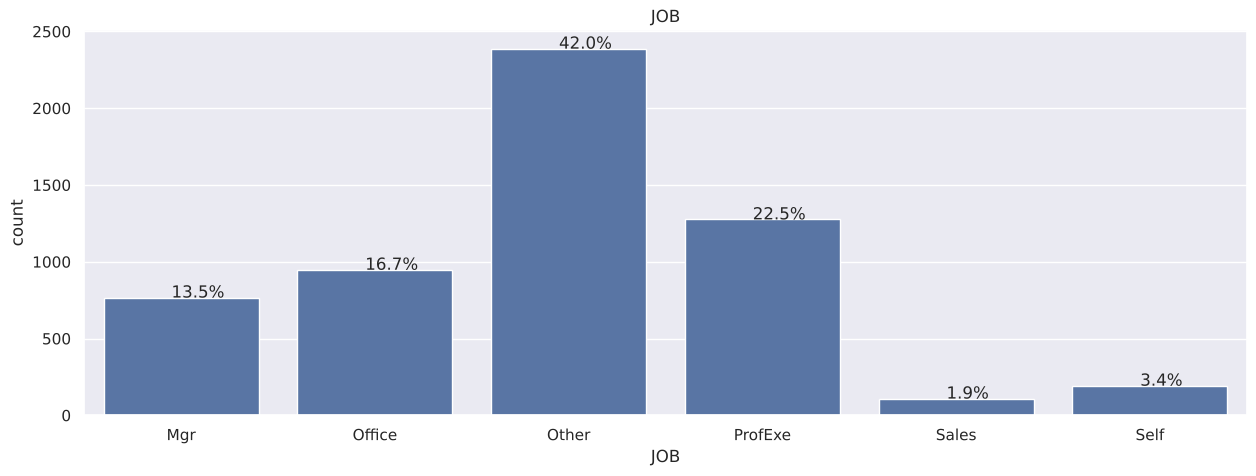

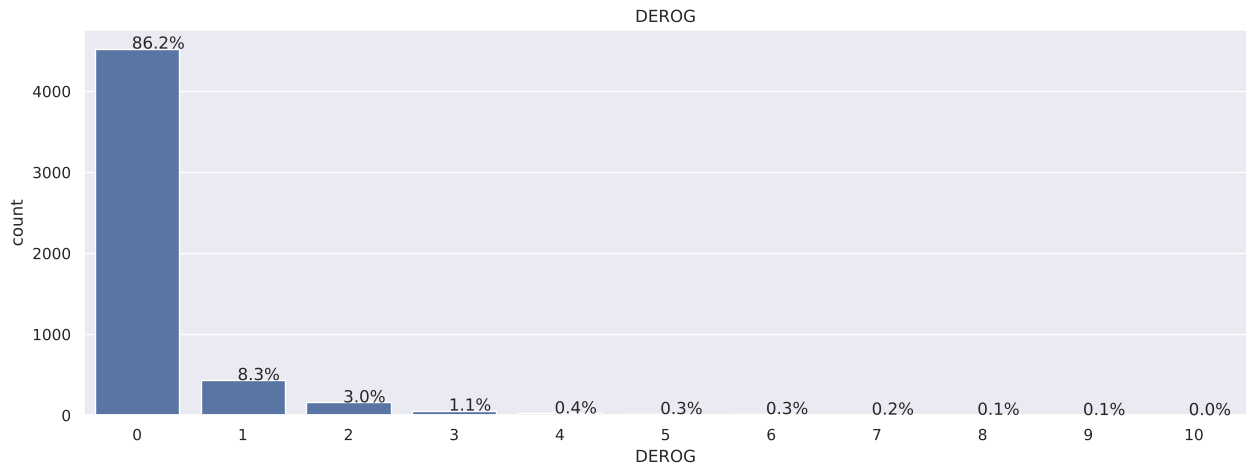

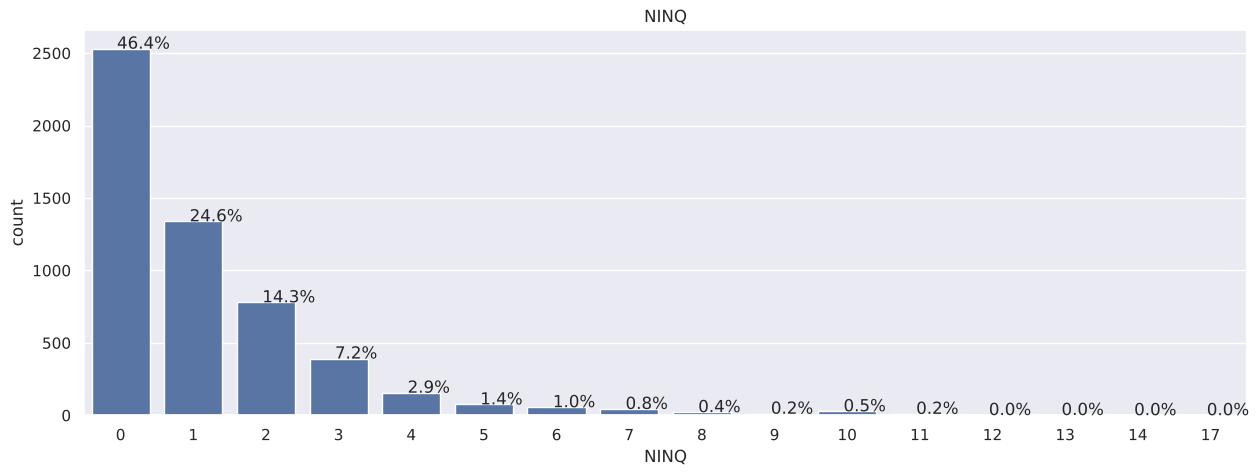

In [24]:
# Bar plots for the other categorical and count variables
for col in ['BAD', 'REASON', 'JOB', 'DEROG', 'NINQ']:
    plt.figure(figsize=(15,5))
    s = data[col].dropna()
    if str(s.dtype) != 'category':
        s = s.astype(int)
    ax = sns.countplot(x=s, color='#4C72B0')
    plt.title(col)
    perc_on_bar(ax, data[col])

**Insights:**
- `BAD`: 80% of applicants repaid their loans and 20% defaulted. The imbalance is moderate. We handle it inside the models (class weights while we build them, the decision threshold when we choose the final one). Recall rather than accuracy is the measure of success.
- `REASON`: debt consolidation (69%) is far more common than home improvement (31%).
- `JOB`: "Other" (42%) is the most common occupation, then ProfExe (22%) and Office (17%). Sales (2%) and Self (3%) are small.
- `DEROG`: among applicants with a record, 86% have no major derogatory report. `NINQ`: 46% of those with a record have no recent inquiry, 25% have one, and a tail have five or more.

## **Bivariate Analysis**

### **Bivariate Analysis: Continuous and Categorical Variables**

#### Analyze BAD vs Loan

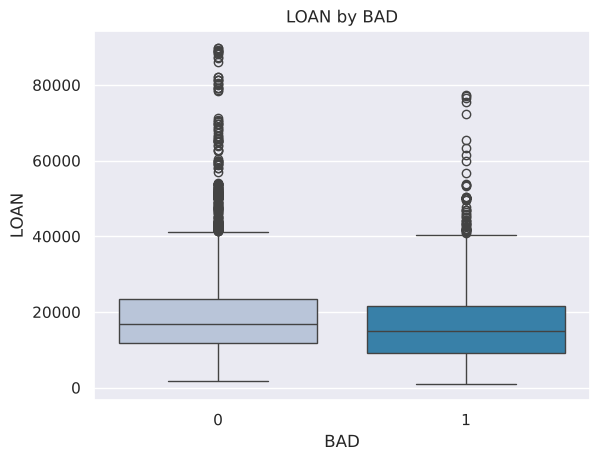

In [25]:
sns.boxplot(x=data["BAD"],y=data['LOAN'],palette="PuBu")
plt.title('LOAN by BAD')
plt.show()

**Insights:** Defaulters borrowed less on average (median \$14,900) than repayers (median \$16,900). The difference is real but modest, so loan size alone is not a strong separator. The default rate by loan band (added below) shows that loans under \$5,000 default 57% of the time, almost three times the average. A small requested amount is not a sign of low risk.

#### **Note:** As shown above, perform Bi-Variate Analysis on different pair of Categorical and continuous variables

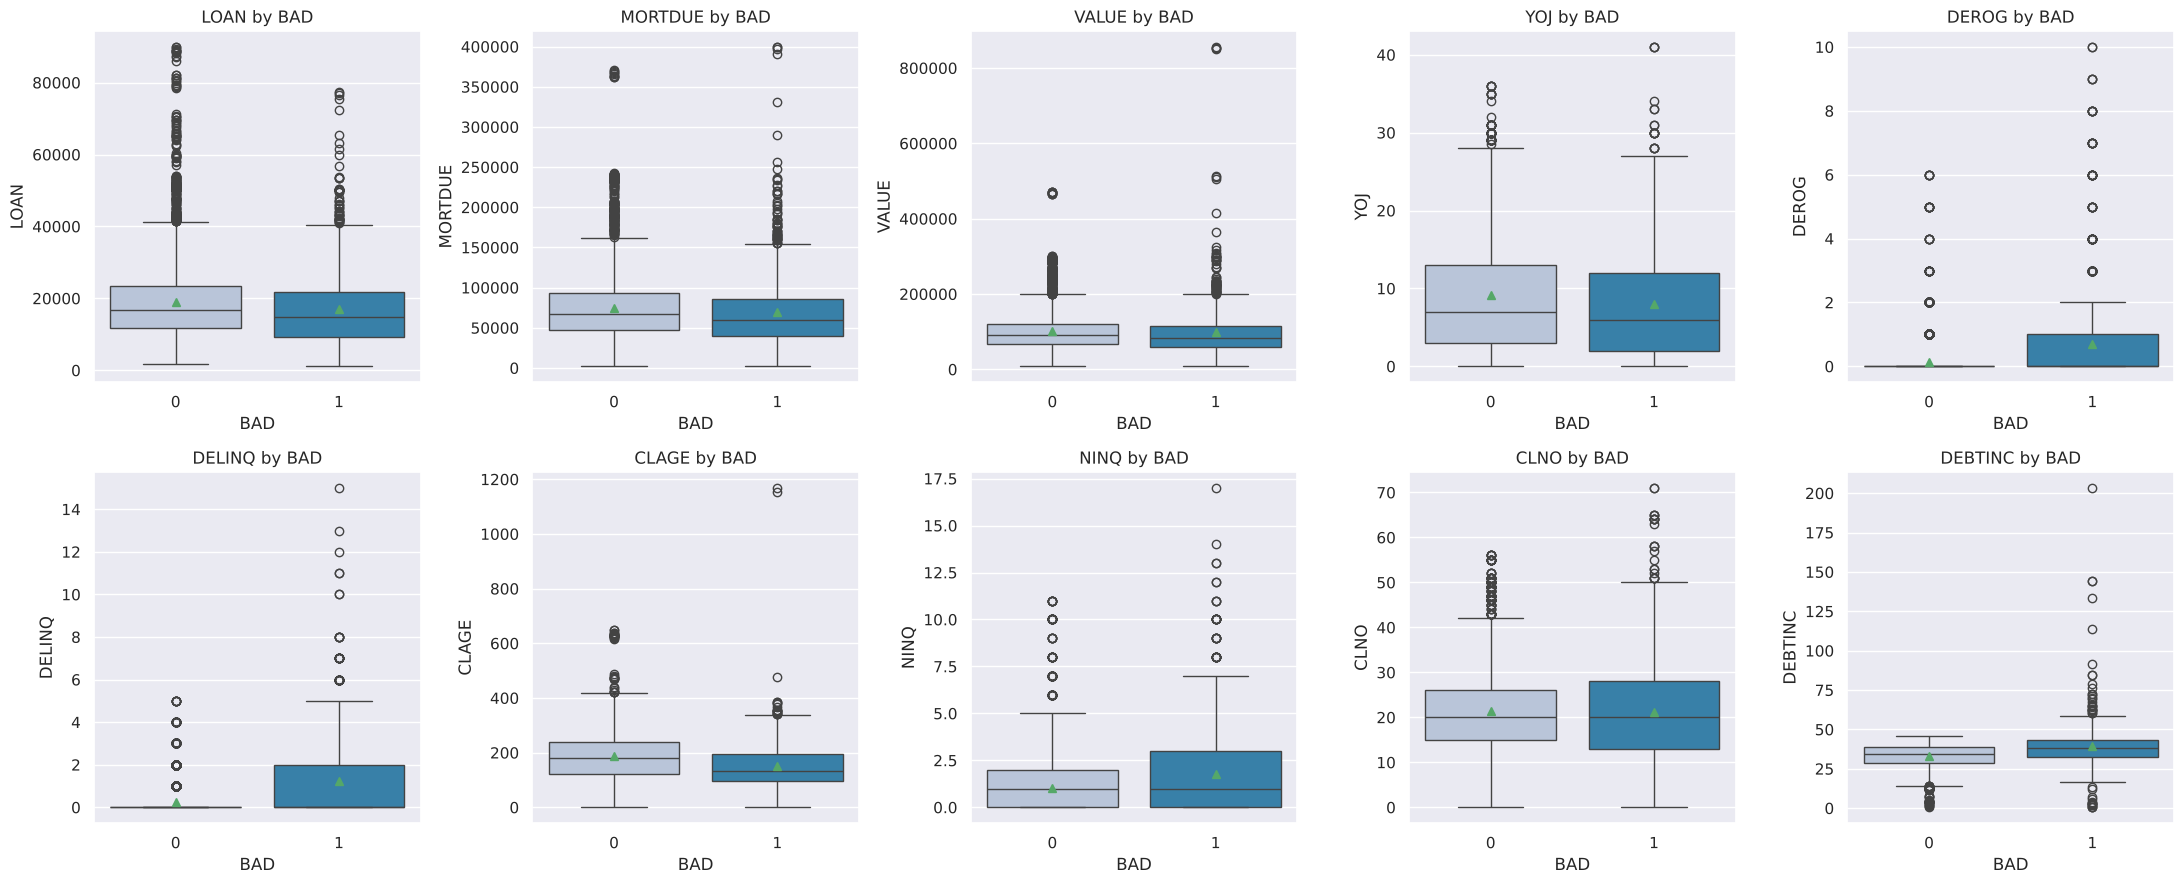

BAD                         0             1
LOAN    mean     19028.107315  16922.119428
        median   16900.000000  14900.000000
MORTDUE mean     74829.249055  69460.452973
        median   66839.000000  60279.000000
VALUE   mean    102595.921018  98172.846227
        median   90659.000000  82000.000000
YOJ     mean         9.154941      8.027802
        median       7.000000      6.000000
DEROG   mean         0.134217      0.707804
        median       0.000000      0.000000
DELINQ  mean         0.245133      1.229185
        median       0.000000      0.000000
CLAGE   mean       187.002355    150.190183
        median     180.415787    132.866667
NINQ    mean         1.032749      1.782765
        median       1.000000      1.000000
CLNO    mean        21.317036     21.211268
        median      20.000000     20.000000
DEBTINC mean        33.253129     39.387645
        median      34.541671     38.079762

In [26]:
# Boxplots of every numerical variable by BAD, plus mean and median by class
num_cols = ['LOAN', 'MORTDUE', 'VALUE', 'YOJ', 'DEROG', 'DELINQ', 'CLAGE', 'NINQ', 'CLNO', 'DEBTINC']
fig, axes = plt.subplots(2, 5, figsize=(22, 9))
for ax, col in zip(axes.flatten(), num_cols):
    sns.boxplot(x=data["BAD"], y=data[col], ax=ax, palette="PuBu", showmeans=True)
    ax.set_title(f"{col} by BAD")
plt.tight_layout()
plt.show()

data.groupby("BAD", observed=True)[num_cols].agg(["mean", "median"]).T

In [27]:
# Default rate by band of the three most informative continuous variables
def default_rate_by_band(col, bins):
    banded = pd.cut(data[col], bins=bins, include_lowest=True)
    return data.groupby(banded, observed=True)["BAD"].agg(
        default_rate=lambda s: (s.astype(int).mean() * 100).round(1), applicants="count")

print("Default rate (%) by DEBTINC band")
print(default_rate_by_band("DEBTINC", [0, 20, 30, 35, 40, 45, 50, 210]))
print("\nDefault rate (%) by CLAGE band (months)")
print(default_rate_by_band("CLAGE", [0, 60, 120, 180, 240, 300, 1200]))
print("\nDefault rate (%) by LOAN band ($)")
print(default_rate_by_band("LOAN", [0, 5000, 10000, 15000, 20000, 30000, 90000]))

Default rate (%) by DEBTINC band
                default_rate  applicants
DEBTINC                                 
(-0.001, 20.0]          10.6         198
(20.0, 30.0]             4.4        1150
(30.0, 35.0]             6.0        1046
(35.0, 40.0]             7.0        1405
(40.0, 45.0]            11.2         810
(45.0, 50.0]            87.2          39
(50.0, 210.0]          100.0          45

Default rate (%) by CLAGE band (months)
                 default_rate  applicants
CLAGE                                    
(-0.001, 60.0]           44.0         184
(60.0, 120.0]            26.2        1389
(120.0, 180.0]           22.8        1470
(180.0, 240.0]           15.3        1347
(240.0, 300.0]            9.3         739
(300.0, 1200.0]          10.7         523

Default rate (%) by LOAN band ($)
                    default_rate  applicants
LOAN                                        
(-0.001, 5000.0]            57.2         194
(5000.0, 10000.0]           25.1        1017
(10000

In [28]:
# Are the differences statistically significant? Mann-Whitney U tests for the amounts, chi-square tests for the categories
rows = []
for col in ['LOAN', 'MORTDUE', 'VALUE', 'DEBTINC', 'CLAGE']:
    a = data.loc[data['BAD'] == 1, col].dropna(); b = data.loc[data['BAD'] == 0, col].dropna()
    rows.append({'variable': col, 'median_defaulters': a.median(), 'median_repayers': b.median(), 'test': 'Mann-Whitney U', 'p_value': stats.mannwhitneyu(a, b).pvalue})
for col in ['REASON', 'JOB']:
    chi2, p, dof, _ = stats.chi2_contingency(pd.crosstab(data[col], data['BAD']))
    rows.append({'variable': col, 'median_defaulters': np.nan, 'median_repayers': np.nan, 'test': 'Chi-square', 'p_value': p})
pd.DataFrame(rows)

,variable,median_defaulters,median_repayers,test,p_value
0,LOAN,14900.000000,16900.000000,Mann-Whitney U,5.871385e-17
1,MORTDUE,60279.000000,66839.000000,Mann-Whitney U,1.610660e-08
2,VALUE,82000.000000,90659.000000,Mann-Whitney U,4.448639e-09
3,DEBTINC,38.079762,34.541671,Mann-Whitney U,1.109410e-23
4,CLAGE,132.866667,180.415787,Mann-Whitney U,1.445805e-44
5,REASON,NaN,NaN,Chi-square,4.576182e-03
6,JOB,NaN,NaN,Chi-square,3.306676e-16


**Insights (numerical variables vs BAD):**
- `DEROG` and `DELINQ` separate the classes most: defaulters average 0.71 derogatory reports vs 0.13, and 1.23 delinquent lines vs 0.25, about five times higher.
- `CLAGE`: defaulters have a much shorter credit history (median 133 months vs 180). Under 5 years of history the default rate is 44%. Above 20 years it is about 10%.
- `DEBTINC` is a cliff, not a slope. Between 20% and 40% the default rate is only 4-7% (11% in the small group below 20%). Between 40% and 45% it is 11%. Above 45% it is 87%, and above 50% it is 100%. A 45% threshold is a natural policy rule.
- `NINQ`: defaulters made more recent inquiries (mean 1.78 vs 1.03).
- `VALUE` and `MORTDUE` are only slightly lower for defaulters (medians \$82,000 vs \$90,659 and \$60,279 vs \$66,839). `YOJ` and `CLNO` barely differ.
- The differences in `LOAN`, `MORTDUE` and `VALUE` are statistically significant (Mann-Whitney p < 0.001) but small in practice. `REASON` relates to default (chi-square p = 0.005) but weakly. `JOB` relates to default strongly (p < 0.001). Significance says the pattern is real. The band tables say where it is large enough to act on.

### **Bivariate Analysis: Two Continuous Variables**

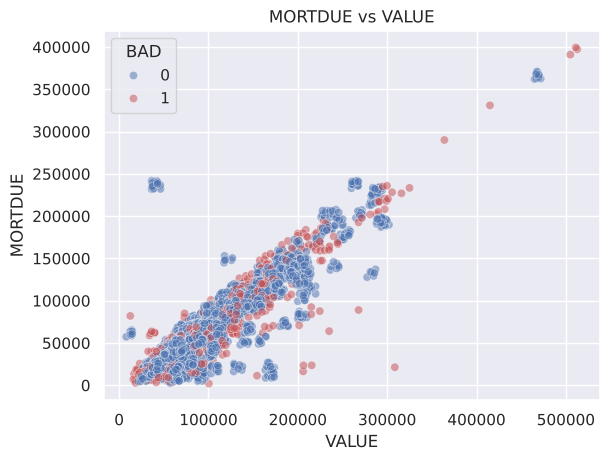

In [29]:
sns.scatterplot(x=data["VALUE"], y=data['MORTDUE'], hue=data['BAD'], alpha=0.5, palette=["#4C72B0", "#C44E52"])
plt.title('MORTDUE vs VALUE')
plt.show()

**Insights:** Mortgage balance and property value lie close to a straight line (the balance is typically 60-80% of the value). The two therefore carry much the same information. Defaulters are scattered throughout rather than clustered. This shows that these two amounts alone do not separate the classes.

#### **Note:** As shown above, perform Bivariate Analysis on different pairs of continuous variables

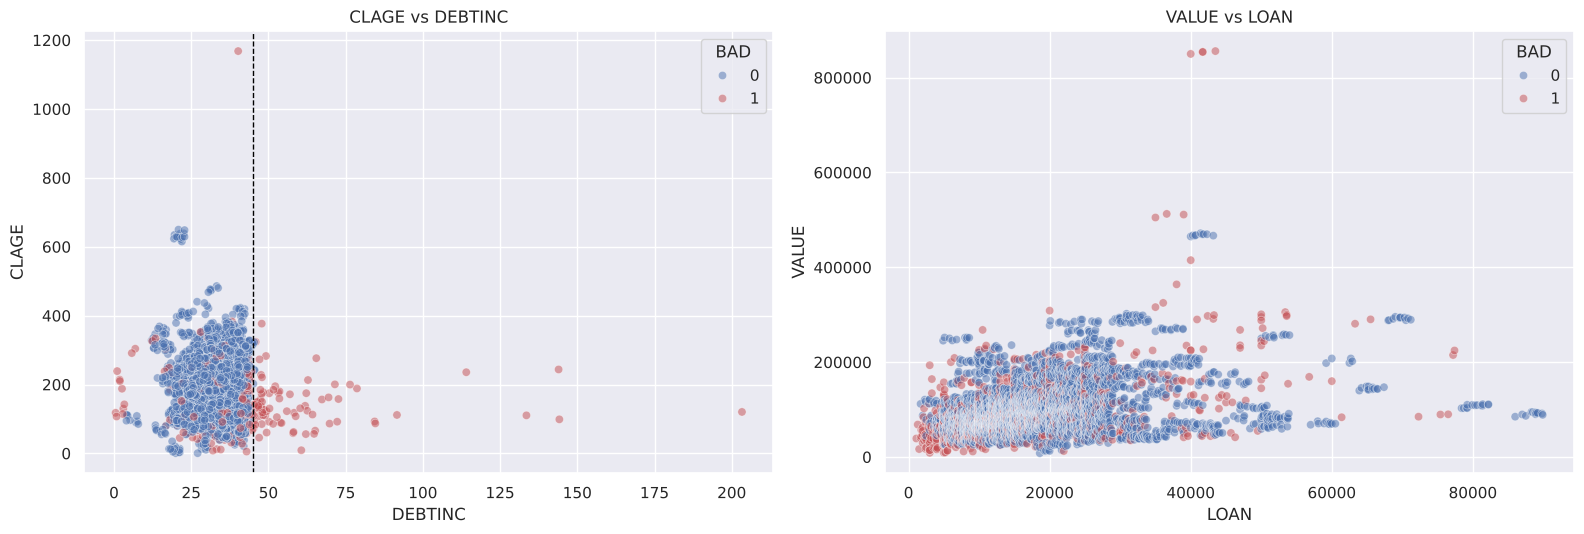

In [30]:
# Other pairs of continuous variables
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
sns.scatterplot(data=data, x="DEBTINC", y="CLAGE", hue="BAD", alpha=0.5, ax=axes[0], palette=["#4C72B0", "#C44E52"])
axes[0].axvline(45, color="black", linestyle="--", linewidth=1)
axes[0].set_title("CLAGE vs DEBTINC")
sns.scatterplot(data=data, x="LOAN", y="VALUE", hue="BAD", alpha=0.5, ax=axes[1], palette=["#4C72B0", "#C44E52"])
axes[1].set_title("VALUE vs LOAN")
plt.tight_layout()
plt.show()

**Insights:** Almost every applicant to the right of the 45% debt-to-income line is a defaulter regardless of credit-history length. To the left, defaulters concentrate among short credit histories, so the two variables complement each other. Loan amount rises loosely with property value (correlation 0.34). Defaulters appear across the whole range and concentrate visibly among the smallest loans.

### **Bivariate Analysis:  BAD vs Categorical Variables**

**The stacked bar chart (aka stacked bar graph)** extends the standard bar chart from looking at numeric values across one categorical variable to two.

In [31]:
### Function to plot stacked bar charts for categorical columns

def stacked_plot(x):
    sns.set(palette='nipy_spectral')
    tab1 = pd.crosstab(x,data['BAD'],margins=True)
    print(tab1)
    print('-'*120)
    tab = pd.crosstab(x,data['BAD'],normalize='index')
    tab.plot(kind='bar',stacked=True,figsize=(10,5))
    plt.legend(loc='lower left', frameon=False)
    plt.legend(loc="upper left", bbox_to_anchor=(1,1))
    plt.show()
    sns.set_theme()

#### Plot stacked bar plot for for LOAN and REASON

BAD         0     1   All
REASON                   
DebtCon  3183   745  3928
HomeImp  1384   396  1780
All      4567  1141  5708
------------------------------------------------------------------------------------------------------------------------


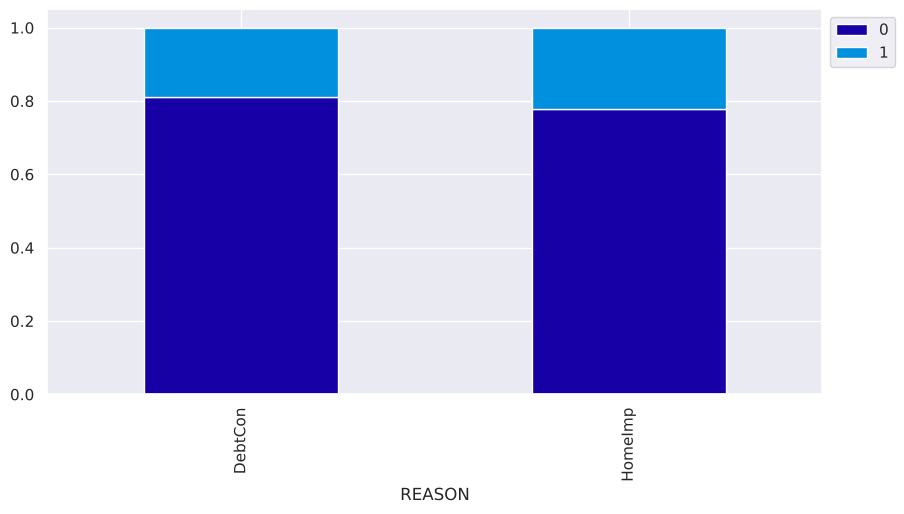

In [32]:
# Plot stacked bar plot for BAD and REASON
stacked_plot(data['REASON'])

**Insights:** Home-improvement loans default slightly more often (22.2%) than debt-consolidation loans (19.0%). The relationship is weak, a 3-point difference around a 20% base rate, so loan purpose alone should not drive approval decisions.

#### **Note:** As shown above, perform Bivariate Analysis on different pairs of Categorical vs BAD

BAD         0     1   All
JOB                      
Mgr       588   179   767
Office    823   125   948
Other    1834   554  2388
ProfExe  1064   212  1276
Sales      71    38   109
Self      135    58   193
All      4515  1166  5681
------------------------------------------------------------------------------------------------------------------------


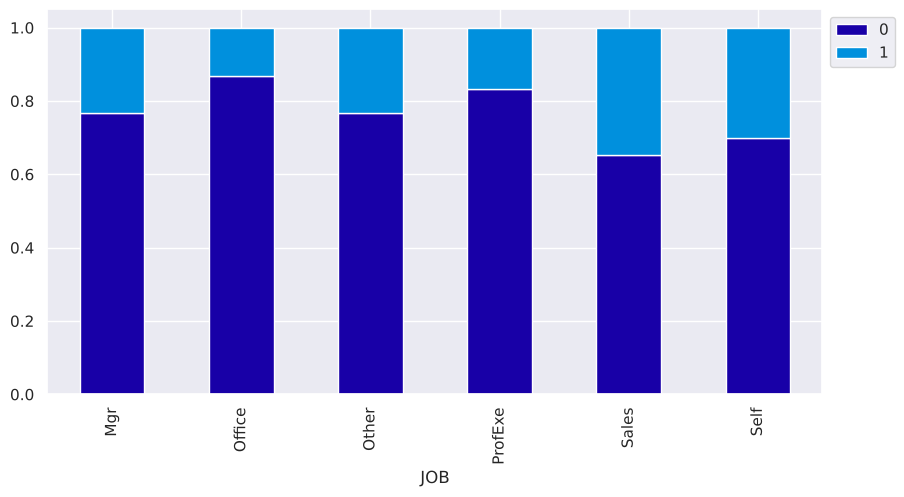

BAD       0     1   All
DEROG                  
0.0    3773   754  4527
1.0     266   169   435
2.0      78    82   160
3.0      15    43    58
4.0       5    18    23
5.0      13    36    49
All    4150  1102  5252
------------------------------------------------------------------------------------------------------------------------


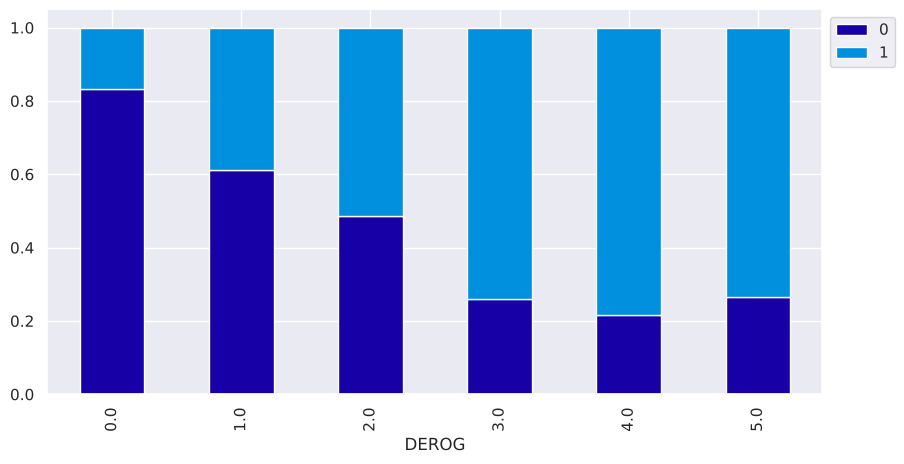

BAD        0     1   All
DELINQ                  
0.0     3596   583  4179
1.0      432   222   654
2.0      138   112   250
3.0       58    71   129
4.0       32    46    78
5.0        7    31    38
6.0        0    52    52
All     4263  1117  5380
------------------------------------------------------------------------------------------------------------------------


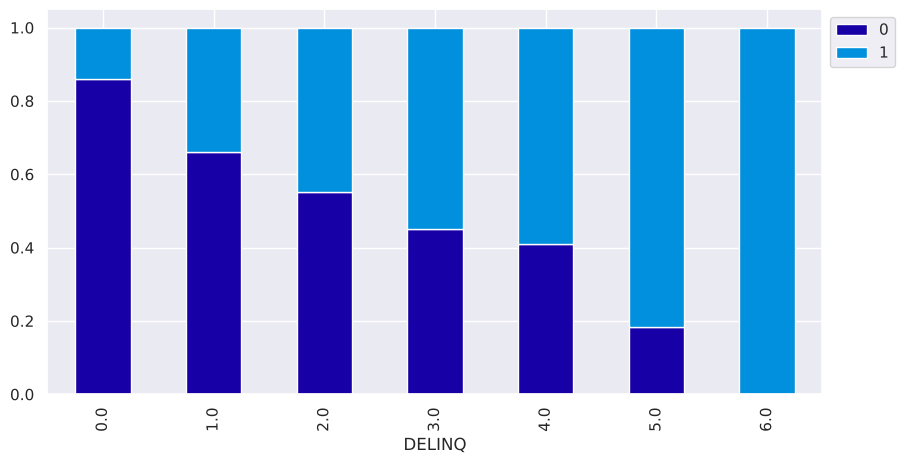

BAD      0     1   All
NINQ                  
0.0   2135   396  2531
1.0   1085   254  1339
2.0    599   181   780
3.0    285   107   392
4.0     95    61   156
5.0     39    36    75
6.0     27    29    56
7.0     29    15    44
8.0     42    35    77
All   4336  1114  5450
------------------------------------------------------------------------------------------------------------------------


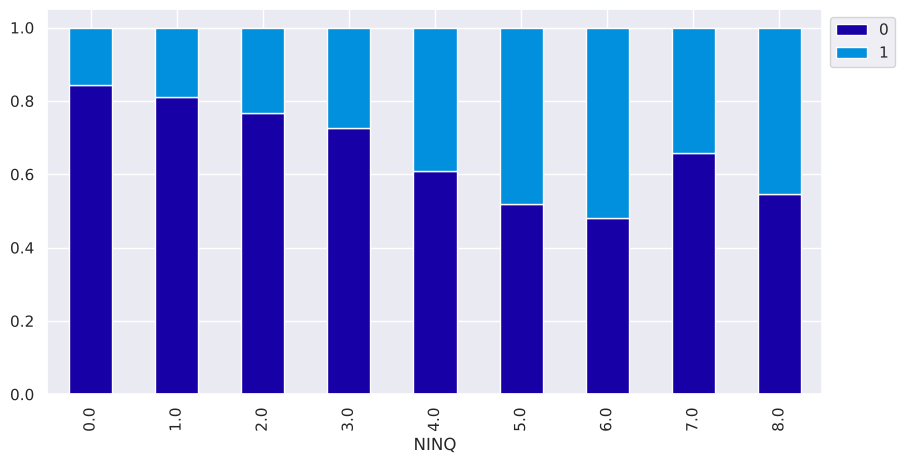

In [33]:
# Stacked bar plots for JOB and the count variables (capped so the chart stays readable)
stacked_plot(data['JOB'])
stacked_plot(data['DEROG'].clip(upper=5))
stacked_plot(data['DELINQ'].clip(upper=6))
stacked_plot(data['NINQ'].clip(upper=8))

In [34]:
# Is missing information itself a signal? Default rate when a field is missing vs present
rows = []
for col in data.columns.drop("BAD"):
    if data[col].isnull().any():
        is_na = data[col].isnull()
        rows.append({"column": col, "missing_rows": int(is_na.sum()),
                     "default_rate_when_missing_%": round(data.loc[is_na, "BAD"].astype(int).mean() * 100, 1),
                     "default_rate_when_present_%": round(data.loc[~is_na, "BAD"].astype(int).mean() * 100, 1)})
pd.DataFrame(rows).sort_values("default_rate_when_missing_%", ascending=False)

,column,missing_rows,default_rate_when_missing_%,default_rate_when_present_%
1,VALUE,112,93.8,18.5
10,DEBTINC,1267,62.0,8.6
7,CLAGE,308,25.3,19.7
9,CLNO,222,23.9,19.8
0,MORTDUE,518,20.5,19.9
2,REASON,252,19.0,20.0
8,NINQ,510,14.7,20.4
4,YOJ,515,12.6,20.6
6,DELINQ,580,12.4,20.8
5,DEROG,708,12.3,21.0


**Insights:**
- `JOB`: Sales (34.9%) and Self-employed (30.1%) default at 1.5 to 1.75 times the average. Office workers (13.2%) and ProfExe (16.6%) are the safest. Mgr and Other sit slightly above average. Sales and Self are small groups, so occupation should be a supporting signal only. The bank must monitor it for fair-lending proxy effects.
- `DEROG`: 17% default with no report, 39% with one, 51% with two, about 73-78% with three or more. `DELINQ`: 14% at zero, 34% at one, 45% at two, 100% at six or more. `NINQ` rises from 16% at zero to 39% at four and about 46% at five or more (252 applicants). These rising patterns are easy to explain to an applicant.
- **Missing information is itself a strong signal:** when `DEBTINC` is missing, 62% of applicants defaulted (vs 8.6% when present). When `VALUE` is missing, 94% defaulted. For `DEROG`, `DELINQ`, `YOJ`, `NINQ` and `JOB` the opposite holds (8-15% default when missing). This probably reflects how the data was recorded. We must therefore keep missing-value flags as features.

### **Multivariate Analysis**

#### Analyze Correlation Heatmap for Numerical Variables

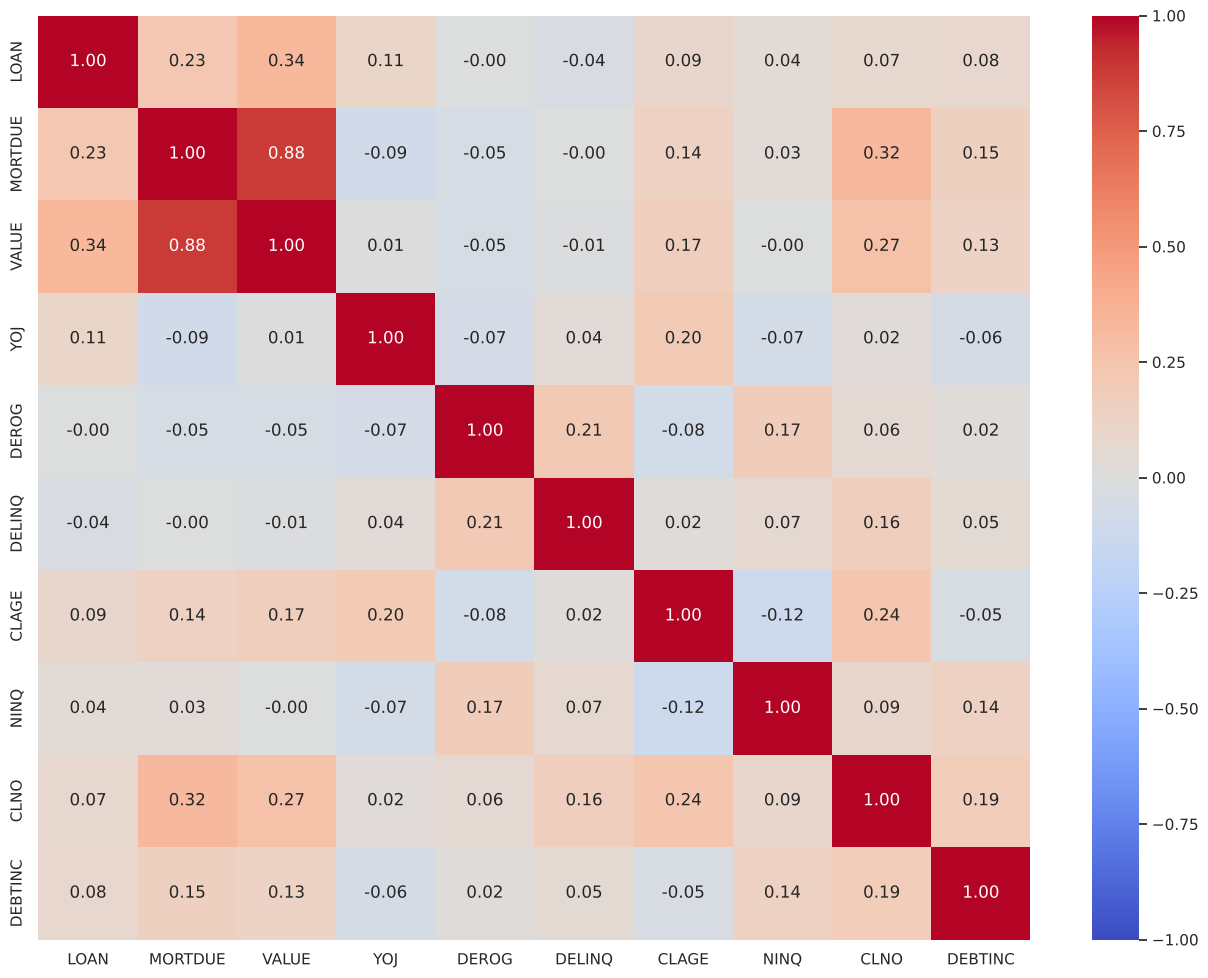

In [35]:
# Separating numerical variables
numerical_col = data.select_dtypes(include=np.number).columns.tolist()

# Build correlation matrix for numerical columns
corr = data[numerical_col].corr()

# plot the heatmap
plt.figure(figsize=(16,12))
sns.heatmap(corr, annot=True, cmap='coolwarm',vmax=1,vmin=-1,
        fmt=".2f",
        xticklabels=corr.columns,
        yticklabels=corr.columns);

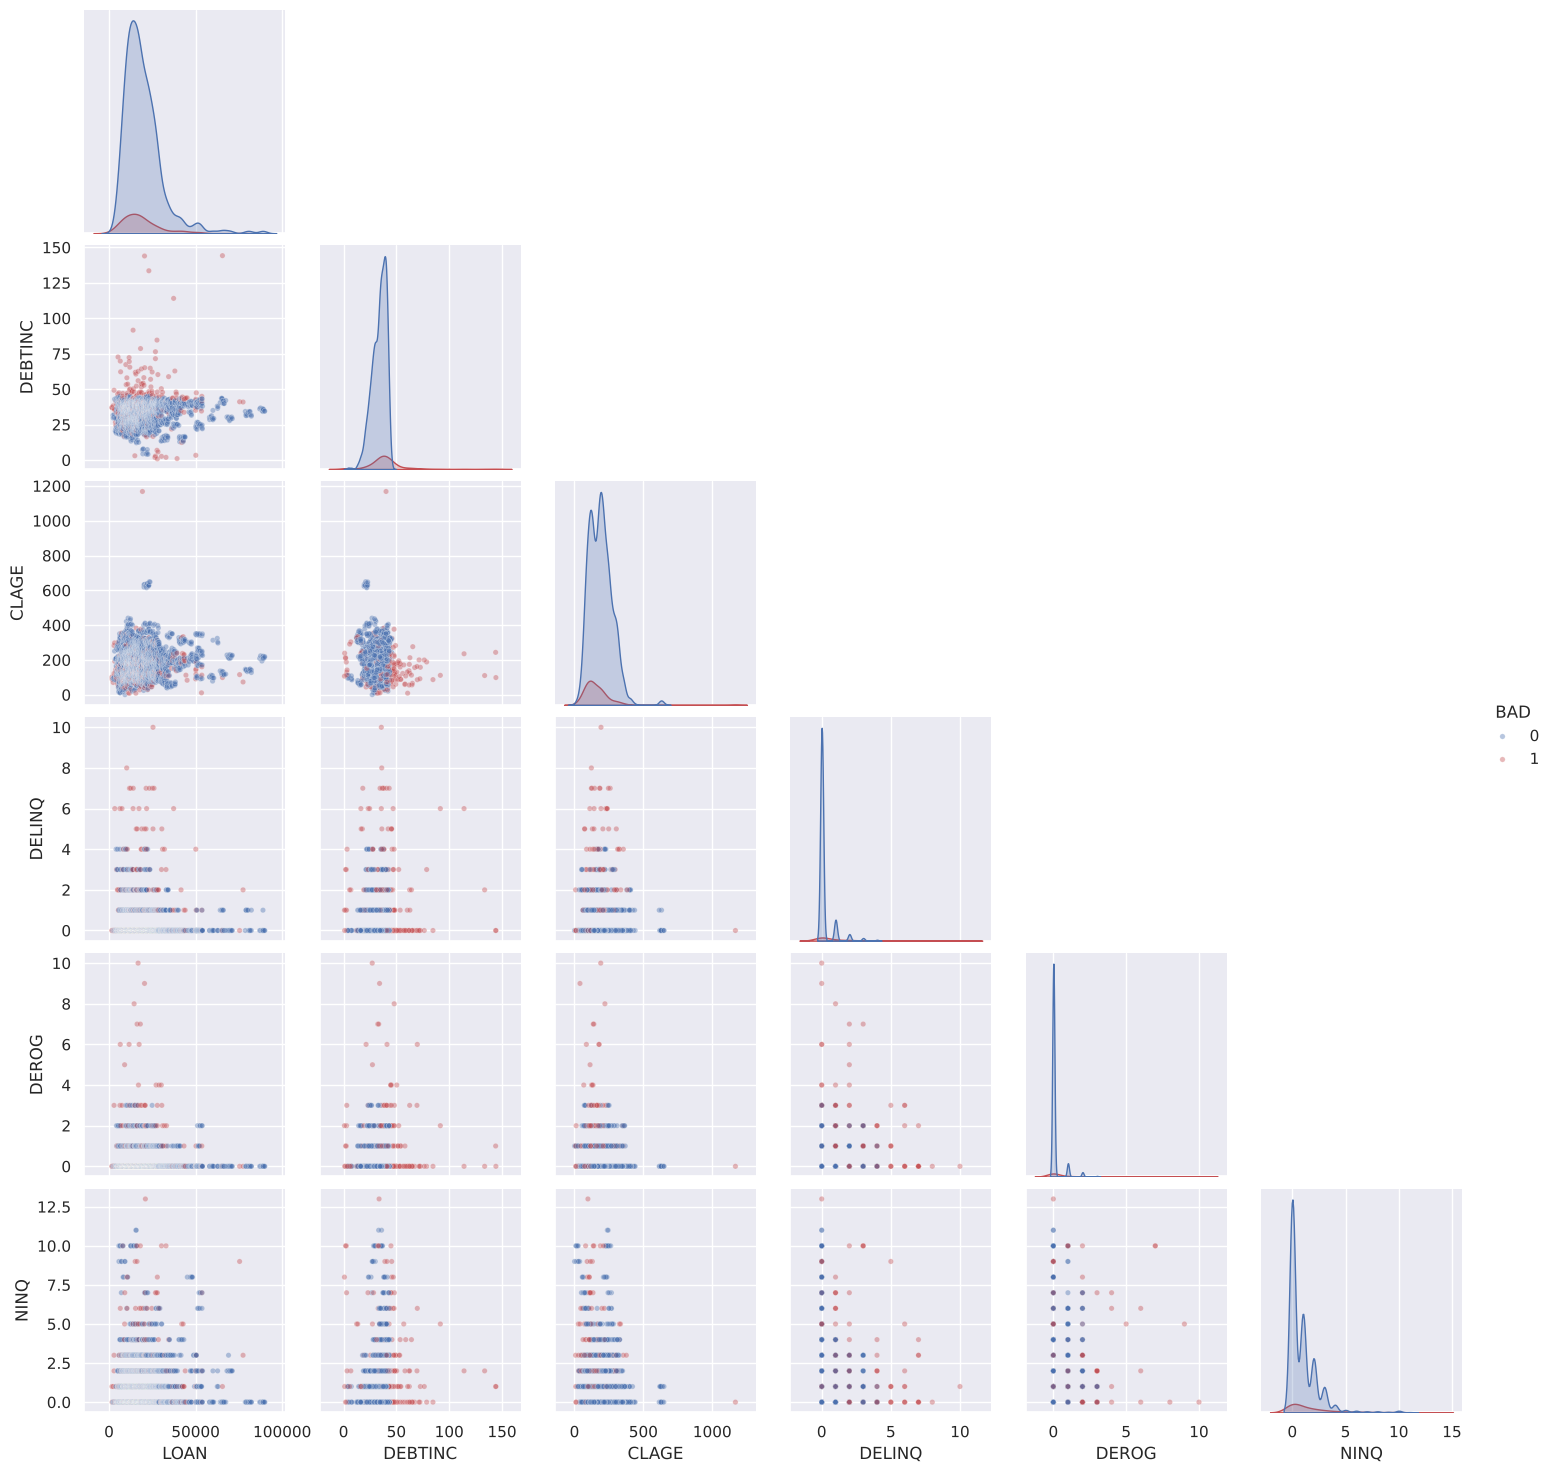

In [36]:
# Build pairplot for the data with hue = 'BAD' (the six most informative numerical variables, to keep the chart readable)
sns.pairplot(data[['LOAN', 'DEBTINC', 'CLAGE', 'DELINQ', 'DEROG', 'NINQ', 'BAD']].dropna(),
             hue='BAD', palette=["#4C72B0", "#C44E52"], diag_kind='kde', corner=True, plot_kws={"alpha": 0.4, "s": 15})
plt.show()

**Insights (multivariate):**
- The only strong correlation between inputs is `MORTDUE` vs `VALUE` (0.88). This is multicollinearity for the logistic regression (their coefficients share the same information), but it is harmless for tree models. The moderate links are `CLNO` with `MORTDUE`/`VALUE` (0.27-0.32) and `LOAN` with `VALUE` (0.34).
- Correlations with the target are weak to moderate: `DELINQ` (0.35), `DEROG` (0.28), `DEBTINC` (0.20), `NINQ` (0.17), `CLAGE` (-0.17). The count variables are close to linear in the default rate. `DEBTINC`, `CLAGE` and `LOAN` act through thresholds that a correlation coefficient understates. This is an early hint that tree-based models should outperform a purely linear one on the raw inputs.
- In the pairplot, defaulters (red) have visibly shorter `CLAGE`, higher `DEBTINC` and heavier tails on `DELINQ`, `DEROG` and `NINQ`. No single pair separates the classes cleanly, so the separation comes from combinations.

#### Two categorical variables and the target: occupation and loan purpose

The bivariate analysis looked at occupation and loan purpose one at a time. Here we cross them, to check whether the risk of a loan purpose depends on the occupation. Applicants with a missing `JOB` or `REASON` are not in this chart.

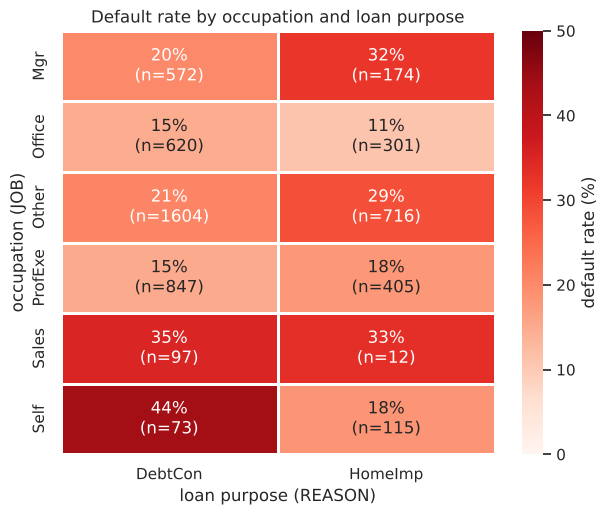

default_rate_%         applicants        
REASON         DebtCon HomeImp    DebtCon HomeImp
JOB                                              
Mgr               20.3    32.2        572     174
Office            14.8    11.0        620     301
Other             20.8    28.6       1604     716
ProfExe           15.2    18.0        847     405
Sales             35.1    33.3         97      12
Self              43.8    18.3         73     115

In [37]:
#@title
# Default rate by occupation and loan purpose (two categorical variables and the target)
bad_int = data["BAD"].astype(int)
job_rate = bad_int.groupby([data["JOB"], data["REASON"]], observed=True).mean().unstack() * 100
job_n = bad_int.groupby([data["JOB"], data["REASON"]], observed=True).size().unstack()
cell_labels = job_rate.round(0).astype(int).astype(str) + "%\n(n=" + job_n.astype(str) + ")"

fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(job_rate, annot=cell_labels, fmt="", cmap="Reds", vmin=0, vmax=50, linewidths=2, linecolor="white",
            cbar_kws={"label": "default rate (%)"}, ax=ax)
ax.set_xlabel("loan purpose (REASON)"); ax.set_ylabel("occupation (JOB)")
ax.set_title("Default rate by occupation and loan purpose")
plt.show()

pd.concat({"default_rate_%": job_rate.round(1), "applicants": job_n}, axis=1)

**Insights - occupation and loan purpose:**
- Occupation and loan purpose interact. Self-employed applicants who borrowed to consolidate debt defaulted 44% of the time (73 applicants). Self-employed applicants who borrowed for home improvement defaulted 18% of the time (115 applicants).
- Managers show the opposite pattern: 32% default on home-improvement loans (174 applicants) against 20% on debt consolidation (572 applicants). The "Other" group follows the managers (29% against 21%).
- Sales applicants default often for both purposes (35% and 33%), but only 12 of them borrowed for home improvement. Office workers default least for both purposes (15% and 11%).
- On its own, loan purpose looks weak (22% against 19%). Within some occupations it changes the risk by a factor of two. Tree models can learn this interaction directly. A linear model needs an explicit interaction term to learn it. Any rule that uses occupation needs the fair-lending review.

#### A numerical and a categorical variable with the target: debt burden and credit history by occupation

We check whether the two strongest numerical drivers work in every occupation, or only in some. The boxplots hide the extreme values to keep the boxes readable, and they use only applicants with a recorded value.

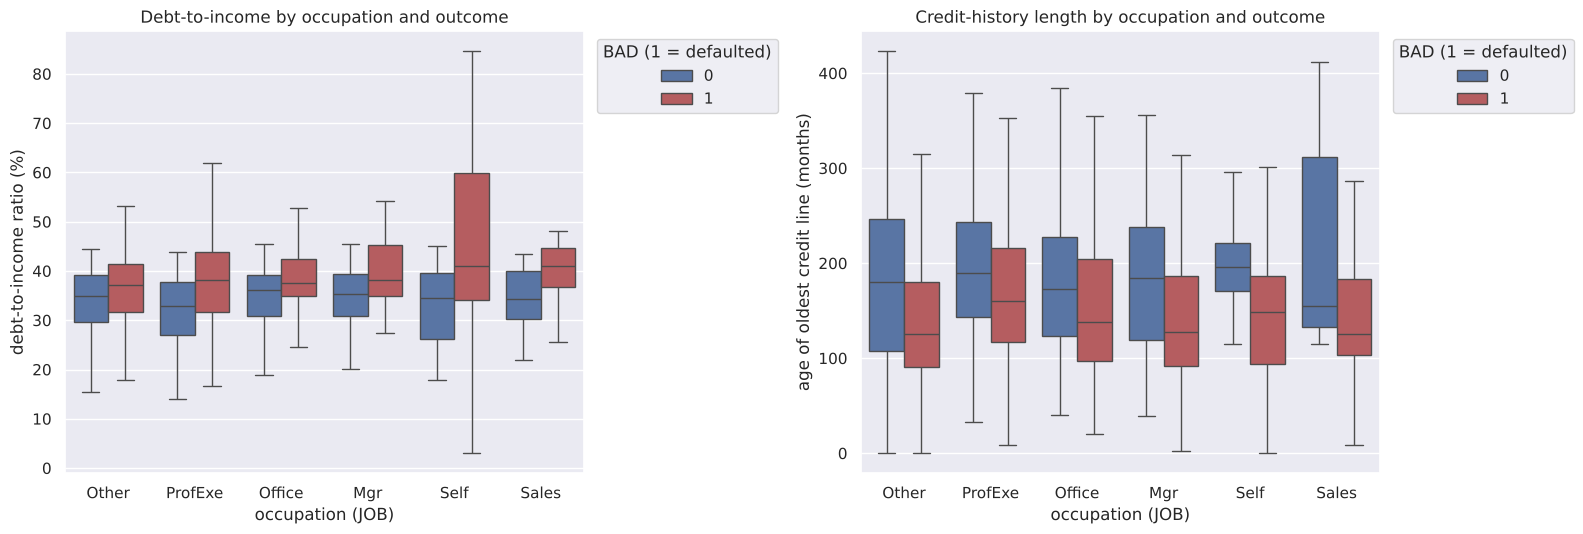

DEBTINC_median       CLAGE_median_months       
BAD                  0     1                   0      1
JOB                                                    
Mgr               35.3  38.3               184.0  127.0
Office            36.1  37.6               173.0  138.0
Other             35.0  37.1               180.0  125.0
ProfExe           32.9  38.2               189.0  160.0
Sales             34.4  41.0               155.0  125.0
Self              34.5  40.9               196.0  149.0

In [38]:
#@title
# Debt-to-income and credit-history length by occupation, split by outcome
job_order = data["JOB"].value_counts().index
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
for ax, col, label, title in [(axes[0], "DEBTINC", "debt-to-income ratio (%)", "Debt-to-income by occupation and outcome"),
                              (axes[1], "CLAGE", "age of oldest credit line (months)", "Credit-history length by occupation and outcome")]:
    sns.boxplot(data=data, x="JOB", y=col, hue="BAD", order=job_order, palette=["#4C72B0", "#C44E52"],
                showfliers=False, ax=ax)
    ax.set_xlabel("occupation (JOB)"); ax.set_ylabel(label); ax.set_title(title)
    ax.legend(title="BAD (1 = defaulted)", loc="upper left", bbox_to_anchor=(1.01, 1.0))
plt.tight_layout(); plt.show()

pd.concat({"DEBTINC_median": data.groupby(["JOB", "BAD"], observed=True)["DEBTINC"].median().unstack().round(1),
           "CLAGE_median_months": data.groupby(["JOB", "BAD"], observed=True)["CLAGE"].median().unstack().round(0)}, axis=1)

**Insights - debt burden and credit history by occupation:**
- In every occupation, defaulters have a higher median debt-to-income ratio than repayers. The gap is about 1.5 points for office workers (37.6 against 36.1). It is about 6.5 points for sales and self-employed applicants (41.0 against 34.4, and 40.9 against 34.5).
- In every occupation, defaulters have a shorter credit history. The median gap is 29 months for professionals (160 against 189) and 57 months for managers (127 against 184).
- So debt burden and credit-history length work in every occupation. Occupation moves the baseline risk, but it does not replace these two drivers.

#### Interactions between the strongest drivers

The bivariate analysis found four strong drivers: the debt-to-income ratio, delinquent credit lines, credit-history length and derogatory reports. Here we cross them in pairs, and we keep "missing" as its own group because missingness is itself a signal. Each cell shows the default rate and the number of applicants. Cells with very few applicants (for example, a ratio above 45% with one delinquent line) are noisy, so we read them with caution.

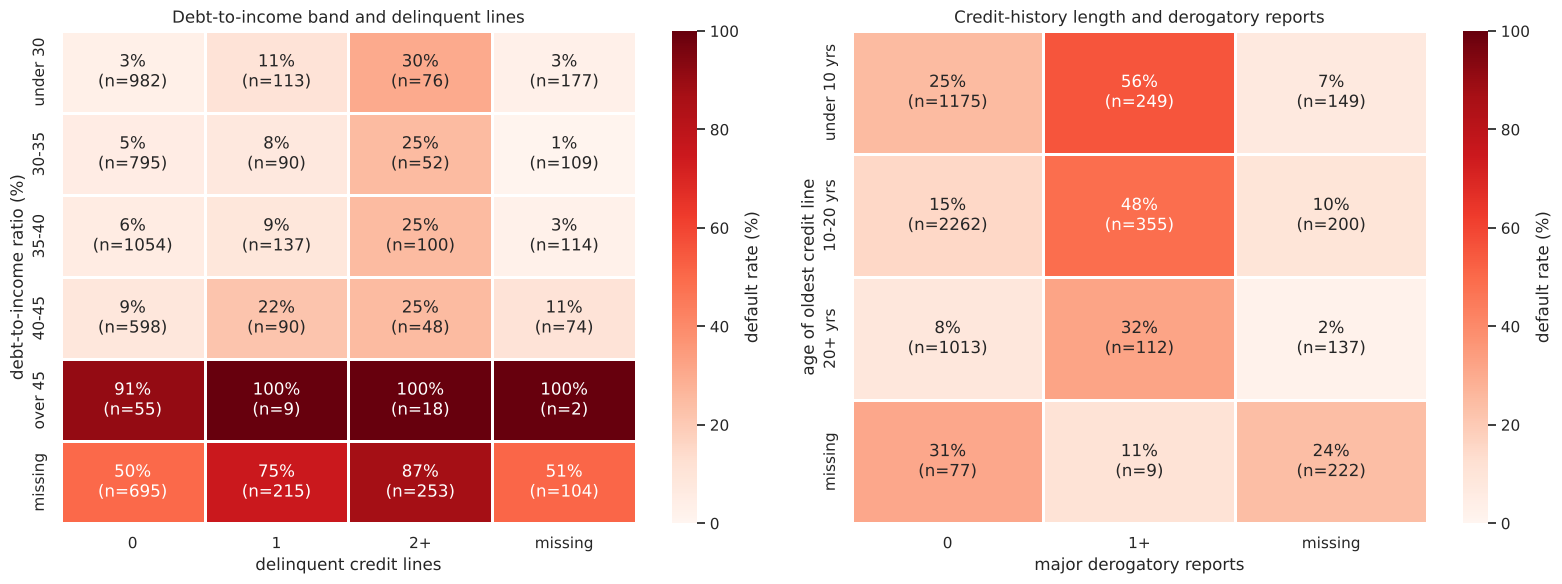

default_rate_pct  applicants
DEBTINC        VALUE                                       
ratio missing  value missing               98.8          81
               value recorded              59.5        1186
ratio recorded value missing               80.6          31
               value recorded               8.1        4662

In [39]:
#@title
# Default rate for pairs of drivers, with 'missing' kept as its own group
def band_with_missing(s, bins, labels):
    banded = pd.cut(s, bins=bins, labels=labels, include_lowest=True).astype(object)
    return banded.where(s.notna(), "missing")

dti_band = band_with_missing(data["DEBTINC"], [0, 30, 35, 40, 45, np.inf], ["under 30", "30-35", "35-40", "40-45", "over 45"])
delinq_group = band_with_missing(data["DELINQ"], [-0.5, 0.5, 1.5, np.inf], ["0", "1", "2+"])
history_band = band_with_missing(data["CLAGE"], [0, 120, 240, np.inf], ["under 10 yrs", "10-20 yrs", "20+ yrs"])
derog_group = band_with_missing(data["DEROG"], [-0.5, 0.5, np.inf], ["0", "1+"])

def rate_grid(rows, cols, row_order, col_order):
    grid_rate = bad_int.groupby([rows, cols]).mean().unstack().reindex(index=row_order, columns=col_order) * 100
    grid_n = bad_int.groupby([rows, cols]).size().unstack().reindex(index=row_order, columns=col_order).fillna(0).astype(int)
    return grid_rate, grid_n

grids = [
    (dti_band, delinq_group, ["under 30", "30-35", "35-40", "40-45", "over 45", "missing"], ["0", "1", "2+", "missing"],
     "debt-to-income ratio (%)", "delinquent credit lines", "Debt-to-income band and delinquent lines"),
    (history_band, derog_group, ["under 10 yrs", "10-20 yrs", "20+ yrs", "missing"], ["0", "1+", "missing"],
     "age of oldest credit line", "major derogatory reports", "Credit-history length and derogatory reports"),
]
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, (rows, cols, row_order, col_order, ylabel, xlabel, title) in zip(axes, grids):
    grid_rate, grid_n = rate_grid(rows, cols, row_order, col_order)
    grid_labels = grid_rate.round(0).fillna(0).astype(int).astype(str) + "%\n(n=" + grid_n.astype(str) + ")"
    sns.heatmap(grid_rate, annot=grid_labels, fmt="", mask=(grid_n == 0), cmap="Reds", vmin=0, vmax=100, linewidths=2,
                linecolor="white", cbar_kws={"label": "default rate (%)"}, ax=ax)
    ax.set_ylabel(ylabel); ax.set_xlabel(xlabel); ax.set_title(title)
plt.tight_layout(); plt.show()

# The two strongest missing-value signals together
ratio_status = data["DEBTINC"].isna().map({False: "ratio recorded", True: "ratio missing"})
value_status = data["VALUE"].isna().map({False: "value recorded", True: "value missing"})
both_missing = bad_int.groupby([ratio_status, value_status]).agg(default_rate_pct="mean", applicants="size")
both_missing["default_rate_pct"] = (100 * both_missing["default_rate_pct"]).round(1)
both_missing

**Insights - interactions between the strongest drivers:**
- **Debt burden and repayment history add up.** When the ratio is 45% or less, delinquency still decides much of the risk. In that group, 3% to 9% defaulted with no delinquent lines, and 25% to 30% defaulted with two or more.
- Above 45%, 91% to 100% defaulted, whatever the number of delinquent lines. The ratio alone is enough in that group.
- When the ratio is missing, delinquency adds risk on top of the missing signal. In that group, 50% defaulted with no delinquent lines (695 applicants) and 87% with two or more (253 applicants).
- **A long credit history lowers the risk but does not cancel a derogatory report.** With one or more reports, the default rate rises from 25% to 56% under 10 years of history. It rises from 15% to 48% at 10 to 20 years, and from 8% to 32% at 20 years or more.
- **The two missing-value signals compound.** With both fields recorded, 8% defaulted (4,662 applicants). With only the ratio missing, 60% defaulted (1,186 applicants). With only the property value missing, 81% defaulted (31 applicants). With both missing, 99% defaulted (81 applicants).
- These combined effects suggest that a tree-based model, which splits on one driver inside another, should beat a model that adds each driver alone. They also match the surrogate tree we fit later. In that tree, a high or missing ratio flags an applicant. Repayment history and credit-history length decide among the others.

### **Think about it**
- Are there missing values and outliers in the dataset? If yes, how can you treat them?
- Can you think of different ways in which this can be done and when to treat these outliers or not?
- Can we create new features based on Missing values?

*Yes to all three. We create a 0/1 flag per column, because the EDA showed that missingness of `DEBTINC` and `VALUE` is the strongest default signal in the data. We then impute missing values with the median (numerical) or mode (categorical).*

*We cap outliers at the IQR whiskers for the logistic regression, which is sensitive to extreme values. We leave them untouched for the tree models. Tree models split on rank order, so extreme values do not distort them. Capping would only merge the largest values into one value. `DEROG` and `DELINQ` are counts with an inter-quartile range of zero, so the IQR rule would erase them. We cap them at the 99th percentile instead.*

#### Treating Outliers

In [40]:
def treat_outliers(df,col,fit_rows=None):
    '''
    treats outliers in a varaible
    col: str, name of the numerical varaible
    df: data frame
    col: name of the column
    fit_rows: rows used to compute the fences (the training rows); default all rows
    '''
    fit = df.loc[fit_rows, col] if fit_rows is not None else df[col]
    Q1=fit.quantile(0.25) # 25th quantile
    Q3=fit.quantile(0.75)  # 75th quantile
    IQR=Q3 - Q1   # IQR Range
    Lower_Whisker = Q1 - 1.5 * IQR  #define lower whisker
    Upper_Whisker = Q3 + 1.5 * IQR  # define upper Whisker
    df[col] = np.clip(df[col], Lower_Whisker, Upper_Whisker) # all the values samller than Lower_Whisker will be assigned value of Lower_whisker
                                                            # and all the values above upper_whishker will be assigned value of upper_Whisker
    return df

def treat_outliers_all(df, col_list, fit_rows=None):
    '''
    treat outlier in all numerical varaibles
    col_list: list of numerical varaibles
    df: data frame
    fit_rows: rows used to compute the fences (the training rows)
    '''
    for c in col_list:
        df = treat_outliers(df,c,fit_rows)

    return df

In [41]:
df_raw = data.copy()

numerical_col = df_raw.select_dtypes(include=np.number).columns.tolist()# getting list of numerical columns

# DEROG and DELINQ have Q1 = Q3 = 0, so the IQR whiskers collapse to zero and the rule would erase them.
# They are capped at the 99th percentile instead; the other numerical columns use the IQR rule.
iqr_cols = [c for c in numerical_col if c not in ('DEROG', 'DELINQ')]
df = treat_outliers_all(df_raw, iqr_cols, fit_rows=train_idx)
for c in ['DEROG', 'DELINQ']:
    df[c] = df[c].clip(upper=df.loc[train_idx, c].quantile(0.99))

# Maximum of each column before and after the treatment
pd.DataFrame({'max_before': data[numerical_col].max(), 'max_after': df[numerical_col].max()})

,max_before,max_after
LOAN,89900.000000,41850.000000
MORTDUE,399550.000000,161277.500000
VALUE,855909.000000,201864.750000
YOJ,41.000000,28.000000
DEROG,10.000000,5.000000
DELINQ,15.000000,6.000000
CLAGE,1168.233561,406.840416
NINQ,17.000000,5.000000
CLNO,71.000000,46.500000
DEBTINC,203.312149,53.784804


#### Adding new columns in the dataset for each column which has missing values 

In [42]:
#For each column we create a binary flag for the row, if there is missing value in the row, then 1 else 0. 
def add_binary_flag(df,col):
    '''
    df: It is the dataframe
    col: it is column which has missing values
    It returns a dataframe which has binary falg for missing values in column col
    '''
    new_col = str(col)
    new_col += '_missing_values_flag'
    df[new_col] = df[col].isna()
    return df

In [43]:
# list of columns that has missing values in it
missing_col = [col for col in df.columns if df[col].isnull().any()]

for colmn in missing_col:
    add_binary_flag(df,colmn)
    

#### Filling missing values in numerical columns with median and mode in categorical variables

In [44]:
#  Treat Missing values in numerical columns with median and mode in categorical variables
# Select numeric columns.
num_data = df.select_dtypes('number')

# Select string and object columns.
cat_data = df.select_dtypes('category').columns.tolist()#df.select_dtypes('object')

# Fill numeric columns with the median of the training rows.
df[num_data.columns] = num_data.fillna(num_data.loc[train_idx].median())

# Fill object columns with the mode of the training rows.
for column in cat_data:
    mode = df.loc[train_idx, column].mode()[0]
    df[column] = df[column].fillna(mode)

print("Remaining missing values:", df.isnull().sum().sum())

Remaining missing values: 0


## **Important Insights from EDA**

What are the the most important observations and insights from the data based on the EDA performed?

1. **One in five loans goes bad (19.9%).** The classes are imbalanced, so accuracy is the wrong yardstick. We must handle the imbalance with class weights while we build the individual models, and with the decision threshold when we choose the final model.
2. **Missing information is the strongest single risk signal.** Applicants with no recorded debt-to-income ratio default 62% of the time (vs 8.6% when recorded). Applicants with no property valuation default 94% of the time. Unverifiable income or valuation is a red flag, not a neutral gap.
3. **Debt-to-income ratio has a hard threshold.** Between 20% and 40% the default rate is 4-7% (11% below 20%). Between 40% and 45% it is 11%. Above 45% it is 87-100%. A 45% threshold is a simple, defensible policy rule.
4. **Past credit behaviour predicts future behaviour.** Each additional derogatory report or delinquent credit line raises the default rate sharply (0 reports: 17%, 1: 39%, 2: 51%, 3 or more: about 75%). Recent inquiries show the same rising pattern.
5. **A long credit history protects.** Under 5 years of history, 44% default. Above 20 years, about 10% default.
6. **Small loans are not safe loans.** Loans under \$5,000 default 57% of the time.
7. **Occupation matters moderately** (Sales 35%, Self 30%, Office 13%). Loan purpose makes only a 3-point difference, although it is statistically significant.
8. **Property value and mortgage balance are highly correlated (0.88)** and individually weak predictors.
9. **Relationships with the target are non-linear** (cliffs and thresholds), so we expect tree-based models to beat logistic regression, which remains the most transparent benchmark.
10. **Risk factors combine rather than act alone.** A ratio above 45% flags an applicant by itself. At or below 45%, two or more delinquent lines raise the default rate from 3-9% to 25-30%. A derogatory report raises risk at every credit-history length. When both the ratio and the property value are missing, 99% defaulted. Loan purpose also changes the risk within some occupations (self-employed applicants: 44% on debt consolidation against 18% on home improvement). These interactions favour tree-based models.
11. **Pre-processing decisions:**
    - We removed no rows and found no duplicates.
    - We reserved the test set before we fitted any statistic.
    - We added a missing-value flag for every column with gaps.
    - We learned the median/mode imputation on the training rows.
    - We applied IQR capping only for the linear model (99th-percentile cap for DEROG and DELINQ).
    - We one-hot encoded `REASON` and `JOB`.
    - We applied standard scaling to the continuous inputs for the linear model only.

## **Model Building - Approach**
1. Data preparation
2. Partition the data into train and test set
3. Fit on the train data
4. Tune the model and prune the tree, if required
5. Test the model on test set

## **Data Preparation**

### **Separating the target variable from other variables**

In [45]:
#@title
# Drop the dependent variable from the dataframe and create the X(independent variable) matrix
X = df.drop(['BAD'], axis=1)

# Create dummy variables for the categorical variables
X = pd.get_dummies(X, columns=['REASON', 'JOB'], drop_first=True, dtype=int)

# Create y(dependent varibale)
y = df['BAD'].astype(int)

print(X.shape, y.shape)

(5960, 27) (5960,)


### **Splitting the data into 70% train and 30% test set**

In [46]:
#@title
# Split the data into training and test set, using the stratified 70/30 split held out at the start
X_train, X_test = X.loc[train_idx], X.loc[test_idx]
y_train, y_test = y.loc[train_idx], y.loc[test_idx]

print("Train shape:", X_train.shape, "Test shape:", X_test.shape)
print(f"Default rate - train: {y_train.mean():.3f}, test: {y_test.mean():.3f}")

# Standardise the continuous inputs for the linear model (fit on train only); the 0/1 flags and dummies stay as they are,
# so their coefficients read as the effect of the flag switching on. Tree models use the unscaled data.
from sklearn.preprocessing import StandardScaler
continuous = ['LOAN', 'MORTDUE', 'VALUE', 'YOJ', 'DEROG', 'DELINQ', 'CLAGE', 'NINQ', 'CLNO', 'DEBTINC']
scaler = StandardScaler().fit(X_train[continuous])
X_train_lr, X_test_lr = X_train.copy(), X_test.copy()
X_train_lr[continuous] = scaler.transform(X_train[continuous])
X_test_lr[continuous] = scaler.transform(X_test[continuous])
print(f'Linear-model inputs ({X_train_lr.shape[1]}):')
print(f'  capped (IQR whiskers, DEROG and DELINQ at the 99th percentile) and standardised ({len(continuous)}):', continuous)
print(f'  left as 0/1 ({X_train_lr.shape[1] - len(continuous)}):', [c for c in X_train_lr.columns if c not in continuous])

Train shape: (4172, 27) Test shape: (1788, 27)
Default rate - train: 0.199, test: 0.200
Linear-model inputs (27):
  capped (IQR whiskers, DEROG and DELINQ at the 99th percentile) and standardised (10): ['LOAN', 'MORTDUE', 'VALUE', 'YOJ', 'DEROG', 'DELINQ', 'CLAGE', 'NINQ', 'CLNO', 'DEBTINC']
  left as 0/1 (17): ['MORTDUE_missing_values_flag', 'VALUE_missing_values_flag', 'REASON_missing_values_flag', 'JOB_missing_values_flag', 'YOJ_missing_values_flag', 'DEROG_missing_values_flag', 'DELINQ_missing_values_flag', 'CLAGE_missing_values_flag', 'NINQ_missing_values_flag', 'CLNO_missing_values_flag', 'DEBTINC_missing_values_flag', 'REASON_HomeImp', 'JOB_Office', 'JOB_Other', 'JOB_ProfExe', 'JOB_Sales', 'JOB_Self']


### **Think about it**
- You can try different splits like 70:30 or 80:20 as per your choice. Does this change in split affect the performance?
- If the data is imbalanced, can you make the split more balanced and if yes, how?

*A 70:30 split leaves 1,788 applicants (357 defaulters) for an honest test. An 80:20 split would train on slightly more data but test on fewer defaulters, so the test scores become noisier. On two other 70/30 splits, the cheapest forest configuration (no class weights) and its 0.15 threshold did not change (see the robustness cell). We did not test an 80:20 split. We should not "balance" the split itself by removing applicants. Stratifying on `BAD` keeps the true 20% default rate in both sets. We then handle the imbalance inside the models, with class weights and later the decision threshold (or by resampling the training rows only).*

## **Model Evaluation Criterion**

#### After understanding the problem statement, think about which evaluation metrics to consider and why.

The model can make two kinds of mistakes and they do not cost the same:

| Model says | Reality | Name | Business consequence |
|---|---|---|---|
| Will repay (approve) | Defaults | **False Negative** | The bank loses a large part of the principal plus collection costs. If the bank recovers about half of a typical \$16,900 defaulted loan through the collateral, a missed defaulter costs about \$9,000. |
| Will default (reject) | Repays | **False Positive** | The bank forgoes the interest margin on one good customer: about \$2,000. |

A missed defaulter costs roughly 4.5 times a wrongly rejected good applicant. That is why the **primary metric is Recall on the defaulter class (BAD = 1)**. Of all applicants who later defaulted, what share did the model flag? Recall alone can be gamed (rejecting everyone gives 100% recall). We therefore track **Precision** (how many flagged applicants really default) and **F1** as guard-rails, with **Accuracy** for completeness.

Grid search optimises recall with cross-validation on the training rows when we build the individual models. We then choose the final model and its threshold on the expected cost of the two errors. We estimate that cost on repeated out-of-fold predictions of the training rows, so precision enters the choice explicitly.

In [47]:
#@title
#creating metric function
def metrics_score(actual, predicted):
    print(classification_report(actual, predicted, digits=3))
    cm = confusion_matrix(actual, predicted)
    plt.figure(figsize=(8,5))
    sns.heatmap(cm, annot=True,  fmt='d', cmap='Blues', xticklabels=['Repaid (0)', 'Default (1)'], yticklabels=['Repaid (0)', 'Default (1)'])
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.show()

### **Build a Logistic Regression Model** 

In [48]:
#@title
# Defining the Logistic regression model
lg = LogisticRegression(max_iter=2000, random_state=1)

# Fitting the model on the training data
lg.fit(X_train_lr, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",1
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",2000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in t

#### Checking the performance on the train dataset

              precision    recall  f1-score   support

           0      0.913     0.960     0.936      3340
           1      0.799     0.635     0.707       832

    accuracy                          0.895      4172
   macro avg      0.856     0.797     0.822      4172
weighted avg      0.891     0.895     0.891      4172



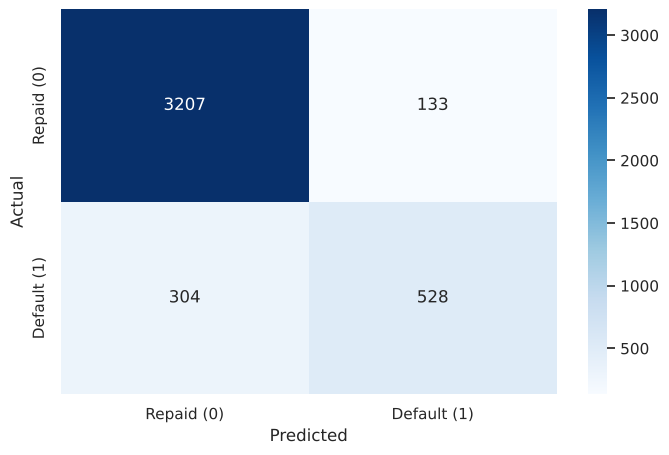

In [49]:
#@title
#Predict for train set
y_pred_train = lg.predict(X_train_lr)

#checking the performance on the train dataset
metrics_score(y_train, y_pred_train)

#### Checking the performance on the test dataset

              precision    recall  f1-score   support

           0      0.898     0.959     0.928      1431
           1      0.774     0.566     0.654       357

    accuracy                          0.880      1788
   macro avg      0.836     0.762     0.791      1788
weighted avg      0.874     0.880     0.873      1788



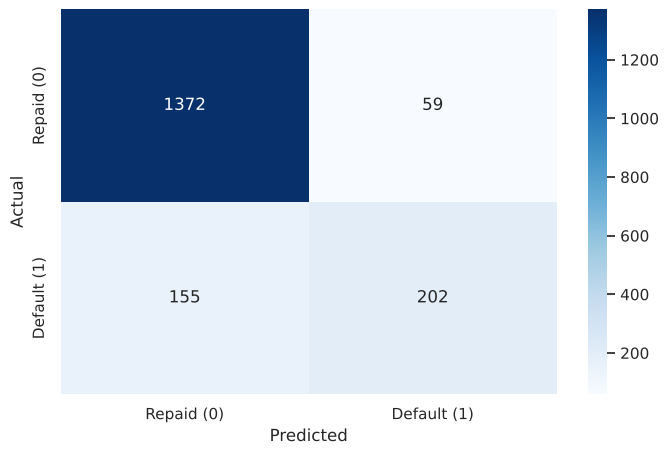

In [50]:
#@title
#Predict for test set
y_pred_test = lg.predict(X_test_lr)

#checking the performance on the test dataset
metrics_score(y_test, y_pred_test)

Train performance - Logistic Regression (balanced)
              precision    recall  f1-score   support

           0      0.951     0.863     0.905      3340
           1      0.598     0.821     0.692       832

    accuracy                          0.854      4172
   macro avg      0.774     0.842     0.798      4172
weighted avg      0.880     0.854     0.862      4172



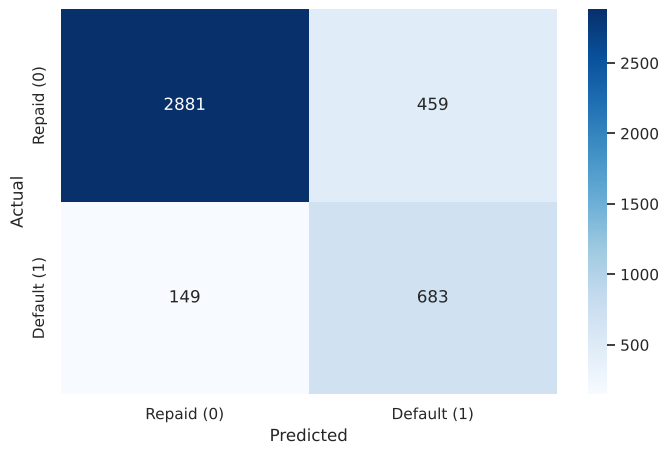

Test performance - Logistic Regression (balanced)
              precision    recall  f1-score   support

           0      0.945     0.872     0.907      1431
           1      0.608     0.796     0.689       357

    accuracy                          0.857      1788
   macro avg      0.776     0.834     0.798      1788
weighted avg      0.878     0.857     0.864      1788



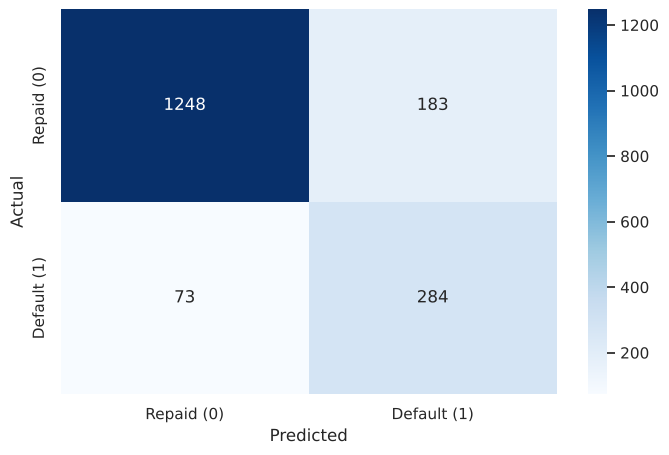

In [51]:
#@title
# Logistic regression with balanced class weights, to counter the 1:4 imbalance
lg_bal = LogisticRegression(max_iter=2000, class_weight='balanced', random_state=1)
lg_bal.fit(X_train_lr, y_train)

print("Train performance - Logistic Regression (balanced)")
metrics_score(y_train, lg_bal.predict(X_train_lr))
print("Test performance - Logistic Regression (balanced)")
metrics_score(y_test, lg_bal.predict(X_test_lr))

In [52]:
#@title
# Tune the regularisation strength C of the balanced model by 5-fold cross-validated grid search on recall
from sklearn.model_selection import StratifiedKFold
lr_search = GridSearchCV(LogisticRegression(max_iter=2000, class_weight='balanced', random_state=1), {'C': [0.01, 0.1, 1, 10]},
                         scoring='recall', cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=1), n_jobs=-1)
lr_search.fit(X_train_lr, y_train)
print("Best C:", lr_search.best_params_, f"| best CV recall: {lr_search.best_score_:.3f}")
print(pd.DataFrame(lr_search.cv_results_)[['param_C', 'mean_test_score']].rename(columns={'mean_test_score': 'CV recall'}).round(3).to_string(index=False))

# Keep the best estimator as the balanced model
lg_bal = lr_search.best_estimator_

Best C: {'C': 1} | best CV recall: 0.814
 param_C  CV recall
    0.01      0.796
    0.10      0.804
    1.00      0.814
   10.00      0.811


**Observations:**
- The plain logistic regression is accurate overall (88% on test) but catches only **57% of defaulters**: it favours the majority "repaid" class.
- Balancing the class weights raises test recall to **80%**, while precision falls to 61% and accuracy to 86%. The model catches about 23 more defaulters out of every 100, at the cost of rejecting more good applicants.
- Train and test scores are close, so the linear model does not over-fit. Its limit is that a straight line cannot capture the threshold effects that the EDA showed.
- A 5-fold grid search over the regularisation strength keeps C = 1 (cross-validated recall 0.814). So the balanced model is already the tuned one.

#### Let's check the coefficients, and check which variables are important and how they affect the process of loan approval

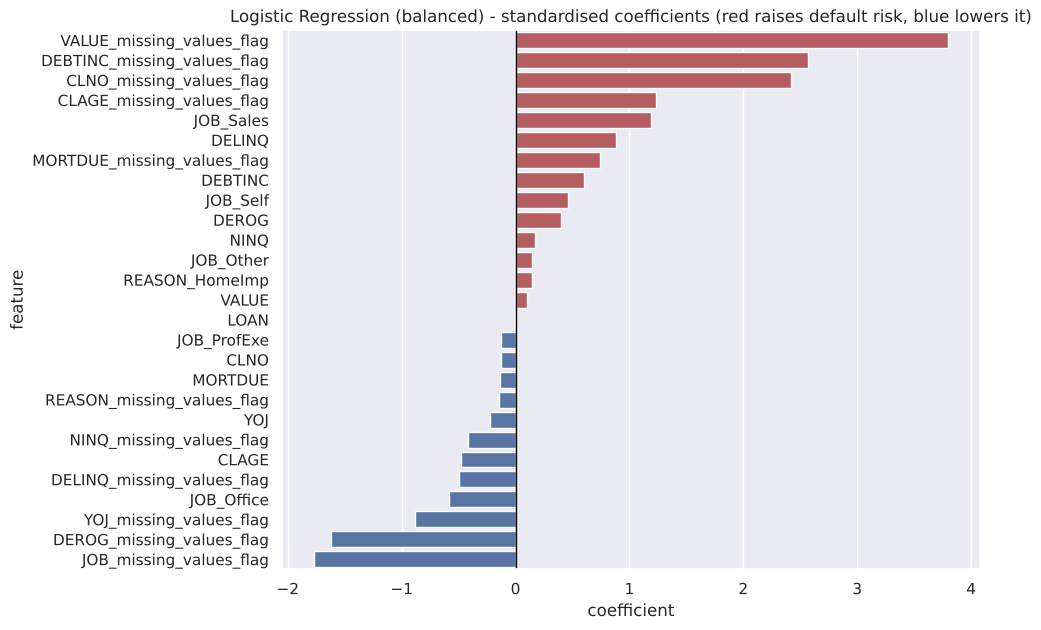

,feature,coefficient,odds_ratio,unit
0,VALUE_missing_values_flag,3.796636,44.551070,flag 0 -> 1
1,DEBTINC_missing_values_flag,2.570614,13.073847,flag 0 -> 1
2,CLNO_missing_values_flag,2.417200,11.214419,flag 0 -> 1
3,CLAGE_missing_values_flag,1.237044,3.445414,flag 0 -> 1
4,JOB_Sales,1.192855,3.296480,flag 0 -> 1
5,DELINQ,0.884392,2.421511,per 1 standard deviation
6,MORTDUE_missing_values_flag,0.744984,2.106407,flag 0 -> 1
7,DEBTINC,0.599562,1.821321,per 1 standard deviation
8,JOB_Self,0.461802,1.586931,flag 0 -> 1
9,DEROG,0.401372,1.493873,per 1 standard deviation


In [53]:
#@title
# Printing the coefficients of logistic regression (balanced model). Continuous inputs are standardised, so their
# coefficients are per standard deviation; flags and dummies are 0/1, so theirs are the effect of switching the flag on.
coef = pd.DataFrame({'feature': X_train_lr.columns, 'coefficient': lg_bal.coef_[0]})
coef['odds_ratio'] = np.exp(coef['coefficient'])
coef['unit'] = ['per 1 standard deviation' if f in continuous else 'flag 0 -> 1' for f in coef['feature']]
coef = coef.sort_values('coefficient', ascending=False).reset_index(drop=True)

plt.figure(figsize=(9, 7))
sns.barplot(data=coef, x='coefficient', y='feature', palette=['#C44E52' if c > 0 else '#4C72B0' for c in coef['coefficient']])
plt.axvline(0, color='black', linewidth=1)
plt.title('Logistic Regression (balanced) - standardised coefficients (red raises default risk, blue lowers it)')
plt.show()
coef

**Insights:**
- **Risk-increasing:** the missing-value flags dominate. An application with no property valuation has odds of default about 45 times higher, all else equal. An application with no debt-to-income ratio has odds about 13 times higher, all else equal. The flags are 0/1, so these odds ratios are the full effect of the flag. Among the continuous inputs, `DELINQ` (odds ratio about 2.4 per standard deviation) and `DEBTINC` (about 1.8) matter most, followed by `DEROG` and `NINQ`. The `JOB_Sales` indicator roughly triples the odds relative to a manager.
- **Risk-decreasing:** `CLAGE` lowers the risk (longer credit history, odds ratio about 0.6 per standard deviation). `YOJ`, `JOB_Office` and the `DEROG`/`JOB`/`YOJ`/`DELINQ` missing flags also lower the risk. In the EDA, the groups for which these fields were blank defaulted less often.
- `LOAN` has almost no linear effect once the model includes the other variables. Its relationship with default is non-linear (small loans are riskier, large ones are not).
- `MORTDUE` and `VALUE` have opposite signs of similar size, the classic symptom of their 0.88 correlation. Do not over-interpret these two coefficients individually.
- The signs agree with the EDA and with lending common sense, which gives confidence that the model learns real risk rather than noise.

### **Think about it:**
- The above Logistic regression model was build on the threshold of 0.5, can we use different threshold?
- How to get an optimal threshold and which curve will help you achieve?
- How does, accuracy, precision and recall change on the threshold?

*Yes. The model outputs a probability and 0.5 is only a convention. The precision-recall curve (or the ROC curve) plotted against the threshold shows the trade-off. Lowering the threshold raises recall and lowers precision and accuracy, and raising it does the reverse. The optimal threshold is the one that minimises the business cost of the two errors. The cell below shows the trade-off for the balanced model.*

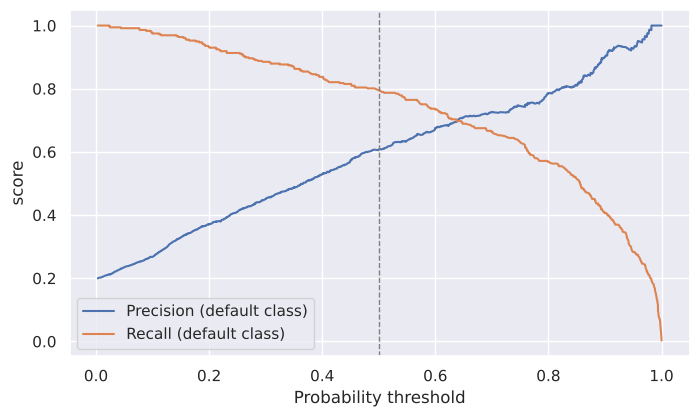

,threshold,recall,precision,f1,accuracy
0,0.3,0.885,0.451,0.597,0.762
1,0.4,0.838,0.529,0.649,0.819
2,0.5,0.796,0.608,0.689,0.857
3,0.6,0.734,0.675,0.703,0.876


In [54]:
#@title
# Precision and recall of the balanced logistic regression at different thresholds (test set)
from sklearn.metrics import precision_recall_curve
proba_lr = lg_bal.predict_proba(X_test_lr)[:, 1]
prec, rec, thr = precision_recall_curve(y_test, proba_lr)
plt.figure(figsize=(8, 4.5))
plt.plot(thr, prec[:-1], label='Precision (default class)')
plt.plot(thr, rec[:-1], label='Recall (default class)')
plt.axvline(0.5, color='grey', linestyle='--', linewidth=1)
plt.xlabel('Probability threshold'); plt.ylabel('score'); plt.legend(); plt.show()

rows = []
for t in [0.3, 0.4, 0.5, 0.6]:
    p = (proba_lr > t).astype(int)
    rows.append({'threshold': t, 'recall': recall_score(y_test, p), 'precision': precision_score(y_test, p),
                 'f1': f1_score(y_test, p), 'accuracy': accuracy_score(y_test, p)})
pd.DataFrame(rows).round(3)

### **Build a Decision Tree Model**

### **Think about it:**
- In Logistic regression we treated the outliers and built the model, should we do the same for tree based models or not? If not, why?

*No. A tree splits on the rank order of a variable ("is DEBTINC above 43.7?"), so an extreme value simply falls into the top bucket. The extreme value does not pull the split the way it pulls a regression line. Capping would only merge the largest values into one value. We therefore build the tree models on the untreated data (`data`), with the same missing-value flags and imputation.*

#### Data Preparation for the tree based model

In [55]:
#@title
# Add binary flags
# List of columns that has missing values in it
missing_col = [col for col in data.columns if data[col].isnull().any()]

for colmn in missing_col:
    add_binary_flag(data,colmn)
    

In [56]:
#@title
#  Treat Missing values in numerical columns with median and mode in categorical variables
# Select numeric columns.
num_data = data.select_dtypes('number')

# Select string and object columns.
cat_data = data.select_dtypes('category').columns.tolist()#df.select_dtypes('object')

# Fill numeric columns with the median of the training rows.
data[num_data.columns] = num_data.fillna(num_data.loc[train_idx].median())

# Fill object columns with the mode of the training rows.
for column in cat_data:
    mode = data.loc[train_idx, column].mode()[0]
    data[column] = data[column].fillna(mode)

print("Remaining missing values:", data.isnull().sum().sum())

Remaining missing values: 0


#### Separating the target variable y and independent variable x

In [57]:
#@title
# Drop dependent variable from dataframe and create the X(independent variable) matrix
X = data.drop(['BAD'], axis=1)

# Create dummy variables for the categorical variables
X = pd.get_dummies(X, columns=['REASON', 'JOB'], drop_first=True, dtype=int)

# Create y(dependent varibale)
y = data['BAD'].astype(int)

print("Feature columns:", list(X.columns))

Feature columns: ['LOAN', 'MORTDUE', 'VALUE', 'YOJ', 'DEROG', 'DELINQ', 'CLAGE', 'NINQ', 'CLNO', 'DEBTINC', 'MORTDUE_missing_values_flag', 'VALUE_missing_values_flag', 'REASON_missing_values_flag', 'JOB_missing_values_flag', 'YOJ_missing_values_flag', 'DEROG_missing_values_flag', 'DELINQ_missing_values_flag', 'CLAGE_missing_values_flag', 'NINQ_missing_values_flag', 'CLNO_missing_values_flag', 'DEBTINC_missing_values_flag', 'REASON_HomeImp', 'JOB_Office', 'JOB_Other', 'JOB_ProfExe', 'JOB_Sales', 'JOB_Self']


#### Split the data

In [58]:
#@title
# Split the data into training and test set (the same held-out applicants as for the linear model)
X_train, X_test = X.loc[train_idx], X.loc[test_idx]
y_train, y_test = y.loc[train_idx], y.loc[test_idx]
print("Train shape:", X_train.shape, "Test shape:", X_test.shape)

Train shape: (4172, 27) Test shape: (1788, 27)


In [59]:
#@title
#Defining Decision tree model with class weights class_weight={0: 0.2, 1: 0.8}
dt = DecisionTreeClassifier(class_weight={0: 0.2, 1: 0.8}, random_state=1)

In [60]:
#@title
#fitting Decision tree model
dt.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",1
,"class_weight class_weight: dict, list of dict or ""balanced"", default=NoneWeights associated with classes in the form ``{class_label: weight}``.If None, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.","{0: 0.2, 1: 0.8}"
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, in

#### Checking the performance on the train dataset

              precision    recall  f1-score   support

           0      1.000     1.000     1.000      3340
           1      1.000     1.000     1.000       832

    accuracy                          1.000      4172
   macro avg      1.000     1.000     1.000      4172
weighted avg      1.000     1.000     1.000      4172



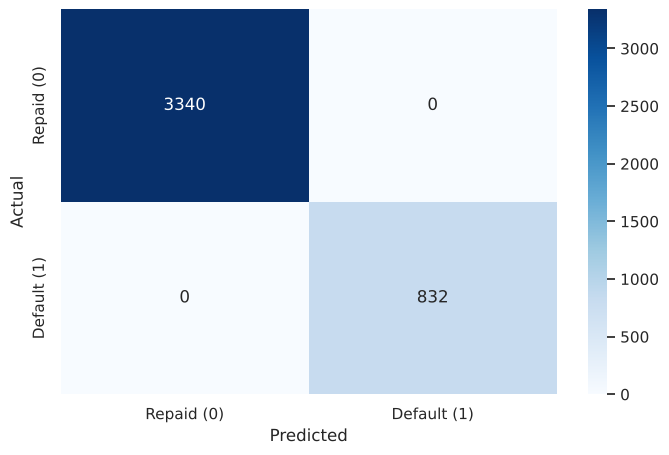

In [61]:
#@title
# Checking performance on the training data
metrics_score(y_train, dt.predict(X_train))

#### Checking the performance on the test dataset

              precision    recall  f1-score   support

           0      0.908     0.940     0.923      1431
           1      0.719     0.616     0.664       357

    accuracy                          0.875      1788
   macro avg      0.813     0.778     0.794      1788
weighted avg      0.870     0.875     0.872      1788



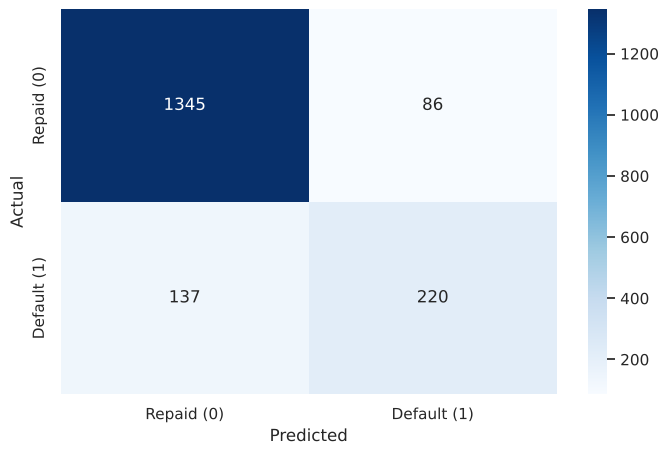

Tree depth: 22 | number of leaves: 464


In [62]:
#@title
# Checking performance on the testing data
metrics_score(y_test, dt.predict(X_test))
print("Tree depth:", dt.get_depth(), "| number of leaves:", dt.get_n_leaves())

**Insights:**
- The fully grown tree is a textbook case of **over-fitting**. It scores 100% recall, precision and accuracy on the training rows but only about **62% recall** and 72% precision on the test set. It memorised the training applicants (dozens of levels deep, hundreds of leaves) instead of learning general rules.
- The class weights do not help an un-pruned tree. They change which splits the tree chooses (this is a different tree). They cannot change the fact that a fully grown tree fits every training applicant perfectly. Its test predictions therefore remain those of an over-fitted tree. Class weights only help once we constrain (prune) the tree, which the grid search does next.

### **Think about it:**
- Can we improve this model?
- How to get optimal parameters in order to get the best possible results?

*Yes: by pruning. Limiting the depth and the minimum number of applicants per leaf stops the tree from memorising. Combining that with class weights lets it favour the defaulter class. There is no formula for the best settings, so we find them by grid search with cross-validation on the training rows, scoring on recall.*

### **Decision Tree - Hyperparameter Tuning**

* Hyperparameter tuning is tricky in the sense that **there is no direct way to calculate how a change in the hyperparameter value will reduce the loss of your model**, so we usually resort to experimentation. We'll use Grid search to perform hyperparameter tuning.
* **Grid search is a tuning technique that attempts to compute the optimum values of hyperparameters.** 
* **It is an exhaustive search** that is performed on the specific parameter values of a model.
* The parameters of the estimator/model used to apply these methods are **optimized by cross-validated grid-search** over a parameter grid.

**Criterion {“gini”, “entropy”}**

The function to measure the quality of a split. Supported criteria are “gini” for the Gini impurity and “entropy” for the information gain.

**max_depth** 

The maximum depth of the tree. If None, then nodes are expanded until all leaves are pure or until all leaves contain less than min_samples_split samples.

**min_samples_leaf**

The minimum number of samples is required to be at a leaf node. A split point at any depth will only be considered if it leaves at least min_samples_leaf training samples in each of the left and right branches. This may have the effect of smoothing the model, especially in regression.

You can learn about more Hyperpapameters on this link and try to tune them. 

https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html


#### Using GridSearchCV for Hyperparameter tuning on the model

In [63]:
#@title
# Choose the type of classifier.
dtree_estimator = DecisionTreeClassifier(random_state=1)

# Grid of parameters to choose from
parameters = {'max_depth': [3, 4, 5, 6, 8, 10, None],
              'min_samples_leaf': [1, 5, 10, 20, 50],
              'criterion': ['gini', 'entropy'],
              'class_weight': [None, 'balanced', {0: 0.2, 1: 0.8}]}

# Type of scoring used to compare parameter combinations
scorer = metrics.make_scorer(metrics.recall_score)

# Run the grid search
from sklearn.model_selection import StratifiedKFold
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=1)
grid_obj = GridSearchCV(dtree_estimator, parameters, scoring=scorer, cv=cv, n_jobs=-1)

# Fit the GridSearch on train dataset
grid_obj = grid_obj.fit(X_train, y_train)

# Set the clf to the best combination of parameters
dtree_estimator = grid_obj.best_estimator_

# Fit the best algorithm to the data.
dtree_estimator.fit(X_train, y_train)
print("Best parameters:", grid_obj.best_params_)
print(f"Best cross-validated recall: {grid_obj.best_score_:.3f}")

Best parameters: {'class_weight': 'balanced', 'criterion': 'gini', 'max_depth': None, 'min_samples_leaf': 20}
Best cross-validated recall: 0.826


#### Checking the performance on the train dataset

              precision    recall  f1-score   support

           0      0.977     0.826     0.895      3340
           1      0.569     0.921     0.703       832

    accuracy                          0.845      4172
   macro avg      0.773     0.874     0.799      4172
weighted avg      0.895     0.845     0.857      4172



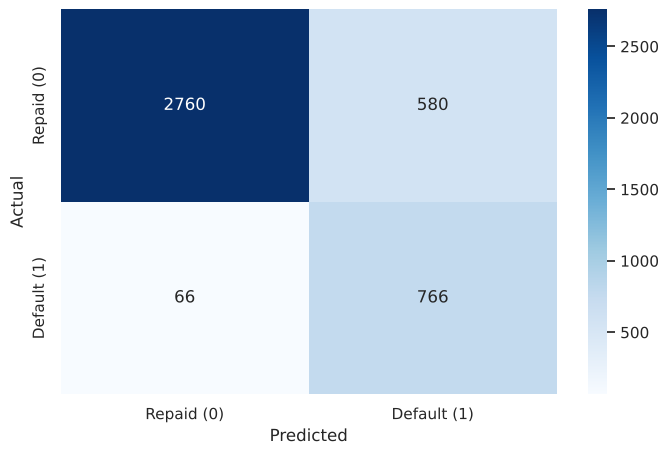

In [64]:
#@title
# Checking performance on the training data based on the tuned model
metrics_score(y_train, dtree_estimator.predict(X_train))

#### Checking the performance on the test dataset

              precision    recall  f1-score   support

           0      0.948     0.819     0.879      1431
           1      0.531     0.821     0.645       357

    accuracy                          0.819      1788
   macro avg      0.740     0.820     0.762      1788
weighted avg      0.865     0.819     0.832      1788



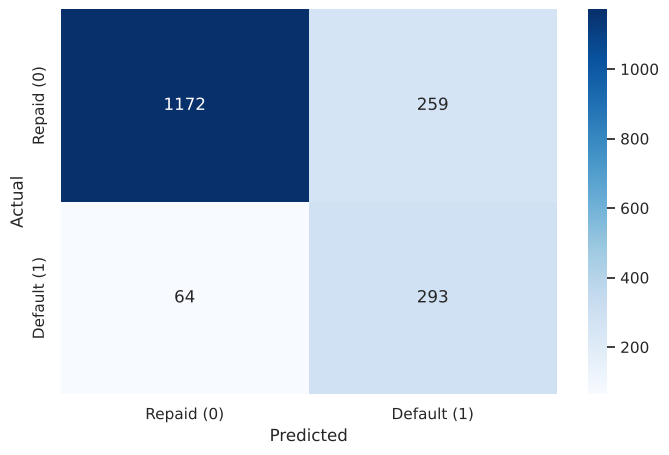

Tree depth: 14 | number of leaves: 106


In [65]:
#@title
# Checking performance on the testing data based on the tuned model
metrics_score(y_test, dtree_estimator.predict(X_test))
print("Tree depth:", dtree_estimator.get_depth(), "| number of leaves:", dtree_estimator.get_n_leaves())

**Insights:**
- Pruning with balanced class weights lifts **test recall to about 82%**, the highest of the single-model approaches. The pruned tree has a minimum of 20 applicants per leaf, which cuts it from several hundred leaves to about 100. The train-test gap narrows to about 10 points (92% vs 82%).
- The price is precision: only about 53% of the applicants the tree rejects would actually have defaulted, and accuracy falls to about 82%. The tree is deliberately cautious. Whether that is acceptable depends on how much good business the bank is willing to reject. The Random Forest below improves this balance.

#### Plotting the Decision Tree

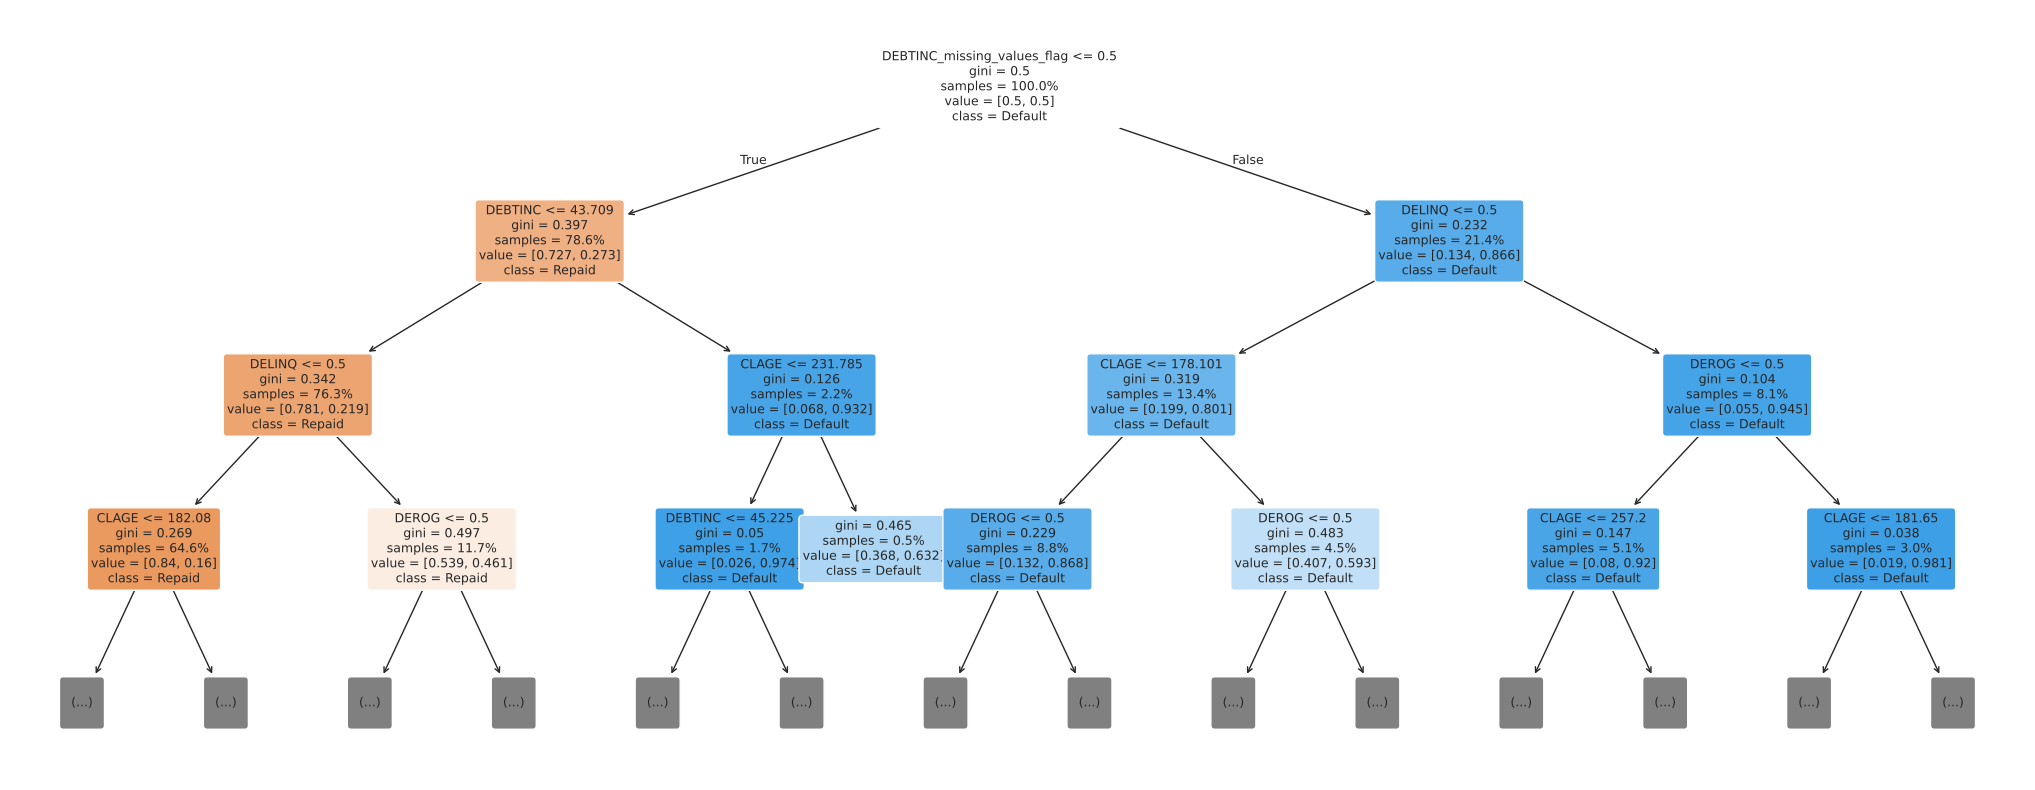

|--- DEBTINC_missing_values_flag <= 0.50
|   |--- DEBTINC <= 43.71
|   |   |--- DELINQ <= 0.50
|   |   |   |--- CLAGE <= 182.08
|   |   |   |   |--- MORTDUE <= 58022.00
|   |   |   |   |   |--- truncated branch of depth 6
|   |   |   |   |--- MORTDUE >  58022.00
|   |   |   |   |   |--- truncated branch of depth 10
|   |   |   |--- CLAGE >  182.08
|   |   |   |   |--- VALUE <= 284446.50
|   |   |   |   |   |--- truncated branch of depth 9
|   |   |   |   |--- VALUE >  284446.50
|   |   |   |   |   |--- class: 0
|   |   |--- DELINQ >  0.50
|   |   |   |--- DEROG <= 0.50
|   |   |   |   |--- CLAGE <= 83.58
|   |   |   |   |   |--- class: 1
|   |   |   |   |--- CLAGE >  83.58
|   |   |   |   |   |--- truncated branch of depth 7
|   |   |   |--- DEROG >  0.50
|   |   |   |   |--- CLNO <= 18.50
|   |   |   |   |   |--- class: 1
|   |   |   |   |--- CLNO >  18.50
|   |   |   |   |   |--- truncated branch of depth 2
|   |--- DEBTINC >  43.71
|   |   |--- CLAGE <= 231.79
|   |   |   |--- DEBTI

In [66]:
#@title
# Plot the decision  tree (first three levels; the full tree is deeper) and print the rules of the first four levels
from sklearn.tree import plot_tree, export_text
plt.figure(figsize=(26, 10))
plot_tree(dtree_estimator, feature_names=list(X_train.columns), class_names=['Repaid', 'Default'],
          filled=True, rounded=True, max_depth=3, fontsize=9, proportion=True)
plt.show()

print(export_text(dtree_estimator, feature_names=list(X_train.columns), max_depth=4, show_weights=False))

In [67]:
#@title
# The tree was fitted with balanced class weights, so a leaf labelled 'class: 1' means a raw default rate above roughly 20%,
# not a near-certain default. Observed default rates (training rows) of the groups defined by the first splits:
tr = data.loc[train_idx]
root_split = dtree_estimator.tree_.threshold[dtree_estimator.tree_.children_left[0]]
groups = {
    'Debt-to-income ratio missing': tr['DEBTINC_missing_values_flag'] == 1,
    f'Ratio recorded and above {root_split:.1f}%': (tr['DEBTINC_missing_values_flag'] == 0) & (tr['DEBTINC'] > root_split),
    f'Ratio recorded, at most {root_split:.1f}%, 1+ delinquent lines': (tr['DEBTINC_missing_values_flag'] == 0) & (tr['DEBTINC'] <= root_split) & (tr['DELINQ'] >= 1),
    f'Ratio recorded, at most {root_split:.1f}%, no delinquent lines': (tr['DEBTINC_missing_values_flag'] == 0) & (tr['DEBTINC'] <= root_split) & (tr['DELINQ'] == 0),
}
pd.DataFrame({'applicants': {k: int(v.sum()) for k, v in groups.items()},
              'default_rate_%': {k: round(tr.loc[v, 'BAD'].astype(int).mean() * 100, 1) for k, v in groups.items()}})

,applicants,default_rate_%
Debt-to-income ratio missing,894,61.7
Ratio recorded and above 43.7%,93,77.4
"Ratio recorded, at most 43.7%, 1+ delinquent lines",490,17.6
"Ratio recorded, at most 43.7%, no delinquent lines",2695,4.5


#### Deduce the business rules apparent from the Decision Tree and write them down:

1. **Is the debt-to-income ratio missing?** If yes, the applicant is in a high-risk group (about 62% of these applicants defaulted). When income is unverified, the bank should reject the applicant or require income verification.
2. **If the ratio is recorded, is it above about 44%?** If yes, roughly three out of four such applicants defaulted (and above 45% the EDA showed 87-100%). Decline the application.
3. **Below that ratio, how many delinquent credit lines does the applicant have?** With none, only about 4-5% default, the safest group in the book. One or more delinquent lines push the applicant back into the risky branch.
4. **Among the remaining applicants, how long is the credit history (CLAGE) and are there derogatory reports (DEROG)?** Short histories (under about 15 years) with any derogatory report are risky. Long clean histories are safe.
5. **In the "ratio missing" branch the tree asks the same questions again** (delinquencies, derogatory reports, credit-history length, loan size). Almost every path that combines a missing ratio with a delinquency or derogatory report ends in "default".

These rules match the EDA findings, which is reassuring. The model formalises the patterns in the data rather than inventing new ones. The bank can quote each rule to an applicant as the reason for a decision.

### **Bagging (Bootstrap Aggregating): the step between one tree and a Random Forest**

A single tree has high variance: small changes in the training rows produce a different tree. Bagging trains many trees, each on a bootstrap sample of the training applicants, and combines their votes. This lowers variance without raising bias. A Random Forest is bagging plus a random subset of features at every split. Building a plain bagged ensemble first shows how much of the improvement comes from bagging alone.

Train performance - Bagging


              precision    recall  f1-score   support

           0      1.000     1.000     1.000      3340
           1      1.000     1.000     1.000       832

    accuracy                          1.000      4172
   macro avg      1.000     1.000     1.000      4172
weighted avg      1.000     1.000     1.000      4172



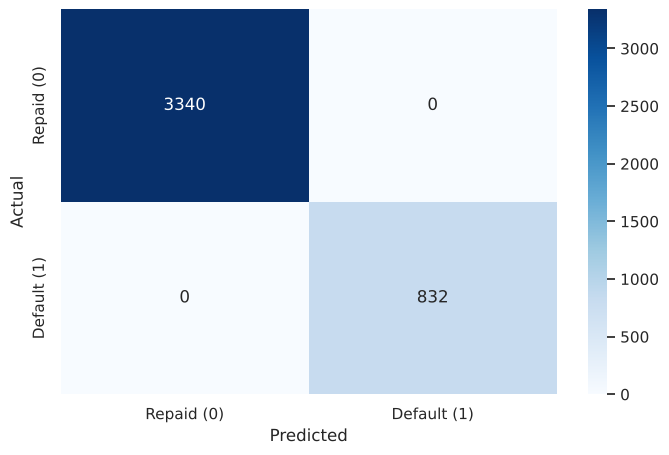

Test performance - Bagging


              precision    recall  f1-score   support

           0      0.924     0.964     0.944      1431
           1      0.827     0.683     0.748       357

    accuracy                          0.908      1788
   macro avg      0.876     0.824     0.846      1788
weighted avg      0.905     0.908     0.905      1788



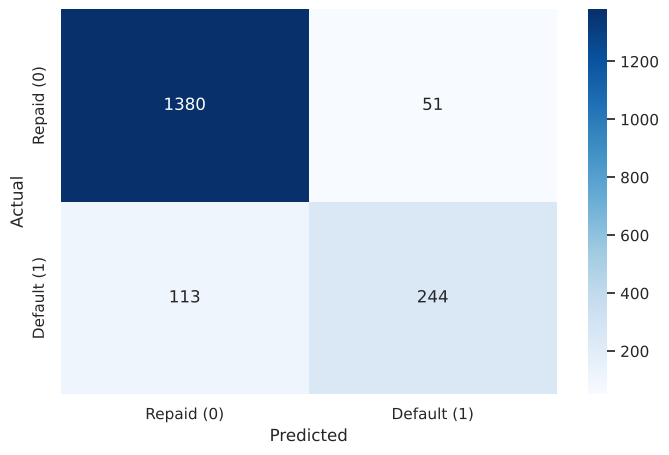

In [68]:
#@title
# Bagging of 200 fully grown decision trees
bagging = BaggingClassifier(estimator=DecisionTreeClassifier(random_state=1), n_estimators=200, random_state=1, n_jobs=-1)
bagging.fit(X_train, y_train)

print("Train performance - Bagging")
metrics_score(y_train, bagging.predict(X_train))
print("Test performance - Bagging")
metrics_score(y_test, bagging.predict(X_test))

**Insights:** Averaging 200 trees lifts test precision from about 71-72% (single tree) to 83% at about 68% recall, and overall accuracy to 91%. The ensemble is right far more often when it flags a defaulter. Train recall is still 100%, so bagging limits the damage of over-fitting on unseen data rather than removing it. The bagged ensemble still misses about a third of defaulters. The Random Forest adds feature sub-sampling. Class weights or a lower decision threshold can then trade precision for recall.

### **Building a Random Forest Classifier**

**Random Forest is a bagging algorithm where the base models are Decision Trees.** Samples are taken from the training data and on each sample a decision tree makes a prediction. 

**The results from all the decision trees are combined together and the final prediction is made using voting or averaging.**

In [69]:
#@title
# Defining Random forest CLassifier
rf_estimator = RandomForestClassifier(n_estimators=200, random_state=1, n_jobs=-1)
rf_estimator.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",1
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total 

#### Checking the performance on the train dataset

              precision    recall  f1-score   support

           0      1.000     1.000     1.000      3340
           1      1.000     1.000     1.000       832

    accuracy                          1.000      4172
   macro avg      1.000     1.000     1.000      4172
weighted avg      1.000     1.000     1.000      4172



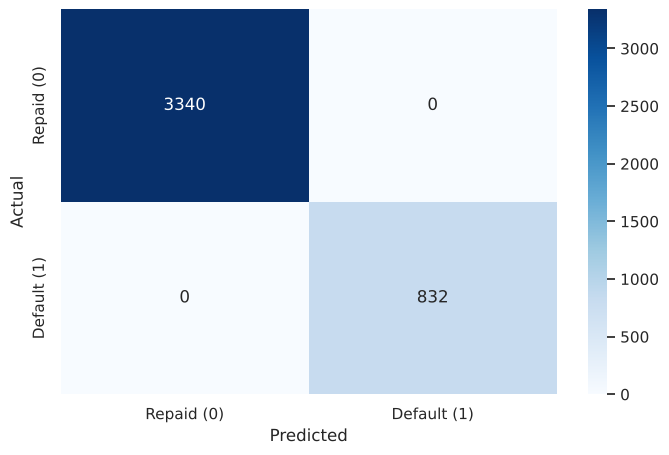

In [70]:
#@title
#Checking performance on the training data
metrics_score(y_train, rf_estimator.predict(X_train))

#### Checking the performance on the test dataset

              precision    recall  f1-score   support

           0      0.925     0.968     0.946      1431
           1      0.842     0.686     0.756       357

    accuracy                          0.912      1788
   macro avg      0.884     0.827     0.851      1788
weighted avg      0.909     0.912     0.908      1788



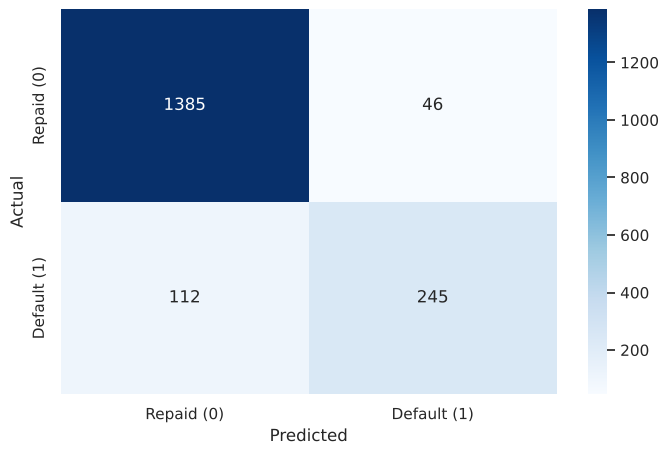

In [71]:
#@title
# Checking performance on the test data
metrics_score(y_test, rf_estimator.predict(X_test))

**Observations:**
- Like the single tree, the forest fits the training rows perfectly. On the test set it is much stronger: about **69% recall with 84% precision** and 91% accuracy.
- The forest is conservative about flagging an applicant as a defaulter. When it does, it is right 84% of the time, but it still misses about a third of the defaulters. Class weights should shift that balance towards recall.

### **Build a Random Forest model with Class Weights**

In [72]:
#@title
# Defining Random Forest model with class weights class_weight={0: 0.2, 1: 0.8}
rf_estimator_weighted = RandomForestClassifier(n_estimators=200, class_weight={0: 0.2, 1: 0.8}, random_state=1, n_jobs=-1)

# Fitting Random Forest model
rf_estimator_weighted.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",1
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.","{0: 0.2, 1: 0.8}"
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider 

#### Checking the performance on the train dataset

              precision    recall  f1-score   support

           0      1.000     0.998     0.999      3340
           1      0.993     1.000     0.996       832

    accuracy                          0.999      4172
   macro avg      0.996     0.999     0.998      4172
weighted avg      0.999     0.999     0.999      4172



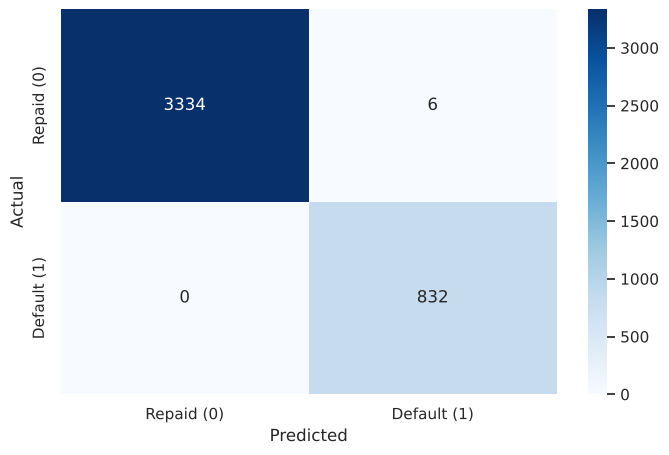

In [73]:
#@title
# Checking performance on the train data
metrics_score(y_train, rf_estimator_weighted.predict(X_train))

#### Checking the performance on the test dataset

              precision    recall  f1-score   support

           0      0.943     0.942     0.943      1431
           1      0.769     0.773     0.771       357

    accuracy                          0.908      1788
   macro avg      0.856     0.858     0.857      1788
weighted avg      0.908     0.908     0.908      1788



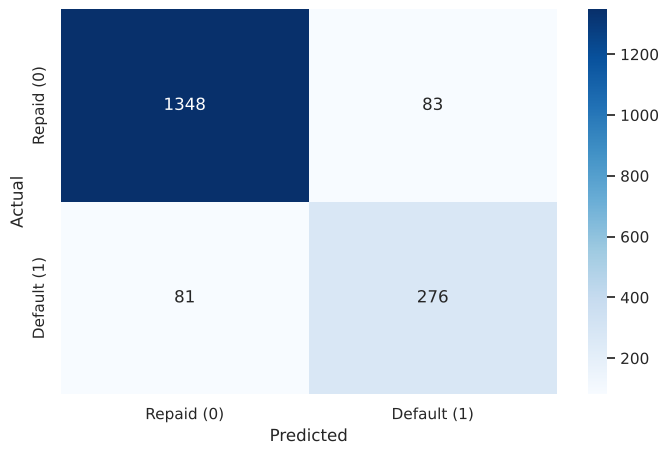

In [74]:
#@title
# Checking performance on the test data
metrics_score(y_test, rf_estimator_weighted.predict(X_test))

**Observations:** Class weights lift **test recall to about 77%** while precision stays near 77% and accuracy near 91%. Unlike the single tree, the forest's recall responds to class weights at the 0.5 threshold. The weights shift the ensemble's averaged probabilities, which moves applicants across the fixed threshold. We test whether that shift is better than simply moving the threshold when we choose the final model. This is the best balance of recall and precision so far. It catches almost as many defaulters as the balanced logistic regression (77% vs 80%) with far higher precision (77% vs 61%).

### **Think about it:**
- Can we try different weights?
- If yes, should we increase or decrease class weights for different classes?

*Yes. Raising the weight of the defaulter class pushes the forest towards flagging more applicants (higher recall, lower precision). Lowering it does the reverse. The grid search below tries 0.2/0.8 and `balanced` (which weights classes inversely to their frequency, about 0.62/2.5). The threshold analysis later shows that moving the decision threshold is an even finer dial for the same trade-off.*

### **Tuning the Random Forest**

* Hyperparameter tuning is tricky in the sense that **there is no direct way to calculate how a change in the hyperparameter value will reduce the loss of your model**, so we usually resort to experimentation. We'll use Grid search to perform hyperparameter tuning.
* **Grid search is a tuning technique that attempts to compute the optimum values of hyperparameters.** 
* **It is an exhaustive search** that is performed on the specific parameter values of a model.
* The parameters of the estimator/model used to apply these methods are **optimized by cross-validated grid-search** over a parameter grid.


**n_estimators**: The number of trees in the forest.

**min_samples_split**: The minimum number of samples required to split an internal node:

**min_samples_leaf**: The minimum number of samples required to be at a leaf node. 

**max_features{“auto”, “sqrt”, “log2”, 'None'}**: The number of features to consider when looking for the best split.

- If “auto”, then max_features=sqrt(n_features).

- If “sqrt”, then max_features=sqrt(n_features) (same as “auto”).

- If “log2”, then max_features=log2(n_features).

- If None, then max_features=n_features.

You can learn more about Random Forest Hyperparameters from the link given below and try to tune them

https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html

#### **Warning:** This may take a long time depending on the parameters you tune. 

In [75]:
#@title
# Choose the type of classifier.
rf_estimator_tuned = RandomForestClassifier(random_state=1, n_jobs=-1)

# Grid of parameters to choose from
parameters = {'n_estimators': [150, 300],
              'max_depth': [6, 10, None],
              'min_samples_leaf': [1, 5, 10],
              'max_features': ['sqrt', 0.5],
              'class_weight': ['balanced', {0: 0.2, 1: 0.8}]}

# Type of scoring used to compare parameter combinations
scorer = metrics.make_scorer(metrics.recall_score)

# Run the grid search (3 folds keep the run time reasonable for the larger forest grid)
cv3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=1)
grid_obj = GridSearchCV(rf_estimator_tuned, parameters, scoring=scorer, cv=cv3, n_jobs=-1)

#fit the GridSearch on train dataset
grid_obj = grid_obj.fit(X_train, y_train)

# Set the clf to the best combination of parameters
rf_estimator_tuned = grid_obj.best_estimator_

# Fit the best algorithm to the data.
rf_estimator_tuned.fit(X_train, y_train)
print("Best parameters:", grid_obj.best_params_)
print(f"Best cross-validated recall: {grid_obj.best_score_:.3f}")

Best parameters: {'class_weight': 'balanced', 'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 10, 'n_estimators': 300}
Best cross-validated recall: 0.811


#### Checking the performance on the train dataset

              precision    recall  f1-score   support

           0      0.978     0.901     0.938      3340
           1      0.699     0.918     0.794       832

    accuracy                          0.905      4172
   macro avg      0.838     0.910     0.866      4172
weighted avg      0.922     0.905     0.909      4172



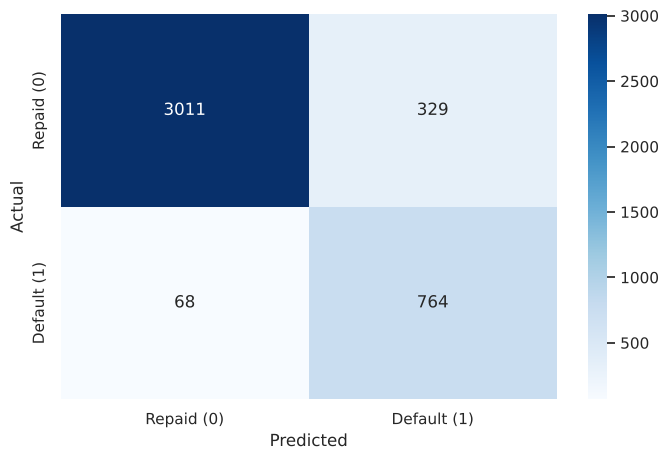

In [76]:
#@title
# Checking performance on the training data
metrics_score(y_train, rf_estimator_tuned.predict(X_train))

#### Checking the performance on the test dataset

              precision    recall  f1-score   support

           0      0.945     0.897     0.920      1431
           1      0.656     0.790     0.717       357

    accuracy                          0.875      1788
   macro avg      0.800     0.843     0.818      1788
weighted avg      0.887     0.875     0.879      1788



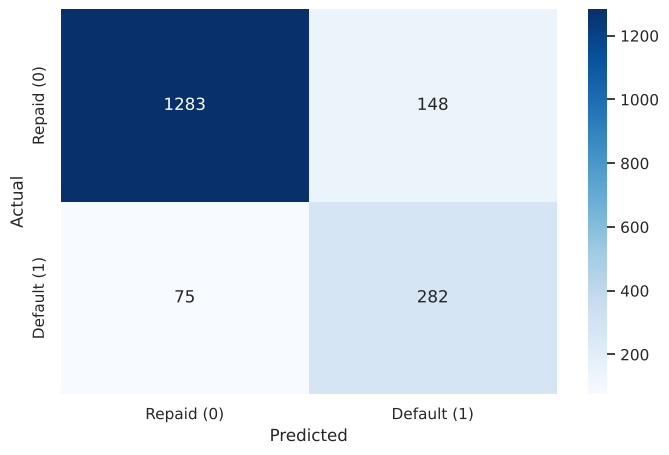

In [77]:
#@title
# Checking performace on test dataset
metrics_score(y_test, rf_estimator_tuned.predict(X_test))

**Insights:**
- Optimising purely for recall pushes the grid towards larger leaves (10 applicants minimum) and balanced weights. Test recall lands at about **79%**, close to the weighted forest. Precision drops to about 66% because the forest becomes more willing to flag borderline applicants.
- The train-test gap shrinks (train recall is no longer 100%), so the tuned forest generalises better even though its headline test numbers are similar.
- Recall-only tuning shows the limit of a single-metric search on an imbalanced problem. Beyond a point, extra recall costs a lot of precision. The comparison below weighs the two together.

#### Plot the Feature importance of the tuned Random Forest

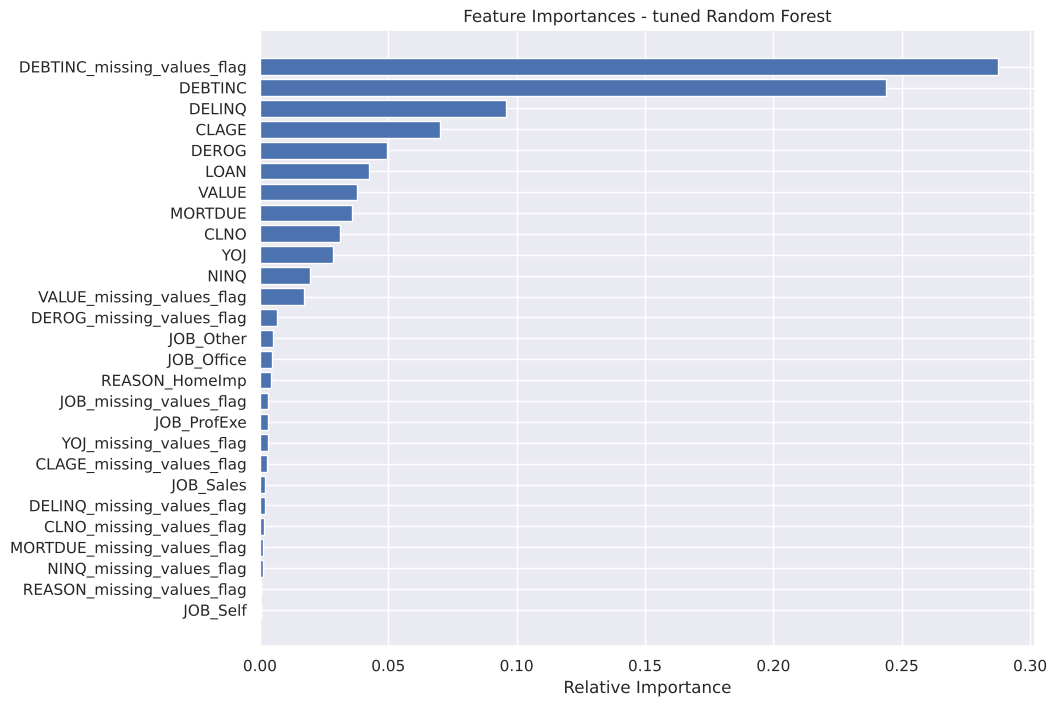

DEBTINC_missing_values_flag    0.2875
DEBTINC                        0.2438
DELINQ                         0.0957
CLAGE                          0.0703
DEROG                          0.0494
LOAN                           0.0424
VALUE                          0.0377
MORTDUE                        0.0358
CLNO                           0.0310
YOJ                            0.0284
NINQ                           0.0194
VALUE_missing_values_flag      0.0171
dtype: float64

In [78]:
#@title
# importance of features in the tree building ( The importance of a feature is computed as the
#(normalized) total reduction of the criterion brought by that feature. It is also known as the Gini importance )
importances = rf_estimator_tuned.feature_importances_
indices = np.argsort(importances)
feature_names = list(X_train.columns)

plt.figure(figsize=(10, 8))
plt.title('Feature Importances - tuned Random Forest')
plt.barh(range(len(indices)), importances[indices], color='#4C72B0', align='center')
plt.yticks(range(len(indices)), [feature_names[i] for i in indices])
plt.xlabel('Relative Importance')
plt.show()

pd.Series(importances, index=feature_names).sort_values(ascending=False).round(4).head(12)

**Insights (feature importance):** The two debt-to-income features dominate: the `DEBTINC` missing flag and `DEBTINC` together carry more than half (about 53%) of this recall-tuned forest's split power. (We show the final model's own importances, about a third for the pair, after we choose it.) This shows that affordability, and whether it could be checked, is the heart of the decision. Next come `DELINQ`, `CLAGE` and `DEROG` (repayment behaviour and depth of credit history), then `LOAN`, `VALUE`, `MORTDUE` and `CLNO`. The `JOB` and `REASON` dummies rank at the bottom: once financial behaviour is known, occupation and loan purpose add little. The selection step below tests whether occupation adds value at the cost-optimal threshold.

#### **Did tuning improve the validation scores?**

The grid searches report only the best cross-validated score. Here we score each untuned baseline on the same folds, so that we can compare before and after tuning on the training rows. The test set plays no part.

In [79]:
#@title
# Validation scores before and after tuning, on the same folds that each grid search used (training rows only)
from sklearn.base import clone
from sklearn.model_selection import cross_validate
before_after = [("Logistic Regression", "before: plain", lg, X_train_lr, cv),
                ("Logistic Regression", "after: balanced, C tuned", lg_bal, X_train_lr, cv),
                ("Decision Tree", "before: fully grown", DecisionTreeClassifier(random_state=1), X_train, cv),
                ("Decision Tree", "after: grid search", dtree_estimator, X_train, cv),
                ("Random Forest", "before: default", rf_estimator, X_train, cv3),
                ("Random Forest", "class weights 0.2/0.8", rf_estimator_weighted, X_train, cv3),
                ("Random Forest", "after: grid search", rf_estimator_tuned, X_train, cv3)]
tuning_rows = []
for technique, stage, model, X_cv, folds in before_after:
    cv_scores = cross_validate(clone(model), X_cv, y_train, cv=folds, scoring=["recall", "precision", "roc_auc"], n_jobs=-1)
    tuning_rows.append({"Technique": technique, "Stage": stage, "CV recall": cv_scores["test_recall"].mean(),
                        "CV precision": cv_scores["test_precision"].mean(), "CV ROC-AUC": cv_scores["test_roc_auc"].mean()})
pd.DataFrame(tuning_rows).set_index(["Technique", "Stage"]).round(3)

CV recall  CV precision  \
Technique           Stage                                               
Logistic Regression before: plain                 0.626         0.789   
                    after: balanced, C tuned      0.814         0.598   
Decision Tree       before: fully grown           0.644         0.663   
                    after: grid search            0.826         0.533   
Random Forest       before: default               0.703         0.829   
                    class weights 0.2/0.8         0.790         0.757   
                    after: grid search            0.811         0.640   

                                              CV ROC-AUC  
Technique           Stage                                 
Logistic Regression before: plain                  0.907  
                    after: balanced, C tuned       0.907  
Decision Tree       before: fully grown            0.781  
                    after: grid search             0.881  
Random Forest       before: default                0.954  
                    class weights 0.2/0.8          0.952  
                    after: grid search             0.921

**Observations - validation scores before and after tuning:**
- Tuning raises the cross-validated recall of each tuned technique. The logistic regression rises from 0.626 to 0.814, almost all from the balanced class weights. The decision tree rises from 0.644 to 0.826. The random forest rises from 0.703 to 0.811.
- Recall-only tuning costs precision in every case (0.789 to 0.598, 0.663 to 0.533 and 0.829 to 0.640). This is why we choose the final configuration and its threshold on expected cost later.

### **Think about it:**
- We have only built 3 models so far, Logistic Regression, Decision Tree and Random Forest
- We can build other Machine Learning classification models like kNN, LDA, QDA or even Support Vector Machines (SVM).
- Can we also perform feature engineering and create model features and build a more robust and accurate model for this problem statement?

*Both are worthwhile next steps. We added a bagged ensemble above as the bridge between one tree and a forest. Gradient boosting would be the natural next model. kNN and SVM are less attractive here because they are harder to explain to an applicant, which the ECOA requires. On features, a combined loan-to-value ratio ((LOAN + MORTDUE) / VALUE), debt-to-income bands and interaction terms would give the trees directly what they now approximate through raw-amount splits. The data has no income or loan-term field, so a payment-to-income measure is not possible. Time-series techniques from the course do not apply: each row is one application with no date or ordering.*

### **Comparing Model Performances**

In [80]:
#@title
def get_recall_score(model,flag=True,X_train=X_train,X_test=X_test):
    '''
    model : classifier to predict values of X

    '''
    a = [] # defining an empty list to store train and test results
    pred_train = model.predict(X_train)
    pred_test = model.predict(X_test)
    train_recall = metrics.recall_score(y_train,pred_train)
    test_recall = metrics.recall_score(y_test,pred_test)
    a.append(train_recall) # adding train recall to list 
    a.append(test_recall) # adding test recall to list
    
    # If the flag is set to True then only the following print statements will be dispayed. The default value is set to True.
    if flag == True: 
        print("Recall on training set : ",metrics.recall_score(y_train,pred_train))
        print("Recall on test set : ",metrics.recall_score(y_test,pred_test))
    
    return a # returning the list with train and test scores

In [81]:
#@title
##  Function to calculate precision score
def get_precision_score(model,flag=True,X_train=X_train,X_test=X_test):
    '''
    model : classifier to predict values of X

    '''
    b = []  # defining an empty list to store train and test results
    pred_train = model.predict(X_train)
    pred_test = model.predict(X_test)
    train_precision = metrics.precision_score(y_train,pred_train)
    test_precision = metrics.precision_score(y_test,pred_test)
    b.append(train_precision) # adding train precision to list
    b.append(test_precision) # adding test precision to list
    
    # If the flag is set to True then only the following print statements will be dispayed. The default value is set to True.
    if flag == True: 
        print("Precision on training set : ",metrics.precision_score(y_train,pred_train))
        print("Precision on test set : ",metrics.precision_score(y_test,pred_test))

    return b # returning the list with train and test scores

In [82]:
#@title
##  Function to calculate accuracy score
def get_accuracy_score(model,flag=True,X_train=X_train,X_test=X_test):
    '''
    model : classifier to predict values of X

    '''
    c = [] # defining an empty list to store train and test results
    train_acc = model.score(X_train,y_train)
    test_acc = model.score(X_test,y_test)
    c.append(train_acc) # adding train accuracy to list
    c.append(test_acc) # adding test accuracy to list
    
    # If the flag is set to True then only the following print statements will be dispayed. The default value is set to True.
    if flag == True:
        print("Accuracy on training set : ",model.score(X_train,y_train))
        print("Accuracy on test set : ",model.score(X_test,y_test))
    
    return c # returning the list with train and test scores

In [83]:
#@title
# Make the list of all the models built (each with the input matrix it was trained on, because the
# logistic regression uses the standardised, outlier-capped data while the tree models use the untreated data)
models = [(lg, X_train_lr, X_test_lr), (lg_bal, X_train_lr, X_test_lr),
          (dt, X_train, X_test), (dtree_estimator, X_train, X_test), (bagging, X_train, X_test),
          (rf_estimator, X_train, X_test), (rf_estimator_weighted, X_train, X_test), (rf_estimator_tuned, X_train, X_test)]

# defining empty lists to add train and test results
acc_train = []
acc_test = []
recall_train = []
recall_test = []
precision_train = []
precision_test = []

# looping through all the models to get the accuracy,recall and precision scores
for model, Xtr, Xte in models:
     # accuracy score
    j = get_accuracy_score(model,False, X_train=Xtr, X_test=Xte)
    acc_train.append(j[0])
    acc_test.append(j[1])

    # recall score
    k = get_recall_score(model,False, X_train=Xtr, X_test=Xte)
    recall_train.append(k[0])
    recall_test.append(k[1])

    # precision score
    l = get_precision_score(model,False, X_train=Xtr, X_test=Xte)
    precision_train.append(l[0])
    precision_test.append(l[1])

In [84]:
#@title
comparison_frame = pd.DataFrame({'Model':['Logistic Regression (plain)', 'Logistic Regression (balanced)', 'Decision Tree (class weights)',
                                          'Tuned Decision Tree', 'Bagging (200 trees)', 'Random Forest', 'Random Forest (class weights)', 'Tuned Random Forest'],
                                          'Train_Accuracy': acc_train,
                                          'Test_Accuracy': acc_test,
                                          'Train_Recall': recall_train,
                                          'Test_Recall': recall_test,
                                          'Train_Precision': precision_train,
                                          'Test_Precision': precision_test})
comparison_frame.round(3)

,Model,Train_Accuracy,Test_Accuracy,Train_Recall,Test_Recall,Train_Precision,Test_Precision
0,Logistic Regression (plain),0.895,0.880,0.635,0.566,0.799,0.774
1,Logistic Regression (balanced),0.854,0.857,0.821,0.796,0.598,0.608
2,Decision Tree (class weights),1.000,0.875,1.000,0.616,1.000,0.719
3,Tuned Decision Tree,0.845,0.819,0.921,0.821,0.569,0.531
4,Bagging (200 trees),1.000,0.908,1.000,0.683,1.000,0.827
5,Random Forest,1.000,0.912,1.000,0.686,1.000,0.842
6,Random Forest (class weights),0.999,0.908,1.000,0.773,0.993,0.769
7,Tuned Random Forest,0.905,0.875,0.918,0.790,0.699,0.656


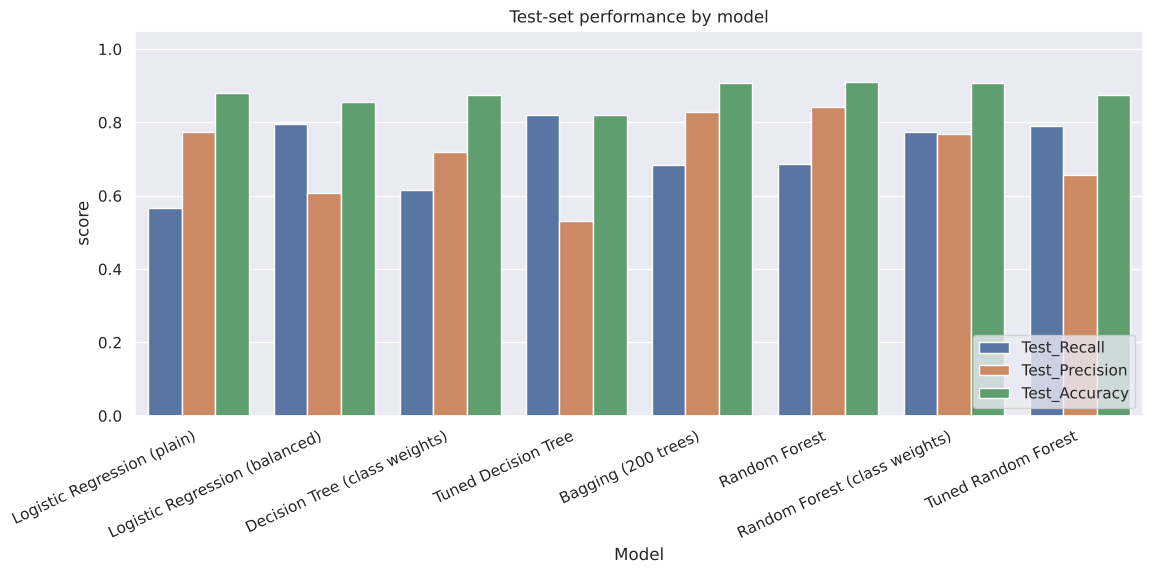

In [85]:
#@title
# Visual comparison on the test set
plot_df = comparison_frame.melt(id_vars='Model', value_vars=['Test_Recall', 'Test_Precision', 'Test_Accuracy'], var_name='metric', value_name='score')
plt.figure(figsize=(13, 5))
sns.barplot(data=plot_df, x='Model', y='score', hue='metric')
plt.xticks(rotation=25, ha='right'); plt.ylim(0, 1.05); plt.title('Test-set performance by model'); plt.legend(loc='lower right')
plt.show()

**Insights (comparison table):**
- Every un-pruned tree model (the single tree, bagging and the default and class-weighted forests) scores 100% on the training data. Only the test columns show differences between the models.
- On the test set at the 0.5 threshold, the tuned decision tree has the highest recall (82%) but the lowest precision (53%). The class-weighted Random Forest has the best balance (77% recall, 77% precision, 91% accuracy). The default, unweighted forest is the most precise (84%) and ranks applicants best (out-of-fold ROC-AUC 0.96 in the selection cell below). But it misses almost a third of defaulters at this threshold. The balanced logistic regression reaches 80% recall at 61% precision. We decide next which forest is best for the bank, on expected cost and training data only.

### **Choosing the final model and its decision threshold on training data only**

The comparison above uses the conventional 0.5 threshold. We never tested the class weights used so far (0.2/0.8 by convention, `balanced` from a recall-only grid search) against the business criterion. The bank's real question is which forest configuration, at its best threshold, gives the lowest expected cost of credit errors.

Class weights and the decision threshold are two dials for the same trade-off. So we choose them together, on that criterion, and **without touching the test set**. We score every candidate with **repeated 5-fold out-of-fold predictions on the training rows** (three different 5-fold splits, 15 validation folds). On those predictions we find the threshold that minimises the mean of the indicative expected cost. The indicative costs are about \$9,000 for a missed defaulter and about \$2,000 for a wrongly declined good applicant.

**Selection rule, fixed before the search:** the lowest mean expected cost on out-of-fold predictions wins. Among candidates within one fold-to-fold standard error of the lowest cost, we prefer the simplest (fewest non-default settings, then fewest inputs).

1. Stage 1 searches the class weights and the minimum leaf size on all 27 inputs. The number of trees and the features tried per split stay at their defaults. The standard error is the standard deviation of the 15 pooled fold costs divided by the square root of 15. The robustness checks include paired fold-by-fold checks of two close contests.
2. Stage 2 chooses the number of inputs for the winner, the counterpart of choosing how many principal components to keep. We remove the weakest input one at a time and score each smaller set with three forest seeds. The occupation columns and the loan-purpose columns leave together. The rule keeps the smallest input set whose mean cost is within one standard error of the lowest cost on this curve.
3. Stage 3 compares the winner on the selected input set with the same forest on all 27 inputs. It also scores the same forest on the selected set without any occupation information, the fallback that a fair-lending review might require. The recall-tuned grid winner also competes, on 27 and on 12 inputs. For completeness on the chosen yardstick, we score three more techniques the same way at their own cost-minimising thresholds. These are the bagged trees, the balanced logistic regression and the recall-tuned tree.

Only then do we refit the winner on all training rows and score it once on the test set.

In [86]:
#@title
from sklearn.model_selection import cross_val_predict
COST_FN, COST_FP = 9000, 2000
THRESHOLDS = np.round(np.arange(0.05, 0.71, 0.05), 2)
CV_REPEATS = [1, 2, 3]            # three different stratified 5-fold splits = 15 validation folds per candidate
COST_COL = 'Mean OOF expected cost per 1,000 ($)'

def cost_table(y_true, proba, thresholds=THRESHOLDS):
    rows = []
    for t in thresholds:
        pred = (proba > t).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel(); n = len(y_true)
        rows.append({'threshold': float(t), 'recall': tp / (tp + fn), 'precision': tp / (tp + fp) if tp + fp else 0.0, 'accuracy': (tp + tn) / n,
                     'missed_defaulters_per_1000': 1000 * fn / n, 'good_customers_declined_per_1000': 1000 * fp / n,
                     'expected_cost_per_1000_$': 1000 * (fn * COST_FN + fp * COST_FP) / n})
    return pd.DataFrame(rows)

def oof_evaluate(model, cols, X=None):
    # repeated 5-fold out-of-fold evaluation on the training rows: mean threshold table, best row, mean AUC, fold-to-fold SD of the cost
    # (X defaults to the tree data X_train; the logistic regression passes its own capped and scaled frame)
    X = X_train if X is None else X
    probas, tables, fold_costs = [], [], {}
    for seed in CV_REPEATS:
        cv_rep = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
        p = cross_val_predict(model, X[cols], y_train, cv=cv_rep, method='predict_proba')[:, 1]
        probas.append(p); tables.append(cost_table(y_train, p))
        for _, val in cv_rep.split(X[cols], y_train):
            fold_tbl = cost_table(y_train.iloc[val], p[val])
            for t, c in zip(fold_tbl['threshold'], fold_tbl['expected_cost_per_1000_$']):
                fold_costs.setdefault(t, []).append(c)
    tbl = pd.concat(tables).groupby('threshold', as_index=False).mean()
    best = tbl.loc[tbl['expected_cost_per_1000_$'].idxmin()]
    return {'probas': probas, 'table': tbl, 'best': best, 'auc': np.mean([metrics.roc_auc_score(y_train, p) for p in probas]),
            'fold_sd': np.std(fold_costs[best['threshold']], ddof=1), 'fold_costs': fold_costs}

def summary_row(res):
    return {'Mean OOF ROC-AUC': res['auc'], 'Best threshold': res['best']['threshold'], 'OOF recall at best': res['best']['recall'],
            'OOF precision at best': res['best']['precision'], COST_COL: res['best']['expected_cost_per_1000_$'], 'Fold-to-fold SD of cost ($)': res['fold_sd']}

SELECTION_FORMAT = {'Mean OOF ROC-AUC': '{:.3f}', 'Best threshold': '{:.2f}', 'OOF recall at best': '{:.3f}', 'OOF precision at best': '{:.3f}',
                    COST_COL: '{:,.0f}', 'Fold-to-fold SD of cost ($)': '{:,.0f}'}

# Stage 1: class weights x minimum leaf size (200 trees, all 27 inputs)
weight_options = {'none': None, 'balanced': 'balanced', '0.3/0.7': {0: 0.3, 1: 0.7}, '0.2/0.8': {0: 0.2, 1: 0.8}, '0.1/0.9': {0: 0.1, 1: 0.9}}
stage1 = {}
for w_name, w in weight_options.items():
    for leaf in [1, 5, 10]:       # 1 = fully grown trees (default); 5 and 10 = the constrained settings in the recall-only grid (10 was its choice)
        stage1[(w_name, leaf)] = oof_evaluate(RandomForestClassifier(n_estimators=200, class_weight=w, min_samples_leaf=leaf, random_state=1, n_jobs=-1), list(X_train.columns))
config_search = pd.DataFrame({k: summary_row(v) for k, v in stage1.items()}).T
config_search.index.names = ['Class weights', 'Min. applicants per leaf']

# the pre-stated rule: lowest mean cost; among configurations within one standard error of it, the simplest
lowest = config_search[COST_COL].min()
one_se = config_search.loc[config_search[COST_COL].idxmin(), 'Fold-to-fold SD of cost ($)'] / np.sqrt(5 * len(CV_REPEATS))
within = config_search[config_search[COST_COL] <= lowest + one_se].copy()
within['non-default settings'] = [(w != 'none') + (leaf != 1) for w, leaf in within.index]
best_weights, best_leaf = within.sort_values(['non-default settings', COST_COL]).index[0]
best_leaf = int(best_leaf)
print(f'Lowest mean OOF cost ${lowest:,.0f}; one standard error ${one_se:,.0f}; within one SE: {list(within.index)}')
print(f'Stage 1 choice: class weights = {best_weights}, min. applicants per leaf = {best_leaf}')
config_search.style.format(SELECTION_FORMAT).highlight_min(subset=[COST_COL], color='#c6efce')

Lowest mean OOF cost $317,354; one standard error $10,502; within one SE: [('none', 1), ('0.3/0.7', 1), ('0.2/0.8', 1)]
Stage 1 choice: class weights = none, min. applicants per leaf = 1


**Observations - configuration search:** fully grown trees beat constrained trees by a wide margin for every class-weight setting. A minimum leaf of 1 costs about \$317,000-345,000 per 1,000 applicants. A leaf of 5 costs roughly \$430,000-460,000 per 1,000 applicants, and the leaf of 10 that the recall-only grid search chose costs \$477,000-503,000. Constraining the leaves makes the probabilities cruder, which costs dearly once the threshold is free to move.

Among the fully grown forests the class weights barely matter. No weights (\$317,000), 0.3/0.7 (\$320,000) and 0.2/0.8 (\$321,000) are within one standard error (about \$10,500) of each other. They simply reach their minimum at different thresholds (0.15, 0.20, 0.25). The extreme 0.1/0.9 weighting is clearly worse, and `balanced` is somewhat worse (just outside one standard error).

By the pre-stated rule the unweighted forest is the Stage 1 choice: it has the lowest mean cost and the simplest configuration. Its score also keeps a natural reading as an estimated default rate (we check this below with a calibration table).

### **Stage 2: how many inputs does the forest need?**

A model with fewer inputs is easier to explain and to monitor. So we check how far we can cut the input set before the cost rises. This is the same question as choosing how many principal components to keep. We answer it the same way, with a curve of the expected cost against the number of inputs.

- We rank the inputs by the chosen forest's impurity importance (mean of three seeds) and remove the weakest first. The occupation columns and the loan-purpose columns leave as one group each, so the model never keeps only part of a category.
- We score every set on the same repeated 5-fold splits, with three forest seeds. A single forest's own randomness moves the cost by about as much as one standard error.
- The rule keeps the smallest input set whose seed-averaged cost is within one standard error of the lowest cost on the curve.

In [87]:
#@title
# Stage 2: input-set reduction for the chosen configuration (the counterpart of choosing how many principal components to keep)
FOREST_SEEDS = [1, 2, 3]         # a single forest's randomness moves the cost by about one standard error, so we average three seeds
SMALLEST_SET = 10                # stop at 10 inputs: the cost rises steeply well before that point

def chosen_forest(seed=1):
    return RandomForestClassifier(n_estimators=200, class_weight=weight_options[best_weights], min_samples_leaf=best_leaf, random_state=seed, n_jobs=-1)

# the occupation columns and the loan-purpose columns leave together, so that no category is half removed
input_units = {'occupation (JOB flag and five JOB indicators)': [c for c in X_train.columns if c.startswith('JOB_')],
               'loan purpose (REASON flag and REASON_HomeImp)': [c for c in X_train.columns if c.startswith('REASON_')]}
input_units.update({c: [c] for c in X_train.columns if not c.startswith(('JOB_', 'REASON_'))})
seed_importance = pd.Series(np.mean([chosen_forest(s).fit(X_train, y_train).feature_importances_ for s in FOREST_SEEDS], axis=0), index=X_train.columns)
unit_importance = pd.Series({u: seed_importance[cols].sum() for u, cols in input_units.items()}).sort_values()

stage2_runs = {}                 # (inputs, seed) -> out-of-fold result, reused in stage 3
def seed_averaged_cost(cols):
    runs = []
    for s in FOREST_SEEDS:
        key = (tuple(cols), s)
        if len(cols) == X_train.shape[1] and s == 1:
            stage2_runs[key] = stage1[(best_weights, best_leaf)]      # the same model on the same splits as in stage 1
        elif key not in stage2_runs:
            stage2_runs[key] = oof_evaluate(chosen_forest(s), cols)
        runs.append(stage2_runs[key])
    tbl = pd.concat([r['table'] for r in runs]).groupby('threshold', as_index=False).mean()
    best = tbl.loc[tbl['expected_cost_per_1000_$'].idxmin()]; t = best['threshold']
    return {COST_COL: best['expected_cost_per_1000_$'], 'Best threshold': t,
            'Cost with seed 1 / 2 / 3 ($)': ' / '.join(f"{r['table'].set_index('threshold').loc[t, 'expected_cost_per_1000_$']:,.0f}" for r in runs),
            'Fold-to-fold SD of cost ($)': np.mean([np.std(r['fold_costs'][t], ddof=1) for r in runs])}

rows, input_sets, cols = [], {}, list(X_train.columns)
for unit in [None] + list(unit_importance.index):          # remove the weakest input first
    if unit is not None:
        cols = [c for c in cols if c not in input_units[unit]]
    if len(cols) < SMALLEST_SET:
        break
    input_sets[len(cols)] = cols
    rows.append({'Inputs': len(cols), 'Removed in this step': unit or '(none: all inputs)',
                 'Importance of the removed input': unit_importance[unit] if unit else np.nan, **seed_averaged_cost(cols)})
reduction = pd.DataFrame(rows).set_index('Inputs')

# the rule: the smallest input set whose seed-averaged cost is within one standard error of the lowest cost on the curve
lowest_red = reduction[COST_COL].min()
one_se_red = reduction.loc[reduction[COST_COL].idxmin(), 'Fold-to-fold SD of cost ($)'] / np.sqrt(5 * len(CV_REPEATS))
selected_size = int(reduction[reduction[COST_COL] <= lowest_red + one_se_red].index.min())
selected_inputs = input_sets[selected_size]
removed_inputs = [c for c in X_train.columns if c not in selected_inputs]
print(f'Lowest seed-averaged cost ${lowest_red:,.0f} per 1,000 applicants ({reduction[COST_COL].idxmin()} inputs); one standard error ${one_se_red:,.0f}')
print(f'Selected input set: {selected_size} inputs at ${reduction.loc[selected_size, COST_COL]:,.0f}')
print(f'Removed ({len(removed_inputs)}):', removed_inputs)
print(f'Kept ({selected_size}):', selected_inputs)
(reduction.style.format({COST_COL: '{:,.0f}', 'Best threshold': '{:.2f}', 'Fold-to-fold SD of cost ($)': '{:,.0f}', 'Importance of the removed input': '{:.3f}'}, na_rep='')
          .apply(lambda r: ['background-color: #c6efce' if r.name == selected_size else '' for _ in r], axis=1))

Lowest seed-averaged cost $317,700 per 1,000 applicants (24 inputs); one standard error $9,731
Selected input set: 22 inputs at $321,242
Removed (5): ['MORTDUE_missing_values_flag', 'DELINQ_missing_values_flag', 'CLAGE_missing_values_flag', 'NINQ_missing_values_flag', 'CLNO_missing_values_flag']
Kept (22): ['LOAN', 'MORTDUE', 'VALUE', 'YOJ', 'DEROG', 'DELINQ', 'CLAGE', 'NINQ', 'CLNO', 'DEBTINC', 'VALUE_missing_values_flag', 'REASON_missing_values_flag', 'JOB_missing_values_flag', 'YOJ_missing_values_flag', 'DEROG_missing_values_flag', 'DEBTINC_missing_values_flag', 'REASON_HomeImp', 'JOB_Office', 'JOB_Other', 'JOB_ProfExe', 'JOB_Sales', 'JOB_Self']


,Removed in this step,Importance of the removed input,"Mean OOF expected cost per 1,000 ($)",Best threshold,Cost with seed 1 / 2 / 3 ($),Fold-to-fold SD of cost ($)
Inputs,,,,,,
27,(none: all inputs),,"320,150",0.15,"317,354 / 318,233 / 324,864","37,060"
26,CLNO_missing_values_flag,0.003,"320,230",0.15,"317,673 / 326,063 / 316,954","35,930"
25,NINQ_missing_values_flag,0.004,"325,024",0.15,"325,823 / 326,862 / 322,387","37,919"
24,DELINQ_missing_values_flag,0.004,"317,700",0.15,"312,480 / 316,715 / 323,905","37,689"
23,CLAGE_missing_values_flag,0.005,"320,177",0.15,"321,828 / 317,354 / 321,349","37,253"
22,MORTDUE_missing_values_flag,0.005,"321,242",0.15,"324,145 / 319,032 / 320,550","38,644"
21,YOJ_missing_values_flag,0.006,"328,753",0.15,"327,341 / 329,498 / 329,418","38,459"
20,DEROG_missing_values_flag,0.007,"333,520",0.15,"338,047 / 333,653 / 328,859","36,733"
18,loan purpose (REASON flag and REASON_HomeImp),0.016,"344,013",0.15,"341,323 / 352,029 / 338,686","36,346"


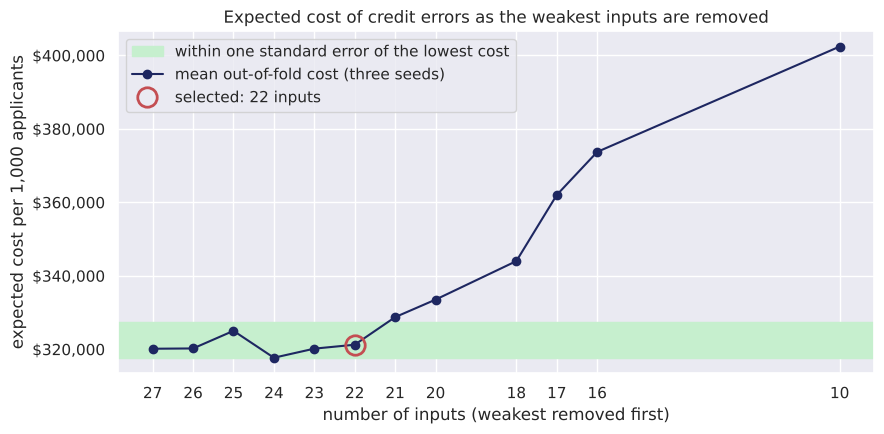

In [88]:
#@title
# Cost against the number of inputs (the counterpart of a scree plot), with the one-standard-error band of the rule
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.axhspan(lowest_red, lowest_red + one_se_red, color='#c6efce', label='within one standard error of the lowest cost')
ax.plot(reduction.index, reduction[COST_COL], marker='o', color='#1E2761', label='mean out-of-fold cost (three seeds)')
ax.plot(selected_size, reduction.loc[selected_size, COST_COL], marker='o', markersize=14, markerfacecolor='none',
        markeredgecolor='#C44E52', markeredgewidth=2, linestyle='none', label=f'selected: {selected_size} inputs')
ax.invert_xaxis(); ax.set_xticks(reduction.index)
ax.yaxis.set_major_formatter(lambda x, _: f'${x:,.0f}')
ax.set_xlabel('number of inputs (weakest removed first)'); ax.set_ylabel('expected cost per 1,000 applicants')
ax.set_title('Expected cost of credit errors as the weakest inputs are removed')
ax.legend(loc='upper left')
plt.tight_layout(); plt.show()

**Observations - input-set reduction:** the curve is flat from 27 down to 22 inputs. The first five inputs removed are the missing flags of CLNO, NINQ, DELINQ, CLAGE and MORTDUE. They carry almost no weight, together about 2% of the split power. Without them the cost stays between \$317,700 and \$325,000 per 1,000 applicants, against \$320,150 for all 27 inputs. With fewer than 22 inputs, the cost rises steadily: about \$328,800 for 21 inputs, \$333,500 for 20, \$373,700 for 16 and \$402,400 for 10.

By the rule we keep **22 inputs**. These are the 10 financial attributes, six missing flags (VALUE, REASON, JOB, YOJ, DEROG and DEBTINC) and the six one-hot indicators. One seed alone would mislead: with seed 1 only, the 25-input set costs about \$13,000 more than the 24-input set. We ranked the inputs on all training rows before the repeated cross-validation, which can slightly favour the reduced sets. The removed flags carry almost no weight, so the effect is small.

In [89]:
#@title
# Stage 3: the chosen configuration on the selected input set, on all 27 inputs and without any occupation information (the fair-lending fallback),
# against the recall-tuned grid winner on all 27 inputs and on the 12 most important features of the tuned forest
keep = pd.Series(rf_estimator_tuned.feature_importances_, index=X_train.columns).sort_values(ascending=False)
keep = keep[keep > 0.01].index.tolist()

no_occupation = [c for c in selected_inputs if not c.startswith('JOB_')]   # fair-lending fallback: the selected set without occupation
forest_name = f'RF class weights {best_weights}, leaf {best_leaf}'
candidates = {
    f'{forest_name}, {len(selected_inputs)} inputs (selected set)': (chosen_forest(), selected_inputs),
    f'{forest_name}, 27 inputs': (chosen_forest(), list(X_train.columns)),
    f'{forest_name}, {len(no_occupation)} inputs (selected set without occupation)': (chosen_forest(), no_occupation),
    'RF recall-tuned grid winner, 27 inputs': (RandomForestClassifier(**grid_obj.best_params_, random_state=1, n_jobs=-1), list(X_train.columns)),
    'RF recall-tuned grid winner, 12 inputs': (RandomForestClassifier(**grid_obj.best_params_, random_state=1, n_jobs=-1), keep),
}
# the other techniques at their own cost-minimising thresholds, so the comparison on the chosen yardstick is complete
from sklearn.base import clone
other_techniques = {'Bagging (200 trees), own threshold': (clone(bagging), list(X_train.columns), X_train),
                    'Logistic Regression (balanced), own threshold': (clone(lg_bal), list(X_train_lr.columns), X_train_lr),
                    'Decision Tree (recall-tuned), own threshold': (clone(dtree_estimator), list(X_train.columns), X_train)}
oof = {}
for name, (model, cols) in candidates.items():
    reuse = (tuple(cols), 1)     # the chosen forest with seed 1 on a set that stage 2 already scored on the same splits
    oof[name] = stage2_runs[reuse] if name.startswith(forest_name) and reuse in stage2_runs else oof_evaluate(model, cols)
for name, (model, cols, frame) in other_techniques.items():
    oof[name] = oof_evaluate(model, cols, X=frame)
selection = pd.DataFrame({name: summary_row(res) for name, res in oof.items()}).T
selection.index.name = 'Candidate'
selection['Inputs'] = [len(cols) for _, cols in candidates.values()] + [len(c[1]) for c in other_techniques.values()]
lowest = selection[COST_COL].min()
one_se = selection.loc[selection[COST_COL].idxmin(), 'Fold-to-fold SD of cost ($)'] / np.sqrt(5 * len(CV_REPEATS))
within = selection[selection[COST_COL] <= lowest + one_se]
winner = within.sort_values(['Inputs', COST_COL]).index[0]       # simplest (fewest inputs) among those within one standard error
FINAL_THRESHOLD = float(selection.loc[winner, 'Best threshold'])
assert winner in candidates, "the cells that follow score the winner on the untreated tree data"
print(f'Within one standard error (${one_se:,.0f}) of the lowest cost: {list(within.index)}')
print('Selected model:', winner, '| selected threshold:', FINAL_THRESHOLD)
selection.style.format(SELECTION_FORMAT).highlight_min(subset=[COST_COL], color='#c6efce')

Within one standard error ($10,502) of the lowest cost: ['RF class weights none, leaf 1, 22 inputs (selected set)', 'RF class weights none, leaf 1, 27 inputs']
Selected model: RF class weights none, leaf 1, 22 inputs (selected set) | selected threshold: 0.15


,Mean OOF ROC-AUC,Best threshold,OOF recall at best,OOF precision at best,"Mean OOF expected cost per 1,000 ($)",Fold-to-fold SD of cost ($),Inputs
Candidate,,,,,,,
"RF class weights none, leaf 1, 22 inputs (selected set)",0.960,0.15,0.937,0.639,"324,145","42,440",22
"RF class weights none, leaf 1, 27 inputs",0.961,0.15,0.937,0.647,"317,354","40,675",27
"RF class weights none, leaf 1, 16 inputs (selected set without occupation)",0.951,0.15,0.917,0.629,"364,813","32,700",16
"RF recall-tuned grid winner, 27 inputs",0.927,0.35,0.897,0.540,"489,613","52,035",27
"RF recall-tuned grid winner, 12 inputs",0.921,0.35,0.883,0.537,"512,544","47,688",12
"Bagging (200 trees), own threshold",0.944,0.15,0.901,0.629,"389,821","53,643",27
"Logistic Regression (balanced), own threshold",0.907,0.50,0.815,0.599,"550,176","58,089",27
"Decision Tree (recall-tuned), own threshold",0.880,0.55,0.800,0.563,"607,223","73,679",27


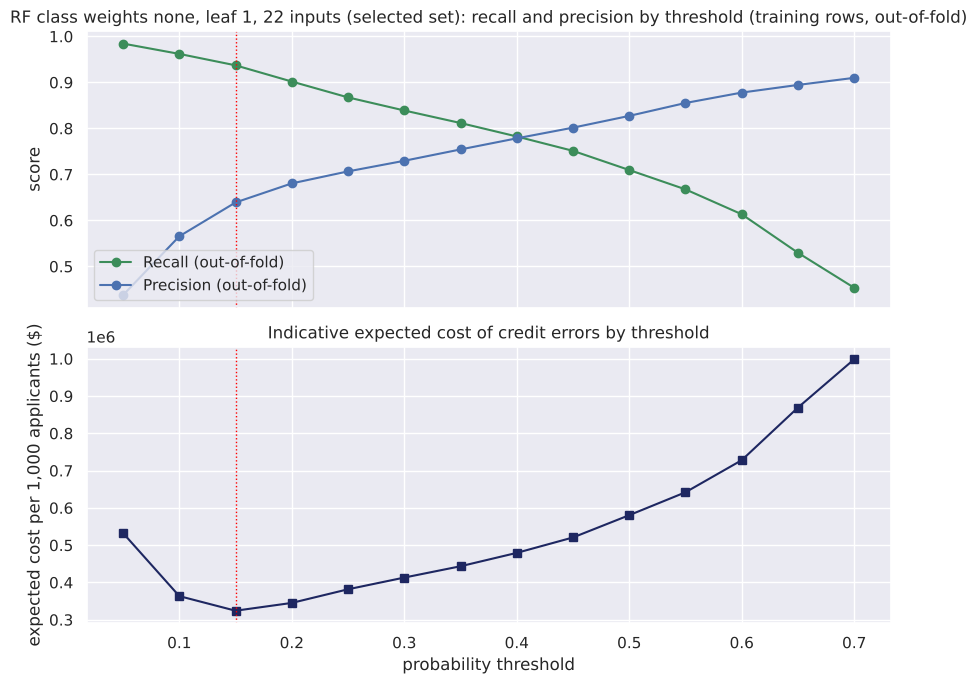

,cost of a missed defaulter / cost of a wrongly declined customer,cost-minimising threshold,break-even threshold for a perfectly calibrated score
0,2:1,0.20,0.33
1,3:1,0.20,0.25
2,4.5:1,0.15,0.18
3,6:1,0.15,0.14
4,7:1,0.15,0.12
5,8:1,0.15,0.11
6,9:1,0.10,0.10


,threshold,recall,precision,accuracy,missed_defaulters_per_1000,good_customers_declined_per_1000,expected_cost_per_1000_$
0,0.05,0.984,0.438,0.745,3.116,252.157,532358.581
1,0.10,0.962,0.566,0.845,7.590,147.491,363294.982
2,0.15,0.937,0.639,0.882,12.544,105.625,324145.094
3,0.20,0.902,0.680,0.896,19.575,84.452,345078.300
4,0.25,0.867,0.707,0.902,26.446,71.828,381671.461
5,0.30,0.839,0.730,0.906,32.119,62.001,413071.269
6,0.35,0.812,0.754,0.910,37.552,52.733,443432.407
7,0.40,0.782,0.778,0.912,43.384,44.423,479306.488
8,0.45,0.751,0.802,0.913,49.616,37.073,520693.512
9,0.50,0.710,0.827,0.913,57.926,29.562,580457.015


In [90]:
#@title
# Out-of-fold cost curve of the winner (mean over the three repeated 5-fold splits) and the sensitivity of the threshold to the cost ratio
# two panels that share the threshold axis, one y-axis each (no dual-axis chart)
tbl = oof[winner]['table']
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 7), sharex=True)
ax1.plot(tbl['threshold'], tbl['recall'], marker='o', color='#3C8D5A', label='Recall (out-of-fold)')
ax1.plot(tbl['threshold'], tbl['precision'], marker='o', color='#4C72B0', label='Precision (out-of-fold)')
ax1.set_ylabel('score'); ax1.legend(loc='lower left')
ax1.set_title(f'{winner}: recall and precision by threshold (training rows, out-of-fold)')
ax2.plot(tbl['threshold'], tbl['expected_cost_per_1000_$'], marker='s', color='#1E2761')
ax2.set_ylabel('expected cost per 1,000 applicants ($)'); ax2.set_xlabel('probability threshold')
ax2.set_title('Indicative expected cost of credit errors by threshold')
for ax in (ax1, ax2):
    ax.axvline(FINAL_THRESHOLD, color='red', linestyle=':', linewidth=1)
plt.tight_layout(); plt.show()

rows = []
for ratio in [2, 3, 4.5, 6, 7, 8, 9]:
    costs = [sum(confusion_matrix(y_train, (p > t).astype(int)).ravel()[2] * ratio + confusion_matrix(y_train, (p > t).astype(int)).ravel()[1] for p in oof[winner]['probas']) for t in THRESHOLDS]
    rows.append({'cost of a missed defaulter / cost of a wrongly declined customer': f'{ratio}:1', 'cost-minimising threshold': THRESHOLDS[int(np.argmin(costs))],
                 'break-even threshold for a perfectly calibrated score': round(1 / (1 + ratio), 2)})
display(pd.DataFrame(rows))
tbl.round(3)

In [91]:
#@title
# Five robustness checks on the selection, all on training rows only
# (a) a finer threshold grid for the winner
fine = np.round(np.arange(0.08, 0.26, 0.01), 2)
fine_cost = np.mean([cost_table(y_train, p, thresholds=fine)['expected_cost_per_1000_$'].values for p in oof[winner]['probas']], axis=0)
print(f'(a) Finer grid, 0.01 steps: cost-minimising threshold {fine[int(np.argmin(fine_cost))]:.2f}; mean OOF cost per 1,000 ($) by threshold:')
print(pd.Series(fine_cost.round(0).astype(int), index=fine).to_frame('cost').T.to_string())

# (b) calibration of the out-of-fold scores: reliability table and Brier score, winner vs the class-weighted forest it replaced
score_bins = [0, 0.05, 0.10, 0.15, 0.20, 0.30, 0.40, 0.50, 0.70, 1.0]
def reliability(proba, label):
    t = (pd.DataFrame({'score band': pd.cut(proba, score_bins, include_lowest=True), 'p': proba, 'y': y_train.values})
           .groupby('score band', observed=True).agg(applicants=('y', 'size'), mean_score=('p', 'mean'), observed_default_rate=('y', 'mean')))
    t.columns = pd.MultiIndex.from_product([[label], t.columns]); return t
p_final, p_weighted = oof[winner]['probas'][0], stage1[('0.2/0.8', 1)]['probas'][0]
print(f'(b) Brier score (lower is better; the base rate alone scores {metrics.brier_score_loss(y_train, np.full(len(y_train), y_train.mean())):.3f}): '
      f'final forest {metrics.brier_score_loss(y_train, p_final):.3f}, class weights 0.2/0.8 {metrics.brier_score_loss(y_train, p_weighted):.3f}')
display(pd.concat([reliability(p_final, 'Final forest (unweighted)'), reliability(p_weighted, 'Class weights 0.2/0.8')], axis=1).round(3))

# (c) the approve / refer / decline bands proposed later (0.10 and 0.25), on the out-of-fold scores of the training rows
oof_bands = pd.cut(p_final, [-0.01, 0.10, 0.25, 1.0], labels=['approve (score <= 0.10)', 'refer (0.10 - 0.25)', 'decline (score > 0.25)'])
band_oof = (pd.DataFrame({'band': oof_bands, 'defaulted': y_train.values}).groupby('band', observed=True)
              .agg(applicants=('defaulted', 'size'), defaulters=('defaulted', 'sum'), observed_default_rate=('defaulted', 'mean')))
band_oof['share_of_applicants'] = band_oof['applicants'] / len(y_train); band_oof['share_of_defaulters'] = band_oof['defaulters'] / y_train.sum()
print('(c) Approve / refer / decline bands on the out-of-fold scores (training rows):'); display(band_oof.round(3))

# (d) paired checks of the 'within noise' statements over the same 15 folds: the 0.2/0.8 forest against the unweighted forest (both on 27 inputs),
#     and the winner against the unweighted forest on all 27 inputs
def fold_costs_at(res, t):
    out = []
    for seed, p in zip(CV_REPEATS, res['probas']):
        for _, val in StratifiedKFold(n_splits=5, shuffle=True, random_state=seed).split(X_train, y_train):
            out.append(cost_table(y_train.iloc[val], p[val], thresholds=np.array([t]))['expected_cost_per_1000_$'].iloc[0])
    return np.array(out)
weighted, all_inputs = stage1[('0.2/0.8', 1)], stage1[(best_weights, best_leaf)]
for label, a, b in [('class weights 0.2/0.8 minus no class weights, both on 27 inputs', weighted, all_inputs),
                    (f'the selected {len(candidates[winner][1])} inputs (the winner) minus all 27 inputs', oof[winner], all_inputs)]:
    diff = fold_costs_at(a, a['best']['threshold']) - fold_costs_at(b, b['best']['threshold'])
    print(f"(d) Paired fold-by-fold difference, {label}, each at its own best threshold ({a['best']['threshold']:.2f} and {b['best']['threshold']:.2f}): "
          f"mean ${diff.mean():,.0f} per 1,000, paired standard error ${diff.std(ddof=1) / np.sqrt(len(diff)):,.0f} ({len(diff)} folds)")

# (e) does the choice depend on this particular 70/30 split? Repeat stage 1 (fully grown trees) on two other stratified splits,
#     rebuilding the missing flags and the imputation from each split's own training rows
def training_rows_for_split(seed):
    frame = hm.copy()
    for c in ['REASON', 'JOB', 'BAD']:
        frame[c] = frame[c].astype('category')
    tr, _ = train_test_split(frame.index, test_size=0.3, random_state=seed, stratify=frame['BAD'])
    for col in [c for c in frame.columns if frame[c].isnull().any()]:
        frame[col + '_missing_values_flag'] = frame[col].isnull().astype(int)
    num = frame.select_dtypes('number').columns
    frame[num] = frame[num].fillna(frame.loc[tr, num].median())
    for c in ['REASON', 'JOB']:
        frame[c] = frame[c].fillna(frame.loc[tr, c].mode()[0])
    Xs = pd.get_dummies(frame.drop(['BAD'], axis=1), columns=['REASON', 'JOB'], drop_first=True, dtype=int)
    return Xs.loc[tr], frame.loc[tr, 'BAD'].astype(int)
rows = []
for seed in [2, 3]:
    Xs, ys = training_rows_for_split(seed)
    cv_s = StratifiedKFold(n_splits=5, shuffle=True, random_state=1)
    for w_name, w in weight_options.items():
        p = cross_val_predict(RandomForestClassifier(n_estimators=200, class_weight=w, random_state=1, n_jobs=-1), Xs, ys, cv=cv_s, method='predict_proba')[:, 1]
        t = cost_table(ys, p); best = t.loc[t['expected_cost_per_1000_$'].idxmin()]
        rows.append({'class weights': w_name, 'split seed': seed, 'best threshold': best['threshold'], 'OOF cost per 1,000 ($)': best['expected_cost_per_1000_$']})
split_check = pd.DataFrame(rows).pivot(index='class weights', columns='split seed', values=['best threshold', 'OOF cost per 1,000 ($)']).loc[list(weight_options)]
print('(e) Stage 1 repeated on two other 70/30 splits (fully grown trees, single 5-fold OOF). Cheapest configuration per split:',
      {seed: split_check[('OOF cost per 1,000 ($)', seed)].idxmin() for seed in [2, 3]})
split_check.style.format({c: ('{:.2f}' if c[0] == 'best threshold' else '{:,.0f}') for c in split_check.columns})

(a) Finer grid, 0.01 steps: cost-minimising threshold 0.15; mean OOF cost per 1,000 ($) by threshold:
        0.08    0.09    0.10    0.11    0.12    0.13    0.14    0.15    0.16    0.17    0.18    0.19    0.20    0.21    0.22    0.23    0.24    0.25
cost  402125  377996  363295  348754  334452  329338  326782  324145  330058  333253  332614  339086  345078  354027  364573  368408  377437  381671
(b) Brier score (lower is better; the base rate alone scores 0.160): final forest 0.063, class weights 0.2/0.8 0.065


Final forest (unweighted)                                   \
                              applicants mean_score observed_default_rate   
score band                                                                  
(-0.001, 0.05]                      2299      0.018                 0.005   
(0.05, 0.1]                          457      0.073                 0.035   
(0.1, 0.15]                          198      0.125                 0.101   
(0.15, 0.2]                          116      0.174                 0.284   
(0.2, 0.3]                           146      0.249                 0.363   
(0.3, 0.4]                           125      0.353                 0.368   
(0.4, 0.5]                           113      0.456                 0.513   
(0.5, 0.7]                           301      0.608                 0.701   
(0.7, 1.0]                           417      0.815                 0.918   

               Class weights 0.2/0.8                                   
                          applicants mean_score observed_default_rate  
score band                                                             
(-0.001, 0.05]                  1665      0.023                 0.002  
(0.05, 0.1]                      654      0.074                 0.012  
(0.1, 0.15]                      324      0.124                 0.034  
(0.15, 0.2]                      210      0.175                 0.067  
(0.2, 0.3]                       211      0.246                 0.209  
(0.3, 0.4]                       122      0.349                 0.377  
(0.4, 0.5]                       107      0.455                 0.355  
(0.5, 0.7]                       266      0.603                 0.560  
(0.7, 1.0]                       613      0.841                 0.845

(c) Approve / refer / decline bands on the out-of-fold scores (training rows):


,applicants,defaulters,observed_default_rate,share_of_applicants,share_of_defaulters
band,,,,,
approve (score <= 0.10),2756,28,0.010,0.661,0.034
refer (0.10 - 0.25),395,78,0.197,0.095,0.094
decline (score > 0.25),1021,726,0.711,0.245,0.873


(d) Paired fold-by-fold difference, class weights 0.2/0.8 minus no class weights, both on 27 inputs, each at its own best threshold (0.25 and 0.15): mean $3,836 per 1,000, paired standard error $5,122 (15 folds)


(d) Paired fold-by-fold difference, the selected 22 inputs (the winner) minus all 27 inputs, each at its own best threshold (0.15 and 0.15): mean $6,792 per 1,000, paired standard error $6,276 (15 folds)


(e) Stage 1 repeated on two other 70/30 splits (fully grown trees, single 5-fold OOF). Cheapest configuration per split: {2: 'none', 3: 'none'}


**Observations - model, threshold and robustness:** the unweighted forest on all 27 inputs has the lowest single-seed out-of-fold cost (about \$317,000 per 1,000 applicants). The same forest on the 22 selected inputs costs about \$324,000, within one standard error (about \$10,500). So the rule picks the simpler 22-input forest, and Stage 3 keeps the input-set reduction. A paired fold-by-fold check agrees: the 22-input forest costs \$6,792 more per 1,000 on average, with a paired standard error of \$6,276. The gap is about one paired standard error, so it is within noise. Averaged over three seeds, the two sets differ by only about \$1,100 (\$321,242 against \$320,150).

Removing all occupation information from the selected set leaves 16 inputs and costs about 13% more than the 22-input forest (\$365,000). This is outside one standard error, so occupation carries real signal. The recall-tuned grid winner costs about half again as much. We scored the bagged trees, the balanced logistic regression and the recall-tuned tree the same way, at their own best thresholds. They cost more than every fully grown forest in Stage 1 and Stage 3 (about \$390,000, \$550,000 and \$607,000). So the technique choice holds on the chosen yardstick too.

The cost-minimising threshold is 0.15 (the model flags every applicant whose score exceeds 0.15, an estimated default risk of roughly one in five). It stays at 0.15 for cost ratios from 4.5:1 to 8:1. The stated ratio of 4.5:1 is at the lower edge of that range. The threshold moves to 0.20 at 2:1 and 3:1, and to 0.10 at 9:1. A finer 0.01 grid gives the same threshold. A second paired fold-by-fold check compares the 0.2/0.8 forest with the unweighted forest, both on 27 inputs. The mean difference is \$3,836 per 1,000, with a paired standard error of \$5,122, so the two are within noise. On two other 70/30 splits the unweighted forest is again the cheapest configuration, with the weighted forests within noise of it.

The calibration table shows why the optimum sits a little below the textbook break-even of 0.18 for a perfectly calibrated score. The forest's scores rank applicants well (Brier 0.063 against 0.160 for the base rate) but understate risk in the decision range. Applicants scored 0.15-0.20 defaulted about 28% of the time. The class-weighted forest errs in the other direction: applicants it scored 0.15-0.20 defaulted only 7% of the time. Read a score of 0.15 as "estimated default risk of roughly one in five", not exactly 15%.

In [92]:
#@title
# The final solution written out end to end, so that every step and every input to the scoring model is explicit
final_model, final_cols = candidates[winner]
flag_cols = [c for c in final_cols if c.endswith('_missing_values_flag')]
dummy_cols = [c for c in final_cols if c.startswith(('REASON_', 'JOB_')) and c not in flag_cols]
raw_cols = [c for c in final_cols if c not in flag_cols + dummy_cols]
assert len(final_cols) == len(raw_cols) + len(flag_cols) + len(dummy_cols) and final_cols == [c for c in X_train.columns if c in final_cols]
unused_flags = [c for c in X_train.columns if c.endswith('_missing_values_flag') and c not in final_cols]
print(f'FINAL PIPELINE (every statistic below was learned on the {len(train_idx):,} training rows only)')
print(f'1. Raw inputs kept as numbers ({len(raw_cols)}):', raw_cols)
print(f'2. Missing-value flags, 1 if the field was blank, kept as inputs ({len(flag_cols)}):', flag_cols)
print(f'   Flags removed by the input-set reduction ({len(unused_flags)}):', unused_flags)
print('3. Imputation of blanks - training-row medians:', {k: round(v, 2) for k, v in hm.loc[train_idx, num_cols].median().items()})
print('                          training-row modes  :', {c: hm.loc[train_idx, c].mode()[0] for c in ['REASON', 'JOB']})
print(f'4. One-hot encoding of REASON and JOB, first level dropped ({len(dummy_cols)}):', dummy_cols)
print('5. No outlier capping and no scaling: tree ensembles are unaffected by monotone transformations of an input')
print('6. Model:', type(final_model).__name__, {k: v for k, v in final_model.get_params().items() if k in ['n_estimators', 'class_weight', 'min_samples_leaf', 'max_features', 'max_depth', 'random_state']})
print(f'7. Model inputs, in order ({len(final_cols)}):', final_cols)
print(f'8. Decision rule: flag the applicant when the predicted default probability exceeds {FINAL_THRESHOLD:.2f} (break-even for a calibrated score at the stated costs: {COST_FP / (COST_FN + COST_FP):.2f})')
print(f'9. Input-set reduction (stage 2). Rule: keep the smallest input set whose mean out-of-fold cost over {len(FOREST_SEEDS)} forest seeds '
      f'is within one standard error (${one_se_red:,.0f}) of the lowest cost on the curve (${lowest_red:,.0f}).')
smaller = [n for n in reduction.index if n < selected_size]
print(f'   Selected: {selected_size} inputs at ${reduction.loc[selected_size, COST_COL]:,.0f} per 1,000 applicants; all 27 inputs: '
      f'${reduction.loc[27, COST_COL]:,.0f}' + (f'; next smaller set ({smaller[0]} inputs): ${reduction.loc[smaller[0], COST_COL]:,.0f}, '
      'outside one standard error' if smaller else ''))
print(f'   Removed ({len(removed_inputs)}):', removed_inputs)
print(f'   Stage 3 confirmed the selected set: {winner}')

FINAL PIPELINE (every statistic below was learned on the 4,172 training rows only)
1. Raw inputs kept as numbers (10): ['LOAN', 'MORTDUE', 'VALUE', 'YOJ', 'DEROG', 'DELINQ', 'CLAGE', 'NINQ', 'CLNO', 'DEBTINC']
2. Missing-value flags, 1 if the field was blank, kept as inputs (6): ['VALUE_missing_values_flag', 'REASON_missing_values_flag', 'JOB_missing_values_flag', 'YOJ_missing_values_flag', 'DEROG_missing_values_flag', 'DEBTINC_missing_values_flag']
   Flags removed by the input-set reduction (5): ['MORTDUE_missing_values_flag', 'DELINQ_missing_values_flag', 'CLAGE_missing_values_flag', 'NINQ_missing_values_flag', 'CLNO_missing_values_flag']
3. Imputation of blanks - training-row medians: {'LOAN': 16200.0, 'MORTDUE': 66293.0, 'VALUE': 89965.0, 'YOJ': 7.0, 'DEROG': 0.0, 'DELINQ': 0.0, 'CLAGE': 173.87, 'NINQ': 1.0, 'CLNO': 20.0, 'DEBTINC': 34.84}
                          training-row modes  : {'REASON': 'DebtCon', 'JOB': 'Other'}
4. One-hot encoding of REASON and JOB, first level droppe

Final model: RF class weights none, leaf 1, 22 inputs (selected set) at threshold 0.15 - TEST SET
              precision    recall  f1-score   support

           0      0.980     0.888     0.932      1431
           1      0.674     0.927     0.781       357

    accuracy                          0.896      1788
   macro avg      0.827     0.908     0.856      1788
weighted avg      0.919     0.896     0.902      1788



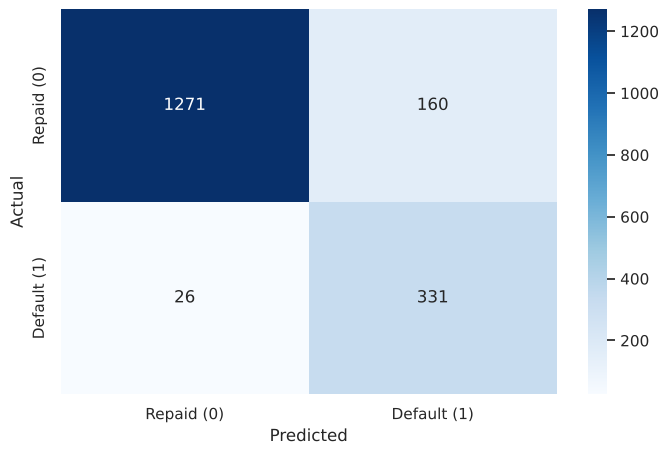

Test ROC-AUC: 0.961
Today's process on these applicants (all approved, every defaulter missed): expected cost $1,796,980 per 1,000; the final model at 0.15 cuts it by 82.8%
Test expected cost per 1,000 applicants: $309,843 (standard error about $28,385); out-of-fold estimate $324,145


,threshold,recall,precision,accuracy,missed_defaulters_per_1000,good_customers_declined_per_1000,expected_cost_per_1000_$
0,0.15,0.927,0.674,0.896,14.541,89.485,309843.400
1,0.50,0.678,0.829,0.908,64.318,27.964,634787.472


In [93]:
#@title
# Fit the winner on all training rows and score the test set once, at the selected threshold and at 0.5 for reference
final_model.fit(X_train[final_cols], y_train)
proba_test = final_model.predict_proba(X_test[final_cols])[:, 1]
final_pred = (proba_test > FINAL_THRESHOLD).astype(int)
print(f'Final model: {winner} at threshold {FINAL_THRESHOLD:.2f} - TEST SET')
metrics_score(y_test, final_pred)
print('Test ROC-AUC:', round(metrics.roc_auc_score(y_test, proba_test), 3))
cost_per_applicant = np.where((y_test == 1) & (final_pred == 0), COST_FN, np.where((y_test == 0) & (final_pred == 1), COST_FP, 0.0))
print(f"Today's process on these applicants (all approved, every defaulter missed): expected cost ${1000 * y_test.mean() * COST_FN:,.0f} per 1,000; the final model at {FINAL_THRESHOLD:.2f} cuts it by {1 - cost_per_applicant.mean() / (y_test.mean() * COST_FN):.1%}")
print(f"Test expected cost per 1,000 applicants: ${1000 * cost_per_applicant.mean():,.0f} (standard error about ${1000 * cost_per_applicant.std(ddof=1) / np.sqrt(len(y_test)):,.0f}); out-of-fold estimate ${oof[winner]['best']['expected_cost_per_1000_$']:,.0f}")
cost_table(y_test, proba_test, thresholds=np.array([FINAL_THRESHOLD, 0.5])).round(3)

In [94]:
#@title
# What the proposed three-band policy would mean in practice (test set): approve below a score of 0.10, refer 0.10 - 0.25 to an underwriter, decline above 0.25
bands = pd.cut(proba_test, [-0.01, 0.10, 0.25, 1.0], labels=['approve (score <= 0.10)', 'refer to underwriter (0.10 - 0.25)', 'decline (score > 0.25)'])
band_tbl = (pd.DataFrame({'band': bands, 'defaulted': y_test.values}).groupby('band', observed=True)
              .agg(applicants=('defaulted', 'size'), defaulters=('defaulted', 'sum'), observed_default_rate=('defaulted', 'mean')))
band_tbl['share_of_applicants'] = band_tbl['applicants'] / len(y_test)
band_tbl['share_of_defaulters'] = band_tbl['defaulters'] / y_test.sum()
band_tbl['per_1000_applicants'] = 1000 * band_tbl['share_of_applicants']
band_tbl.round(3)

,applicants,defaulters,observed_default_rate,share_of_applicants,share_of_defaulters,per_1000_applicants
band,,,,,,
approve (score <= 0.10),1228,16,0.013,0.687,0.045,686.801
refer to underwriter (0.10 - 0.25),132,28,0.212,0.074,0.078,73.826
decline (score > 0.25),428,313,0.731,0.239,0.877,239.374


In [95]:
#@title
# Where does the performance come from? The final model on the test applicants with a recorded debt-to-income ratio and on those without one
rows = []
for label, mask in [('ratio recorded', X_test['DEBTINC_missing_values_flag'] == 0), ('ratio missing', X_test['DEBTINC_missing_values_flag'] == 1)]:
    yt, pt, pp = y_test[mask], final_pred[mask.values], proba_test[mask.values]
    tn, fp, fn, tp = confusion_matrix(yt, pt).ravel()
    rows.append({'group': label, 'applicants': int(mask.sum()), 'share_of_applicants': mask.mean(), 'default_rate': yt.mean(), 'share_of_all_defaulters': yt.sum() / y_test.sum(),
                 'flagged': pt.mean(), 'recall': tp / (tp + fn), 'precision': tp / (tp + fp), 'ROC-AUC': metrics.roc_auc_score(yt, pp)})
pd.DataFrame(rows).set_index('group').round(3)

,applicants,share_of_applicants,default_rate,share_of_all_defaulters,flagged,recall,precision,ROC-AUC
group,,,,,,,,
ratio recorded,1415,0.791,0.087,0.345,0.090,0.813,0.781,0.965
ratio missing,373,0.209,0.627,0.655,0.973,0.987,0.636,0.814


In [96]:
#@title
# What the final model relies on: impurity importance of the fitted forest and permutation importance (drop in test ROC-AUC when a column is shuffled);
# the test set is used here for interpretation only, no choice is made from it
from sklearn.inspection import permutation_importance
mdi = pd.Series(final_model.feature_importances_, index=final_cols).sort_values(ascending=False)
perm = permutation_importance(final_model, X_test[final_cols], y_test, scoring='roc_auc', n_repeats=5, random_state=1, n_jobs=-1)
perm_imp = pd.Series(perm.importances_mean, index=final_cols).sort_values(ascending=False)
pd.DataFrame({'impurity_importance': mdi.round(3), 'permutation_importance_auc_drop': perm_imp.round(4)}).sort_values('impurity_importance', ascending=False).head(12)

,impurity_importance,permutation_importance_auc_drop
DEBTINC_missing_values_flag,0.172,0.0260
DEBTINC,0.144,0.0330
CLAGE,0.087,0.0305
DELINQ,0.080,0.0369
VALUE,0.075,0.0121
LOAN,0.072,0.0145
CLNO,0.068,0.0178
MORTDUE,0.067,0.0114
YOJ,0.053,0.0119
DEROG,0.047,0.0103


**Observations (final-model importances):** the debt-to-income ratio and its missing flag carry about a third of the final forest's split power (32%). Together with delinquent lines and credit-history length they carry about half (48%). Permutation importance ranks delinquent lines first, then the ratio, credit-history length and the ratio's missing flag. The 53% figure quoted earlier for the recall-tuned forest refers to that model, not to the final one.

In [97]:
#@title
# Explanation layer: a surrogate decision tree fitted to the forest's own decisions, and its agreement (fidelity) with the forest on the test applicants
# The surrogate is fitted to the forest's OUT-OF-FOLD decisions on the training rows: a fully grown forest reproduces its training labels
# almost perfectly, so its in-sample decisions would teach the surrogate the labels rather than the forest's behaviour on new applicants.
forest_decision_oof = (oof[winner]['probas'][0] > FINAL_THRESHOLD).astype(int)
forest_decision_insample = (final_model.predict_proba(X_train[final_cols])[:, 1] > FINAL_THRESHOLD).astype(int)
print(f'In-sample decisions agree with the training labels on {(forest_decision_insample == y_train.values).mean():.1%} of rows; '
      f'baseline: a rule that never flags anyone agrees with the forest test decisions {1 - final_pred.mean():.1%} of the time.')
for target_name, target in [('out-of-fold decisions', forest_decision_oof), ('in-sample decisions', forest_decision_insample)]:
    for depth in [3, 4, 5]:
        sur = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=20, random_state=1).fit(X_train[final_cols], target)
        pred = sur.predict(X_test[final_cols])
        print(f'  surrogate target {target_name:22s} depth {depth}: fidelity {(pred == final_pred).mean():.1%}, kappa {metrics.cohen_kappa_score(final_pred, pred):.2f}')
surrogate = DecisionTreeClassifier(max_depth=4, min_samples_leaf=20, random_state=1).fit(X_train[final_cols], forest_decision_oof)
fidelity = (surrogate.predict(X_test[final_cols]) == final_pred).mean()
print(f'\nThe depth-4 surrogate tree (fitted to the out-of-fold decisions) reproduces {fidelity:.1%} of the forest decisions on unseen applicants.\n')
print(export_text(surrogate, feature_names=final_cols, max_depth=4, show_weights=False))

In-sample decisions agree with the training labels on 96.1% of rows; baseline: a rule that never flags anyone agrees with the forest test decisions 72.5% of the time.
  surrogate target out-of-fold decisions  depth 3: fidelity 93.4%, kappa 0.83
  surrogate target out-of-fold decisions  depth 4: fidelity 93.2%, kappa 0.82
  surrogate target out-of-fold decisions  depth 5: fidelity 93.2%, kappa 0.82
  surrogate target in-sample decisions    depth 3: fidelity 89.1%, kappa 0.69
  surrogate target in-sample decisions    depth 4: fidelity 89.9%, kappa 0.72
  surrogate target in-sample decisions    depth 5: fidelity 90.8%, kappa 0.75

The depth-4 surrogate tree (fitted to the out-of-fold decisions) reproduces 93.2% of the forest decisions on unseen applicants.

|--- DEBTINC_missing_values_flag <= 0.50
|   |--- DEBTINC <= 43.72
|   |   |--- DELINQ <= 0.50
|   |   |   |--- VALUE <= 48580.50
|   |   |   |   |--- class: 0
|   |   |   |--- VALUE >  48580.50
|   |   |   |   |--- class: 0
|   |   |-

**Insights (model selection and final model):**
- The configuration search shows that, once we choose the threshold on cost, class weights add nothing. The unweighted forest, the 0.2/0.8 forest and the 0.3/0.7 forest are within one standard error of each other at their own best thresholds. The balanced and 0.1/0.9 weightings cost about \$13,000 and \$27,000 more per 1,000 applicants. Constrained trees (10 applicants per leaf, the recall-only grid choice) cost about half again as much.
- Stage 2 keeps 22 inputs: the 10 financial attributes, six missing flags (VALUE, REASON, JOB, YOJ, DEROG and DEBTINC) and the six one-hot indicators. It removes the missing flags of MORTDUE, DELINQ, CLAGE, NINQ and CLNO. The rule keeps the smallest input set within one standard error of the lowest cost on the seed-averaged curve.
- By the pre-stated rules we choose the **unweighted forest on these 22 inputs with a 0.15 threshold**. Its mean out-of-fold cost (about \$324,000 per 1,000 applicants) is within one standard error of the 27-input forest (about \$317,000). So Stage 3 keeps the 22-input forest rather than all 27 inputs. It is well ahead of the recall-tuned grid winner (\$490,000) and of the version without any occupation information (16 inputs, \$365,000, the fair-lending fallback).
- On the test set, scored once, it catches 93% of defaulters at 67% precision and 90% accuracy (ROC-AUC 0.96). Compared with the 0.5 threshold, missed defaulters fall from about 64 to 15 per 1,000 applicants. Wrongly flagged good applicants rise from about 28 to 90 per 1,000 applicants. The indicative expected cost halves (about \$0.31 million vs \$0.63 million per 1,000). The test cost (\$310,000 ± \$28,000 standard error per 1,000) is consistent with the out-of-fold estimate (\$324,000). One test evaluation is too noisy to adjudicate between the fully grown configurations, so that choice rests on the out-of-fold comparison.
- The 0.15 threshold sits just below the textbook break-even for a perfectly calibrated score (0.18). The reason is that the forest's scores understate risk in the decision range (applicants scored 0.15-0.20 defaulted about 28% of the time). The threshold held on a finer threshold grid. It also held for the unweighted 27-input forest on two other train/test splits.
- In practice the bank would approve about 69% of applicants automatically (about 1% default). It would refer about 7% to an underwriter (about 21% default) and decline about 24% (73% default, 88% of all defaulters). Overall the model flags about 27% of applicants, an approval rate of about 73% on a population the bank approves in full today. All quoted performance figures are for the single 0.15 threshold. Under the bands the share of defaulters caught lies between about 88% (every referral approved) and 96% (every referral declined).
- Two thirds of all defaulters sit in the fifth of applicants with no recorded debt-to-income ratio, a group the model flags almost entirely (97%). On applicants with a recorded ratio it flags 9% and catches 81% of their defaulters at 78% precision. Those figures are the better guide to its behaviour once income verification is mandatory.
- We fit the depth-4 surrogate tree to the forest's out-of-fold decisions. It reproduces about 93% of the forest's decisions on unseen applicants (73% for a rule that never flags anyone). So its three rules are a faithful plain-language summary of the scoring engine:
  1. the debt-to-income ratio is missing,
  2. the ratio is above about 44%,
  3. the ratio is at or below 44%, with a delinquent line and a credit history of about 93 months (7.8 years) or less.

**1. Comparison of various techniques and their relative performance based on chosen Metric (Measure of success):**
- How do different techniques perform? Which one is performing relatively better? Is there scope to improve the performance further?

*Measure of success.* Recall on the defaulter class is the primary metric because a missed defaulter costs the bank about 4.5 times a wrongly declined good applicant. Precision and F1 are the guard-rails. We report accuracy for completeness.

*Linear vs non-linear.* The balanced logistic regression reaches 80% recall but only 61% precision. The data is made of thresholds (debt-to-income above 45%, any delinquency), which trees capture and a straight line cannot. The linear model remains the most transparent benchmark.

*Single tree vs bagging vs forest.* The tuned decision tree catches the most defaulters at the 0.5 threshold (82%). But it declines almost one good applicant for every defaulter it catches (53% precision). Bagging 200 trees shows the value of averaging. Against the single fully grown (class-weighted) tree, precision rises from 72% to 83% and recall from 62% to 68%.

The class-weighted Random Forest adds feature sub-sampling and class weights. It reaches 77% recall at 77% precision, the best balance at 0.5. The recall-tuned forest reaches 79% recall with lower precision (66%). Once we include the cost of lower precision, it has a clearly higher expected cost. The out-of-fold cost search above decides which forest is best for the bank, not this table.

*Pros and cons.* Logistic regression is fully transparent and trivial to run, but it under-fits threshold effects on the raw inputs. A decision tree gives a readable rule list, but it is unstable between re-trainings and has the lowest precision. Bagging and Random Forest have the best test-set performance and are the most stable. We explain them through feature importances, a surrogate tree and per-applicant risk drivers rather than a rule list. They need model-risk documentation and drift monitoring like any credit model.

*Scope to improve.* Yes:

1. Choosing the decision threshold on expected cost (done above, on training data only) lifts recall above 90% at a controlled precision cost. The 0.15 threshold on the unweighted 22-input forest gives 93% recall and 67% precision on the test set.
2. Engineered features such as a combined loan-to-value ratio ((LOAN + MORTDUE) / VALUE), debt-to-income bands and interaction terms.
3. Gradient boosting and probability calibration. Gradient boosting builds trees one after another, and each new tree corrects the errors of the earlier trees. It keeps what makes trees fit this data (thresholds, combined risk factors and blank fields). Calibration matters because the forest's scores understate risk in the decision range.
4. Reject inference, because the data only covers loans the bank approved.

**2. Refined insights:**
- What are the most meaningful insights relevant to the problem?

1. **Affordability, and whether the bank can check it, decides most outcomes.** The debt-to-income ratio and its missing flag are among the top features in every model (the top two by the forest's impurity importance). An applicant with no ratio that the bank can check defaulted 62% of the time. One with a ratio above 45% defaulted 87-100% of the time.
2. **Past repayment behaviour is the next most important predictor.** Delinquent lines, derogatory reports and recent inquiries all raise default risk as they increase (with noise in the small groups at the top). The linear model agrees: all three raise the odds of default (2.42, 1.49 and 1.19 per standard deviation). The tuned tree splits on delinquent lines and derogatory reports near the top. The surrogate tree splits on delinquent lines and then on credit-history length. In the final forest, delinquent lines give the largest permutation drop (0.037). But derogatory reports (0.010) and inquiries (0.011) give smaller drops than the loan amount (0.015).
3. **Credit-history length protects:** about 10% default with 20+ years of history versus 44% with under 5 years.
4. **Loan size, property value and mortgage balance are secondary.** They matter in combination (small loans are riskier, missing valuations are almost always bad) but are weak on their own.
5. **Occupation and loan purpose matter little on their own.** They barely move performance at the conventional threshold, but they are not worthless (see insight 8). So their use is a fair-lending decision with a known price rather than a free simplification.
6. **The threshold mattered as much as the choice of algorithm.** At the 0.5 threshold class weights improved recall by about 23 points for the logistic regression and 9 for the forest. Averaging trees mainly bought precision. When we move the threshold of the final forest from 0.5 to 0.15, the out-of-fold cost falls from about \$580,000 to \$324,000 per 1,000 applicants. Once we chose the threshold on cost, we no longer needed the class weights.
7. **The decision threshold is a business dial, and the bank should set it on training data.** With the forest's ranking ability the bank can move recall from about 71% at the 0.5 threshold to about 94% at 0.15. The cost-minimising threshold of 0.15, chosen on repeated out-of-fold predictions, catches about 93% of defaulters with 67% precision on unseen applicants. It also holds on a finer grid, and for the unweighted 27-input forest on two other train/test splits. It sits just below the textbook break-even (0.18) because the scores understate risk in the decision range.
8. **Occupation and loan purpose add little on their own but are not worthless.** Removing occupation from the selected 22 inputs raised the expected cost on out-of-fold predictions by about 13%. On the Stage 2 curve, removing the loan-purpose columns raised the seed-averaged cost from about \$333,500 to \$344,000. So the fair-lending review should clear their use, with the 16-input model without occupation as the fallback.

**3. Proposal for the final solution design:**
- What model do you propose to be adopted? Why is this the best solution to adopt?

**Proposal: a Random Forest scoring engine with a cost-based decision threshold, explained by a surrogate decision tree.**

- *Specification:*
  - Model: a Random Forest with 200 fully grown trees and no class weights. Each split tries 4 of the 22 inputs, the library default. The configuration search showed that class weights add nothing once we choose the threshold on cost.
  - Inputs: the 22 inputs listed in the final-pipeline cell. These are the ten financial attributes, six missing-value flags (VALUE, REASON, JOB, YOJ, DEROG and DEBTINC) and six occupation and loan-purpose indicators. Stage 2 removed the missing flags of MORTDUE, DELINQ, CLAGE, NINQ and CLNO. The rule kept the smallest input set within one standard error of the lowest cost on the seed-averaged curve. Stage 3 then checked the 22-input forest against all 27 inputs. We train the forest on the untreated data, with median/mode imputation learned on the training rows.
  - Decision threshold: 0.15, chosen by minimising expected cost on repeated out-of-fold predictions. It is stable for cost ratios from 4.5:1 to 8:1. It also held for the unweighted 27-input forest on two other train/test splits. It sits just below the theoretical break-even of 0.18, as expected for a score that understates risk. The stated 4.5:1 ratio is at the lower edge of the stable range. The bank should re-derive the threshold with its own loss and margin figures.
  - Bands: approve / refer / decline bands (about 69% / 7% / 24% of applicants on the test set), so an underwriter still reviews the applicants near the threshold. These shares do not include the rule-driven referrals listed under *How it solves the problem*.
  - Fallback: if the fair-lending review requires it, use the same forest on the selected set without any occupation information (16 inputs). It costs about 13% more in credit errors.
- *Why it is the best solution:*
  - The selection used repeated out-of-fold predictions of fifteen forest configurations and eight final candidates, and no test data. It is the simplest model within one standard error of the lowest expected cost.
  - On the held-out applicants it then caught 93% of defaulters at 67% precision and 90% accuracy (ROC-AUC 0.96). That is far better than the single tree (82% recall at 53% precision) and the logistic regression (80% at 61%). It is also well ahead of the recall-tuned forest once we include the cost of lower precision.
  - It is stable because it averages hundreds of trees and because its out-of-fold and test results agree.
  - Its observed default rate rises in every score band. In the decision range its score understates that rate (applicants scored 0.15-0.20 defaulted about 28% of the time). So the 0.15 threshold reads as "refer or decline above roughly one-in-five estimated risk".
- *Performance vs interpretability:* a depth-4 surrogate decision tree fitted to the forest's out-of-fold decisions reproduces about 93% of them on unseen applicants. Per-applicant risk drivers from the forest (for example SHAP values, built before the shadow run) give the reason for each decline. This includes the automatic declines above 0.25. The surrogate gives the plain-language summary of the rules:
  - the ratio is missing,
  - the ratio is above about 44%,
  - the ratio is at or below 44%, with a delinquent line and a credit history of about 93 months (7.8 years) or less.
- *How it solves the problem:* per 1,000 applicants it flags about 185 of 200 defaulters before the money leaves the bank. It flags about 90 good applicants per 1,000 at the 0.15 threshold. Under the approve / refer / decline bands, the bank declines about 64 good applicants per 1,000 automatically and refers about 58. It cuts the indicative cost of credit errors per 1,000 applicants from roughly \$1.8 million to about \$0.3 million. It also gives the bank explicit policy rules that the bank can adopt immediately, with thresholds taken from the observed default rates in the EDA:
  - check income and valuation,
  - cap debt-to-income at 45%,
  - refer applicants with two or more delinquencies or derogatory reports to an underwriter. Where a rule and the score disagree, the stricter outcome applies.
- *Guard-rails:*
  - a shadow period on all applications (the training data covers only loans the old process approved),
  - mandatory income verification introduced alongside the shadow period,
  - a test before go-live on the historical applicants with a recorded ratio, with a refit if necessary (verification removes the model's strongest signal),
  - re-training on the outcomes of newly verified applicants after 12 months or more of repayment data,
  - a fair-lending review before go-live,
  - monthly monitoring of the approval rate and the score distribution, and of recall and precision as repayment outcomes arrive,
  - yearly re-training.